# Taller 1: Introducción a Python para modelación hidrológica

**ICYA 4710 · Modelación de Sistemas y Procesos Hidrológicos**
Segundo semestre de 2026 · Juan Sebastián Hernández S., Ph.D.

---

## De qué se trata este taller

En el tutorial de configuración usted configuró el entorno WSL, conda, VS Code, Git y SPOTPY.
Hoy lo vamos a usar. La idea no es aprender Python en abstracto, sino aprender **el Python que se
necesita para recorrer el protocolo de modelación** que vimos en clase.

Cada parte del taller corresponde a una caja del protocolo:

| Parte del taller | Caja del protocolo | Minutos |
|---|---|---|
| 0. Verificación del entorno | — | 10 |
| 1. Python en 30 minutos | — | 30 |
| 2. Obtener y evaluar los datos | *Obtener datos medidos* · *Evaluar datos y necesidades de datos* | 20 |
| 3. HYMOD: del modelo conceptual al código | *Conceptualizar el modelo* · *Seleccionar o desarrollar el código* | 15 |
| 4. Criterios de desempeño | *Determinar criterios de desempeño aceptable* | 18 |
| 5. Calibración por ensayo y error | *Estimación de parámetros* | 12 |
| 6. Tres cuencas colombianas | *vuelta al inicio: propósito y datos* | 15 |

**Todo el código de este cuaderno ya está escrito y funciona.** Su trabajo no es programar, sino
**decidir**, **ejecutar**, **mirar el resultado** e **interpretarlo**. Las celdas marcadas con ✏️ son las que usted debe completar o responder.

---

## Qué se entrega

1. Este cuaderno completo, **corrido de arriba a abajo sin errores**, con las celdas ✏️ resueltas
   (6 de código y 10 de respuesta escrita).
2. Publicado en un repositorio propio de GitHub (las instrucciones están al final).

**Fecha límite:** Lunes 31 de agosto de 2026, 23:59. La rúbrica está en el enunciado del taller.

---

## Regla de oro del taller

> Un modelo que reproduce bien los caudales observados **no es necesariamente un buen modelo**.
> Puede estar dando las respuestas correctas con los argumentos equivocados. Buena parte de lo que
> haremos hoy consiste en aprender a desconfiar de un hidrograma que aparenta ser correcto.

### Identificación y transparencia académica

**Estudiante:** Guillermo Alonso Barbosa  
**Curso:** ICYA 4710 — Modelación de Sistemas y Procesos Hidrológicos  
**Actividad:** Taller 1 — Introducción a Python para modelación hidrológica  

**Declaración de apoyo con inteligencia artificial:** Durante el desarrollo
del taller se utilizó una herramienta de inteligencia artificial como apoyo
para comprender conceptos, interpretar instrucciones, documentar código y
revisar procedimientos.

La ejecución, verificación e interpretación de los resultados fueron
realizadas por el estudiante.

El alcance y las intervenciones relevantes se documentan en la bitácora
de desarrollo del taller.

---
# Parte 0 · Verificación del *environment*

Antes de empezar, confirme que el entorno que armó en el tutorial está activo.

**Antes de correr la celda siguiente**, revise la esquina superior derecha de VS Code, donde el kernel debe
decir `hidro` (o el nombre del environment que usted creó). Si dice `base` o `Python 3.x`, cámbielo con
`Ctrl + Shift + P` → `Notebook: Select Notebook Kernel`.

In [1]:
# --- Celda de verificación: si esto corre, el entorno esta bien ---
import sys, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python     :", sys.version.split()[0])
print("Ejecutable :", sys.executable)
print("numpy      :", np.__version__)
print("pandas     :", pd.__version__)
print("matplotlib :", matplotlib.__version__)
print("Sistema    :", platform.system(), platform.release())

# Los datos se encuentran en la carpeta 'datos/' del repositorio, un nivel arriba de 'notebooks/'
DATOS = Path("..") / "datos"
if not DATOS.exists():
    DATOS = Path("datos")          # por si abre el cuaderno desde la raiz del repositorio

archivos = sorted(p.name for p in DATOS.glob("*.csv"))
print("\nCarpeta de datos:", DATOS.resolve())
print("Archivos encontrados:", archivos)

assert "hymod_input.csv" in archivos, "No encuentro hymod_input.csv. Revise la ruta DATOS."
print("\nTodo listo.")

Python     : 3.12.14
Ejecutable : /home/gabarbosah/miniconda3/envs/hidro/bin/python
numpy      : 2.5.2
pandas     : 3.0.5
matplotlib : 3.11.1
Sistema    : Linux 6.18.33.2-microsoft-standard-WSL2

Carpeta de datos: /home/gabarbosah/proyectos/hidrologia/taller1-hidrologia/datos
Archivos encontrados: ['cuenca_andina_21167080.csv', 'cuenca_caribe_28037030.csv', 'cuenca_llanos_35127020.csv', 'hymod_input.csv']

Todo listo.


**Si el `Ejecutable` no contiene `envs/hidro`**, el kernel está apuntando al Python equivocado.
Vuelva a la sección 4.4 del tutorial. Si `assert` falla, revise que clonó el repositorio completo
del taller y que está abriendo el cuaderno desde `notebooks/`.

Una última línea de configuración, para que todas las gráficas del taller sean legibles:

In [56]:
# Configuración general de las figuras que se generarán durante el taller.
#
# plt corresponde a matplotlib.pyplot, biblioteca utilizada para crear
# gráficos, hidrogramas y otras representaciones visuales.
#
# rcParams contiene los parámetros generales de presentación de Matplotlib.
# La función update() permite modificar varios parámetros simultáneamente.

plt.rcParams.update({

    # Dimensiones de cada figura en pulgadas. (ancho:alto)
    # En este caso: 10 pulgadas de ancho y 4 pulgadas de alto.
    "figure.figsize": (10, 4),

    # Resolución de las figuras expresada en puntos por pulgada: DPI.
    # Con una figura de 10 × 4 pulgadas la resolución afecta directamente la cantidad de píxeles que se generan.:
    #
    # Ancho:  10 pulgadas × 600 DPI = 6.000 píxeles.   # Altura:  4 pulgadas × 600 DPI = 2.400 píxeles.
    # Resolución total:   # 6.000 × 2.400 = 14.400.000 píxeles.
    # Un búfer gráfico RGBA puede requerir aproximadamente:     # 14.400.000 píxeles × 4 bytes = 57,6 MB.
    # Ancho:  10 pulgadas × 300 DPI = 3.000 píxeles.   # Altura:  4 pulgadas × 300 DPI = 1.200 píxeles.
    # Resolución total:   # 3.000 × 1.200 = 3.600.000 píxeles.
    # Un búfer gráfico RGBA puede requerir aproximadamente:     # 3.600.000 píxeles × 4 bytes = 14,4 MB.
    #
    # _Resolución elevada mejora el detalle, pero aumenta consumo
    # de memoria y puede hacer más lenta la visualización del cuaderno, se modifica a 300 dpi.
    "figure.dpi": 300,

    # Activa la cuadrícula en los ejes de las figuras.
    # True = visible. # False = ocultarla.
    "axes.grid": True,

    # Controla la transparencia de la cuadrícula.
    # 0.0 corresponde a una cuadrícula completamente transparente.
    # 1.0 corresponde a una cuadrícula completamente opaca.
    # 0.3 permite visualizarla sin competir con las curvas del gráfico.
    "grid.alpha": 0.3,

    # Establece el tamaño general de los textos en las figuras.
    # Se aplica como referencia a títulos, etiquetas y otros elementos.
    "font.size": 10,

})

---
# Parte 1: Python en 30 minutos

Todo lo que sigue lo va a necesitar en las Partes 2 a 6. No hay nada aquí que no reaparezca después.

## 1.1 Variables y tipos

Una variable es un nombre que apunta a un valor. Python deduce el tipo por sí mismo.

In [3]:
# Área de la cuenca hidrográfica expresada en kilómetros cuadrados.
# Como tiene decimales, Python la reconoce como un número tipo float.
area = 446.82

# Número de años disponibles en la serie de información.
# Como es un número entero, Python lo reconoce como tipo int.
n_años = 8

# Código de identificación de la estación hidrológica del IDEAM.
# Se conserva entre comillas porque es un identificador de texto:
# no se utilizará para realizar operaciones matemáticas.
estacion = "21167080"

# Estado de calibración del modelo hidrológico.
# False indica que el modelo todavía no está calibrado.
# Las variables que admiten True o False son de tipo booleano.
calibrada = False

# Recorre las cuatro variables para revisar sus valores y tipos.
# En cada repetición, v representa una de las variables anteriores.
for v in (area, n_años, estacion, calibrada):

    # str(v) convierte el valor a texto para mostrarlo en pantalla.
    # :>10 lo alinea a la derecha dentro de un espacio de 10 caracteres.
    # type(v) identifica la clase de información almacenada.
    # __name__ muestra el nombre del tipo: float, int, str o bool.
    print(f"{str(v):>10}  ->  {type(v).__name__}")

    446.82  ->  float
         8  ->  int
  21167080  ->  str
     False  ->  bool


**Nota:** el nombre de la variable es para las personas, no para el computador. `area` se entiende;
`a1` no lo hace. En un script de modelación con veinte parámetros, esa diferencia puede volver ininteligible su código.

## 1.2 Texto y f-strings

Las *f-strings* arman texto mezclando variables. Son la forma más limpia de imprimir resultados.

In [4]:
# Caudal medio de la estación en m³/s.
caudal_medio = 19.9054321

# Python interpreta números, no unidades; estas deben ser definidas
# y verificadas por quien desarrolla el código.

# f"..." permite incorporar variables dentro del texto usando {}.
print(f"Estación {estacion}: área = {area} km²")

# Muestra el caudal con todos los decimales disponibles.
print(f"Caudal medio = {caudal_medio} m³/s")

# :.2f presenta el valor con dos decimales.
print(f"Caudal medio = {caudal_medio:.2f} m³/s")

# :8.2f reserva ocho espacios y muestra dos decimales.
print(f"Caudal medio = {caudal_medio:8.2f} m³/s")

# Rendimiento hídrico = caudal / área.
# El factor 1.000 convierte m³/s a L/s: 1 m³ = 1.000 L.
print(f"Rendimiento = {caudal_medio / area * 1000:.2f} L/s/km²")

Estación 21167080: área = 446.82 km²
Caudal medio = 19.9054321 m³/s
Caudal medio = 19.91 m³/s
Caudal medio =    19.91 m³/s
Rendimiento = 44.55 L/s/km²


## 1.3 Listas, y por qué vamos a usar `numpy`

Una **lista** guarda elementos en orden. Sirve para todo, pero no sirve para hacer operaciones aritméticas o cálculos más avanzados de manera sencilla o directa.

In [5]:
# Precipitación diaria durante siete días, expresada en milímetros.
# Cada posición representa un día de la semana.
p = [0.0, 12.4, 3.1, 0.0, 0.0, 28.7, 5.2]

# len(p): cuenta cuántos valores contiene la lista.
print("Elementos:", len(p))

# p[0]: consulta el primer valor; Python comienza a contar desde 0.
print("Primer día:", p[0])

# [-1]: selecciona el último valor de la lista.
print("Último día:", p[-1])

# [1:4]: selecciona desde la posición 1 hasta antes de la 4.
# Corresponde a los días 2, 3 y 4.
print("Días 2 a 4:", p[1:4])

# + [1.0]: une otra lista al final; no suma 1.0 a cada valor
# ni modifica la lista original.
print("Lista + lista:", p + [1.0])

Elementos: 7
Primer día: 0.0
Último día: 5.2
Días 2 a 4: [12.4, 3.1, 0.0]
Lista + lista: [0.0, 12.4, 3.1, 0.0, 0.0, 28.7, 5.2, 1.0]


In [6]:
# Convierte la lista de precipitaciones p en un arreglo numérico de NumPy.
# np.array() permite realizar cálculos sobre todos los valores de la serie.
# p es una lista; P es un arreglo numérico. Python distingue mayúsculas.
P = np.array(p)

# Muestra todos los registros diarios de precipitación almacenados en P.
print("Precipitación diaria:", P)

# Multiplica cada registro por 2 de manera individual.
# Ejemplo: [0.0, 12.4, 3.1] → [0.0, 24.8, 6.2].
# Es un ejemplo matemático y no modifica los valores originales de P.
print("Precipitación multiplicada por 2:", P * 2)

# cumsum(): suma acumulada de los registros hasta cada día.
# Ejemplo: día 1 = 0.0; día 2 = 0.0 + 12.4; día 3 = 12.4 + 3.1.
print("Precipitación acumulada:", P.cumsum())

# sum(): suma todos los valores de la serie.
# :.1f muestra el resultado con una cifra decimal.
print(f"Precipitación total semanal = {P.sum():.1f} mm")

# mean(): calcula el promedio de precipitación diaria.
# Divide la precipitación total entre los siete días registrados.
# :.2f muestra el resultado con dos cifras decimales.
print(f"Precipitación media diaria = {P.mean():.2f} mm/día")

# max(): identifica el mayor valor de precipitación de la serie.
# argmax(): identifica la posición donde aparece ese valor máximo.
# +1 convierte la posición de Python, que inicia en 0, al número del día.
print(
    f"Precipitación máxima = {P.max():.1f} mm "
    f"(día {P.argmax() + 1})"
)

Precipitación diaria: [ 0.  12.4  3.1  0.   0.  28.7  5.2]
Precipitación multiplicada por 2: [ 0.  24.8  6.2  0.   0.  57.4 10.4]
Precipitación acumulada: [ 0.  12.4 15.5 15.5 15.5 44.2 49.4]
Precipitación total semanal = 49.4 mm
Precipitación media diaria = 7.06 mm/día
Precipitación máxima = 28.7 mm (día 6)


**Regla práctica:** listas para colecciones de elementos heterogéneos (nombres de archivos, rutas,
etiquetas); `numpy` para series numéricas. Una serie de 30 años de caudal diario son 10 957 números.
`numpy` la procesa en milisegundos, una lista de Python no.

Un recurso que va a usar todo el tiempo son las **máscaras booleanas**.

In [7]:
# Compara cada valor de precipitación con cero.
# True indica que hubo lluvia; False indica que el día fue seco.
mascara = P > 0

# Muestra qué posiciones cumplen la condición de precipitación mayor a cero.
print("Máscara:", mascara)

# Cuenta los días con lluvia.
# Python interpreta True como 1 y False como 0 al efectuar la suma.
print("Días con lluvia:", mascara.sum())

# Selecciona únicamente las precipitaciones correspondientes a valores True.
print("Valores de precipitación:", P[mascara])

# Calcula el promedio considerando únicamente los días con lluvia.
# :.2f muestra el resultado con dos cifras decimales.
print(f"Lluvia media en días húmedos: {P[mascara].mean():.2f} mm")

Máscara: [False  True  True False False  True  True]
Días con lluvia: 4
Valores de precipitación: [12.4  3.1 28.7  5.2]
Lluvia media en días húmedos: 12.35 mm


## 1.4 Control de flujo: `for` e `if`

Un `for` repite mientras que un `if` decide. Usarlos conjuntamente es casi toda la programación que necesita un modelo conceptual.

In [8]:
# for: ciclo que recorre cada registro de precipitación.
# enumerate(P): entrega la posición i y el valor de lluvia.
for i, lluvia in enumerate(P):

    # if: primera condición; == compara si la lluvia es igual a cero.
    if lluvia == 0:
        clase = "seco"

    # elif: condición alternativa, evaluada si la anterior no se cumple.
    elif lluvia < 10:
        clase = "lluvia débil"

    # else: opción ejecutada si ninguna condición anterior se cumple.
    else:
        clase = "lluvia fuerte"

    # i + 1: muestra días desde 1; :5.1f indica ancho 5 y un decimal.
    print(f"Día {i + 1}: {lluvia:5.1f} mm - {clase}")

    ###Estructura: for repite; if evalúa; elif plantea otra condición; else recoge los casos restantes.

Día 1:   0.0 mm - seco
Día 2:  12.4 mm - lluvia fuerte
Día 3:   3.1 mm - lluvia débil
Día 4:   0.0 mm - seco
Día 5:   0.0 mm - seco
Día 6:  28.7 mm - lluvia fuerte
Día 7:   5.2 mm - lluvia débil


**Atención a la indentación.** En Python los bloques se definen con espacios, no con llaves.
Las cuatro líneas dentro del `for` están indentadas cuatro espacios. Si desalinea una, el programa
cambia de significado o falla.

## 1.5 Funciones

Una función empaqueta un cálculo con un nombre. A continuación, un par de funciones para convertir caudales en escorrentía, y vice versa:

In [9]:
# def: define una función reutilizable.
# Q_m3s: caudal en metros cúbicos por segundo.
# area_km2: superficie de la cuenca en kilómetros cuadrados.
def m3s_a_mm(Q_m3s, area_km2):

    # Describe el propósito de la función.
    """Convierte caudal en m³/s a lámina diaria en mm/día."""

    # 86.400: segundos que contiene un día.
    # 1e6: convierte km² a m²; 1 km² = 1.000.000 m².
    # 1.000: convierte metros de lámina a milímetros.
    # return: entrega el resultado calculado por la función.
    return Q_m3s * 86400.0 / (area_km2 * 1e6) * 1000.0


# Define la función inversa: convierte mm/día a m³/s.
def mm_a_m3s(Q_mm, area_km2):

    """Convierte lámina diaria en mm/día a caudal en m³/s."""

    # Multiplica por el área, convierte mm a metros
    # y divide entre los segundos del día.
    return Q_mm * (area_km2 * 1e6) / 1000.0 / 86400.0


# Ejecuta la primera función utilizando el caudal y el área definidos antes.
q_mm = m3s_a_mm(caudal_medio, area)

# Muestra el caudal original y su equivalente como lámina diaria.
print(f"{caudal_medio:.2f} m³/s en {area} km² = {q_mm:.3f} mm/día")

# Aplica la conversión inversa para comprobar el resultado.
print(f"Conversión inversa: {mm_a_m3s(q_mm, area):.2f} m³/s")

19.91 m³/s en 446.82 km² = 3.849 mm/día
Conversión inversa: 19.91 m³/s


**Por qué importa esta conversión:** los modelos conceptuales de lluvia-escorrentía trabajan en
**láminas de agua** (mm), porque así la precipitación, la evapotranspiración y el caudal son comparables y el
balance hídrico cierra sumando y restando. Los caudales observados vienen en **m³/s**. Convertir mal
las unidades es, con diferencia, el error más frecuente al montar un modelo.

## 1.6 Cuando algo falla, cómo leer el error

En clase van a aparecer errores. Todos. La habilidad que sí importa es leer la última línea del
mensaje. Estos son los cuatro que va a ver hoy:

In [10]:
# Esta lista contiene ejemplos de errores frecuentes.
# Cada elemento tiene:
# 1. El nombre del error.
# 2. Una función lambda que guarda la operación que generará el error.

ejemplos = [

    # lambda: crea una función breve y sin nombre.
    # La operación no se ejecuta todavía; queda guardada para ejecutarla después.

    # NameError: intenta consultar una variable que no fue definida.
    ("NameError", lambda: precipitacion_total),

    # TypeError: intenta sumar un texto y un número.
    ("TypeError", lambda: "3" + 3),

    # IndexError: intenta consultar la posición 99 de una lista más corta.
    ("IndexError", lambda: p[99]),

    # ZeroDivisionError: intenta dividir un número entre cero.
    ("ZeroDivisionError", lambda: 1 / 0),
]


# for: recorre los ejemplos uno por uno.
# nombre recibe el texto "NameError", "TypeError", etc.
# funcion recibe la función lambda correspondiente.
for nombre, funcion in ejemplos:

    # try significa "intentar".
    # Ejecuta la función guardada y permite detectar si ocurre un error.
    try:
        funcion()

    # except significa "capturar una excepción".
    # Se ejecuta cuando la instrucción dentro de try produce un error.
    #
    # Exception representa los errores comunes de ejecución.
    # as error guarda la información del error en la variable error.
    except Exception as error:

        # {nombre:18}: reserva 18 caracteres para alinear el nombre.
        # type(error).__name__: obtiene el tipo real del error.
        # error: muestra la explicación generada por Python.
        print(
            f"{nombre:18} -> "
            f"{type(error).__name__}: {error}"
        )

NameError          -> NameError: name 'precipitacion_total' is not defined
TypeError          -> TypeError: can only concatenate str (not "int") to str
IndexError         -> IndexError: list index out of range
ZeroDivisionError  -> ZeroDivisionError: division by zero


Y el quinto, que no se puede demostrar sin romper el notebook:

- **`ModuleNotFoundError: No module named 'xxx'`**: casi nunca es que el paquete no esté instalado.
  Es que está instalado en **otro** environment. Revise el kernel (esquina superior derecha) y
  ejecute `conda env list` en la terminal, donde el `*` señala el environment activo.

**Regla:** cuando algo falle, lea la **última** línea del mensaje primero, y después mire el número de
línea que le señala. No borre y reescriba a ciegas.

## 1.7 `pandas`: las tablas/bases de datos con las que vamos a trabajar

`pandas` es `numpy` con etiquetas. Un `DataFrame` es una tabla mientras que un `Series` es una columna. Lo que lo
hace muy útil en hidrología es que el índice puede ser una **fecha**.

In [11]:
# pd.DataFrame(): crea una tabla organizada en filas y columnas.
demo = pd.DataFrame({

    # Columna con precipitaciones diarias expresadas en milímetros.
    "P_mm": [0.0, 12.4, 3.1, 0.0, 0.0, 28.7, 5.2],

    # Columna con caudales diarios expresados en metros cúbicos por segundo.
    "Q_m3s": [3.2, 3.4, 6.8, 5.1, 4.2, 4.8, 12.5],

# pd.date_range(): genera las fechas correspondientes a cada fila.
# "2001-04-01": fecha inicial.
# periods=7: genera siete fechas.
# freq="D": establece una frecuencia diaria.
}, index=pd.date_range("2001-04-01", periods=7, freq="D"))

# Asigna el nombre "fecha" al índice de la tabla.
demo.index.name = "fecha"

# Muestra la tabla completa.
print(demo)

# \n agrega una línea en blanco antes del texto.
print("\nSolo la columna de caudal:")

# Selecciona únicamente la columna identificada como Q_m3s.
print(demo["Q_m3s"])

# Muestra un encabezado para consultar una fecha específica.
print("\nUn día específico:")

# .loc selecciona la fila correspondiente a la fecha indicada.
print(demo.loc["2001-04-03"])

            P_mm  Q_m3s
fecha                  
2001-04-01   0.0    3.2
2001-04-02  12.4    3.4
2001-04-03   3.1    6.8
2001-04-04   0.0    5.1
2001-04-05   0.0    4.2
2001-04-06  28.7    4.8
2001-04-07   5.2   12.5

Solo la columna de caudal:
fecha
2001-04-01     3.2
2001-04-02     3.4
2001-04-03     6.8
2001-04-04     5.1
2001-04-05     4.2
2001-04-06     4.8
2001-04-07    12.5
Freq: D, Name: Q_m3s, dtype: float64

Un día específico:
P_mm     3.1
Q_m3s    6.8
Name: 2001-04-03 00:00:00, dtype: float64


In [12]:
# Crea una nueva columna llamada Q_mm.
# Convierte todos los caudales de m³/s a lámina diaria de agua en mm/día.
# Utiliza la función m3s_a_mm() definida en la sección 1.5.
demo["Q_mm"] = m3s_a_mm(demo["Q_m3s"], area)

# Crea una columna con el número del mes correspondiente a cada fecha.
# .index consulta las fechas; .month obtiene el mes: 1 a 12.
demo["mes"] = demo.index.month

# Muestra la tabla con los valores redondeados a tres decimales.
# round(3) solo afecta la presentación de esta salida.
print(demo.round(3))

# Agrega una línea en blanco y presenta el siguiente apartado.
print("\nEstadísticos de la tabla:")

# Selecciona las columnas de precipitación y caudal expresado en milímetros.
# describe() calcula estadísticas como cantidad, promedio, mínimo y máximo.
# round(3) presenta los resultados con tres cifras decimales.
print(demo[["P_mm", "Q_mm"]].describe().round(3))

            P_mm  Q_m3s   Q_mm  mes
fecha                              
2001-04-01   0.0    3.2  0.619    4
2001-04-02  12.4    3.4  0.657    4
2001-04-03   3.1    6.8  1.315    4
2001-04-04   0.0    5.1  0.986    4
2001-04-05   0.0    4.2  0.812    4
2001-04-06  28.7    4.8  0.928    4
2001-04-07   5.2   12.5  2.417    4

Estadísticos de la tabla:
         P_mm   Q_mm
count   7.000  7.000
mean    7.057  1.105
std    10.532  0.624
min     0.000  0.619
25%     0.000  0.735
50%     3.100  0.928
75%     8.800  1.151
max    28.700  2.417


---
## ✏️ Ejercicio 1

**1a.** Complete la función `coef_escorrentia`, que recibe dos series (o arrays) de precipitación y
caudal **en las mismas unidades** y devuelve el coeficiente de escorrentía $C = \sum Q / \sum P$.
Es una sola línea.

In [13]:
# def: define una función para calcular el coeficiente de escorrentía.
# P: serie de precipitación.
# Q: serie de caudal expresado en las mismas unidades de P.
def coef_escorrentia(P, Q):

    # Describe el objetivo de la función.
    """Calcula la fracción de lluvia que se convierte en escorrentía."""

    # Q.sum(): suma todos los valores de escorrentía.
    # P.sum(): suma todos los valores de precipitación.
    # return: devuelve el cociente entre ambas cantidades.
    return Q.sum() / P.sum()

# Verificación del ejercicio; conservar las instrucciones originales.
# Precipitación: 10 + 20 + 20 = 50.
# Escorrentía: 4 + 8 + 8 = 20.
# Se escribe en vertical separando los arreglos para mayor claridad.
prueba = coef_escorrentia(
    np.array([10.0, 20.0, 20.0]),  # Precipitación.
    np.array([4.0, 8.0, 8.0]),     # Escorrentía.
)

# Muestra el resultado calculado.
print("C =", prueba)

# assert: comprueba que la función fue completada.
assert prueba is not Ellipsis, (
    "Todavia no completo la funcion: reemplace el '...' del return."
)

# Comprueba que el resultado corresponde a 0.4.
# 1e-9 equivale a una tolerancia de 0.000000001.
assert abs(prueba - 0.4) < 1e-9, (
    f"La funcion devuelve {prueba}, pero deberia devolver 0.4."
)

# Si ambas verificaciones se cumplen, confirma el resultado.
print("Correcto.")

C = 0.4
Correcto.


**1b.** El coeficiente de escorrentía que acaba de programar puede dar un valor **mayor que 1**
en una cuenca real. Escriba dos razones distintas por las que eso puede ocurrir. Piense en el
protocolo. Una razón debe ser física (algo que pasa en la cuenca) y la otra debe ser de datos.

> 1. *(Razón Física: En el comportamiento natural de una cuenca, "P-Q-ET = DS", pueden incluirse volumenes de agua almacenada en periodos anteriores, por ej, descarga de acuiferos o liberación de agua en embalses y flujo base, flujos subterraneos, conectividad (descargas de otras cuencas), aspectos relacionados con el bioma, como bosques de niebla, o transitorios de estaciones deshielo, entre otros)*
> 2. *(Razón asociada a los datos: Registros incompletos, estaciones poco representativas, daños en estaciones; también pueden existir errores de medición de caudal, área, o conversión de unidades, lo que puede llevar a la subestimación de la precipitación.)*

---
# Parte 2 · Obtener y evaluar los datos

> **Protocolo:** cajas *Obtener datos medidos de entrada y salida* y *Evaluar datos y necesidades de datos*.

Ninguna decisión de modelación se toma antes de mirar los datos. Esta parte es corta de código y larga
de criterio.

Vamos a trabajar con la cuenca de ejemplo que trae SPOTPY, una cuenca experimental de **1.783 km²**
con cinco años de datos diarios (2012–2016) de precipitación, evapotranspiración potencial (estimada
con la fórmula de Turc) y caudal.

## 2.1 Cargar la serie

In [14]:
# Área de la cuenca experimental utilizada por HYMOD, expresada en km².
AREA_HYMOD = 1.783

# Lee el archivo CSV y almacena su contenido en una tabla denominada raw.
# raw significa "datos sin procesar" o datos originales.
raw = pd.read_csv(

    # DATOS contiene la ruta de la carpeta datos.
    # El operador / une la carpeta con el nombre del archivo.
    DATOS / "hymod_input.csv",

    # Indica que las columnas del archivo están separadas por punto y coma.
    sep=";",

    # Convierte automáticamente la columna Date en fechas.
    parse_dates=["Date"],

    # Indica que las fechas están escritas como día.mes.año.
    # %d = día, %m = mes y %Y = año con cuatro cifras.
    date_format="%d.%m.%Y",
)

# Muestra las primeras cinco filas para verificar la lectura del archivo.
raw.head()

,Date,rainfall[mm],TURC [mm d-1],Discharge[ls-1]
0,2012-01-01,2.052861,0.35,NaN
1,2012-01-02,0.000000,0.26,NaN
2,2012-01-03,0.584561,0.39,NaN
3,2012-01-04,0.123880,0.53,NaN
4,2012-01-05,0.000000,0.44,NaN


In [15]:
# Renombra las columnas originales con nombres más cortos y manejables.
# set_index("fecha") convierte la fecha en el índice temporal de la tabla.
df = raw.rename(columns={
    "Date": "fecha",                 # Fecha de observación.
    "rainfall[mm]": "P_mm",          # Precipitación diaria en mm.
    "TURC [mm d-1]": "ET0_mm",       # Evapotranspiración en mm/día.
    "Discharge[ls-1]": "Q_ls",       # Caudal en litros por segundo.
}).set_index("fecha")

# Convierte el caudal de L/s a m³/s.
# Como 1 m³ = 1000 L, se divide entre 1000.
df["Q_m3s"] = df["Q_ls"] / 1000.0

# Convierte el caudal de m³/s en una lámina equivalente de agua en mm/día.
# Utiliza la función creada anteriormente y el área de 1.783 km².
df["Q_mm"] = m3s_a_mm(df["Q_m3s"], AREA_HYMOD)

# Selecciona las variables que se conservarán y define su orden.
df = df[["P_mm", "ET0_mm", "Q_m3s", "Q_mm"]]

# Muestra las primeras cinco filas de la tabla procesada.
df.head()

,P_mm,ET0_mm,Q_m3s,Q_mm
fecha,,,,
2012-01-01,2.052861,0.35,NaN,NaN
2012-01-02,0.000000,0.26,NaN,NaN
2012-01-03,0.584561,0.39,NaN,NaN
2012-01-04,0.123880,0.53,NaN,NaN
2012-01-05,0.000000,0.44,NaN,NaN


## 2.2 Primera inspección

Tres comandos que se ejecutan **siempre**, antes de cualquier otra instrucción.

In [16]:
# Obtiene la primera y la última fecha disponibles en la tabla.
# min() y max() consultan los extremos del índice temporal.
# date() muestra solamente la fecha, sin incluir la hora.
print(
    f"Periodo: {df.index.min().date()} a {df.index.max().date()}"
)

# len(df) cuenta el número total de filas o registros.
# La resta entre fechas calcula la duración del período.
# .days devuelve esa duración en días.
# Se suma 1 porque deben contarse tanto el día inicial como el final.
dias_esperados = (df.index.max() - df.index.min()).days + 1

print(
    f"Registros: {len(df)} "
    f"(días esperados: {dias_esperados})"
)

# Imprime una línea vacía para separar visualmente los resultados.
print()

# Resume la estructura de la tabla:
# número de filas, columnas, datos no nulos, tipos de datos y memoria utilizada.
df.info()

Periodo: 2012-01-01 a 2016-12-31
Registros: 1827 (días esperados: 1827)

<class 'pandas.DataFrame'>
DatetimeIndex: 1827 entries, 2012-01-01 to 2016-12-31
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   P_mm    1827 non-null   float64
 1   ET0_mm  1827 non-null   float64
 2   Q_m3s   1461 non-null   float64
 3   Q_mm    1461 non-null   float64
dtypes: float64(4)
memory usage: 71.4 KB


In [17]:
# Calcula el resumen estadístico de todas las variables numéricas.
# round(3) muestra los resultados con tres cifras decimales.
df.describe().round(3)

,P_mm,ET0_mm,Q_m3s,Q_mm
count,1827.000,1827.000,1461.000,1461.000
mean,1.460,1.597,0.009,0.456
std,3.394,1.449,0.013,0.640
min,0.000,0.000,0.000,0.001
25%,0.000,0.380,0.001,0.065
50%,0.101,1.200,0.004,0.209
75%,1.168,2.510,0.013,0.638
max,40.091,6.160,0.114,5.508


In [18]:
# isna() identifica los datos faltantes como True.
# groupby(df.index.year) agrupa los registros según el año.
# sum() cuenta los valores faltantes de cada variable en cada año.
faltantes = df.isna().groupby(df.index.year).sum()

# Cuenta el número total de días registrados en cada año.
# size() incluye tanto los datos válidos como los faltantes.
faltantes["dias"] = df.groupby(df.index.year).size()

# Muestra la tabla anual de datos faltantes.
faltantes

,P_mm,ET0_mm,Q_m3s,Q_mm,dias
fecha,,,,,
2012,0,0,366,366,366
2013,0,0,0,0,365
2014,0,0,0,0,365
2015,0,0,0,0,365
2016,0,0,0,0,366


**Lea esa tabla antes de seguir.** Toda la serie de caudal de 2012 está vacía, porque en esta cuenca el aforo empezó en 2013. Es decir, el primer año **solo** sirve como período
de calentamiento (que es exactamente lo que necesitamos).

Pero ese hueco trae consigo una trampa que debemos identificar desde ahora, porque va a reaparecer en
todas las partes siguientes.

> ### Regla de comparación
>
> `P` y `ET0` tienen 1827 días. `Q` observado tiene 1461. Si usted calcula
> `df["P_mm"].mean()` y `df["Q_mm"].mean()` y compara los dos números, **está comparando promedios
> tomados sobre períodos distintos**, porque `pandas` ignora los `NaN` en silencio, sin avisar. Lo mismo pasa
> con las sumas, con los balances hídricos y con cualquier razón entre dos series.
>
> La regla, entonces:
>
> - Cuando **describa una sola serie** (su climatología, su curva de duración, sus estadísticos),
>   use (en principio) todos los días disponibles de esa serie. Es posible que sea necesario un análisis estadístico preliminar para descartar valores anómalos, completar datos, entre otros.
> - Cuando **compare o combine dos o más series** (un balance, una razón, un sesgo, una función
>   objetivo), use **exactamente los mismos días en todas**.
>
La función siguiente hace cumplir la segunda regla, y la vamos a usar cada vez que comparemos algo.

In [19]:
def dias_comparables(datos, columnas, periodo=slice(None)):
    """
    Recorta la tabla al período solicitado y elimina los días
    en los que falte cualquiera de las columnas seleccionadas.

    Esto garantiza que todas las variables se comparen utilizando
    exactamente las mismas fechas.
    """

    # loc selecciona el período y las columnas solicitadas.
    # dropna elimina cualquier día con al menos un dato faltante.
    return datos.loc[periodo, columnas].dropna()


# Demostración de por qué importa
# Selecciona únicamente los días que tienen simultáneamente precipitación P_mm y caudal Q_mm.
comunes = dias_comparables(df, ["P_mm", "Q_mm"])

# Calcula la precipitación media usando todos sus datos disponibles.
# notna().sum() cuenta cuántos días tienen precipitación registrada.
print(f"P media sobre TODOS sus días          : {df['P_mm'].mean():.3f} mm/día  ({df['P_mm'].notna().sum()} días)")

# Calcula la precipitación media únicamente en los días que también tienen caudal observado.
# len(comunes) cuenta el número de días comparables.
print(f"P media sobre los días con Q observado: {comunes['P_mm'].mean():.3f} mm/día  ({len(comunes)} días)")
print()
# abs() presenta la diferencia como un valor positivo.
print(f"Una diferencia de {abs(df['P_mm'].mean()-comunes['P_mm'].mean())/comunes['P_mm'].mean()*100:.1f} %")

P media sobre TODOS sus días          : 1.460 mm/día  (1827 días)
P media sobre los días con Q observado: 1.433 mm/día  (1461 días)

Una diferencia de 1.9 %


## 2.3 Balance hídrico anual

La primera prueba de credibilidad de un conjunto de datos no es estadística, es el balance hídrico. La
ecuación de conservación de la masa, considerando como entradas a la precipitación $P$, como salidas a la escorrentía $Q$ y la evapotranspiración real $ET$, y el almacenamiento de agua en la cuenca $S$, es la siguiente:

$$\frac{dS}{dt} = P - ET - Q \qquad \Longrightarrow \qquad ET = P - Q - \Delta S$$

De ahí sale la versión que usamos usualmente en condiciones de largo plazo, $ET \approx P - Q$, pero conviene tener presente que esa
versión **no es la ecuación, es la ecuación más un supuesto**: $\Delta S \approx 0$. Y ese supuesto
exige el cumplimiento simultáneo de cuatro condiciones: que el período sea suficientemente
largo, que la divisoria topográfica
coincida con la subterránea, que no haya captaciones ni transvases, y que `P` y `Q` estén bien medidos
sobre la misma área.

Por eso $P - Q$ no es necesariamente una estimación directa de la evapotranspiración, es un **residuo del balance**, y como todo
residuo absorbe los errores de todo lo demás. Sirve como cota y como detector de inconsistencias, ya que un
residuo negativo, o que se aproxime a la evapotranspiración (o demanda atmosférica) de referencia $ET_0$ en una cuenca con temporada seca marcada, señala que
alguno de los supuestos no se cumple. En la Parte 6 vamos a cuantificar qué tan
grande es ese error con algunas cuencas colombianas.

In [20]:
# Suma los datos diarios por año; exige al menos 300 valores válidos.
anual = df.resample("YS").sum(min_count=300)

# Conserva las variables necesarias para el balance.
anual = anual[["P_mm", "ET0_mm", "Q_mm"]]

# Cuenta los días de cada año con caudal observado.
anual["dias_con_Q"] = df["Q_mm"].notna().resample("YS").sum()

# Calcula el residuo P-Q; no equivale directamente a la ET real.
anual["residuo_P_menos_Q"] = anual["P_mm"] - anual["Q_mm"]

# Calcula la fracción de precipitación convertida en escorrentía.
anual["C_escorrentia"] = anual["Q_mm"] / anual["P_mm"]

# Compara el residuo P-Q con la evapotranspiración de referencia.
anual["residuo/ET0"] = anual["residuo_P_menos_Q"] / anual["ET0_mm"]

# Muestra solamente el año en el índice.
anual.index = anual.index.year

# Ordena las columnas para presentar el balance.
anual = anual[["dias_con_Q", "P_mm", "ET0_mm", "Q_mm",
               "residuo_P_menos_Q", "C_escorrentia", "residuo/ET0"]]

# Presenta los resultados con dos decimales.
anual.round(2)

,dias_con_Q,P_mm,ET0_mm,Q_mm,residuo_P_menos_Q,C_escorrentia,residuo/ET0
fecha,,,,,,,
2012,0,573.79,578.70,NaN,NaN,NaN,NaN
2013,365,573.93,547.38,223.28,350.66,0.39,0.64
2014,365,458.29,598.15,135.52,322.77,0.30,0.54
2015,365,519.23,621.58,146.34,372.89,0.28,0.60
2016,366,541.61,571.70,161.40,380.21,0.30,0.67


**Cómo se lee esta tabla:**

- La fila de **2012 aparece vacía** en todo lo que involucra el caudal, y así debe ser, porque sin `Q` no hay
  balance que cerrar. La columna `dias_con_Q` está ahí para que eso salte a la vista en lugar de
  esconderse detrás de un `NaN`.
- `C_escorrentia` es la fracción de la lluvia que sale por el río. Valores típicos: 0.2–0.4 en cuencas
  secas, 0.5–0.8 en cuencas húmedas de montaña.
- `residuo/ET0` compara el residuo del balance con la demanda atmosférica de referencia.
  **Si pasa de 1, los datos son internamente inconsistentes** y lo que hay que averiguar es cuál de los
  supuestos de arriba se rompió. Si se acerca mucho a 1 en una cuenca con una temporada seca marcada, la alerta es
  casi igual de fuerte, ya que significaría que la cuenca evapora al máximo posible todo el año, incluso sin
  agua disponible.

## 2.4 Hietograma e hidrograma

En hidrología esta figura se dibuja con la lluvia invertida desde el borde superior. La convención tiene una razón práctica, y es que permite asociar casi de inmediato cada evento de lluvia con la creciente que produce.

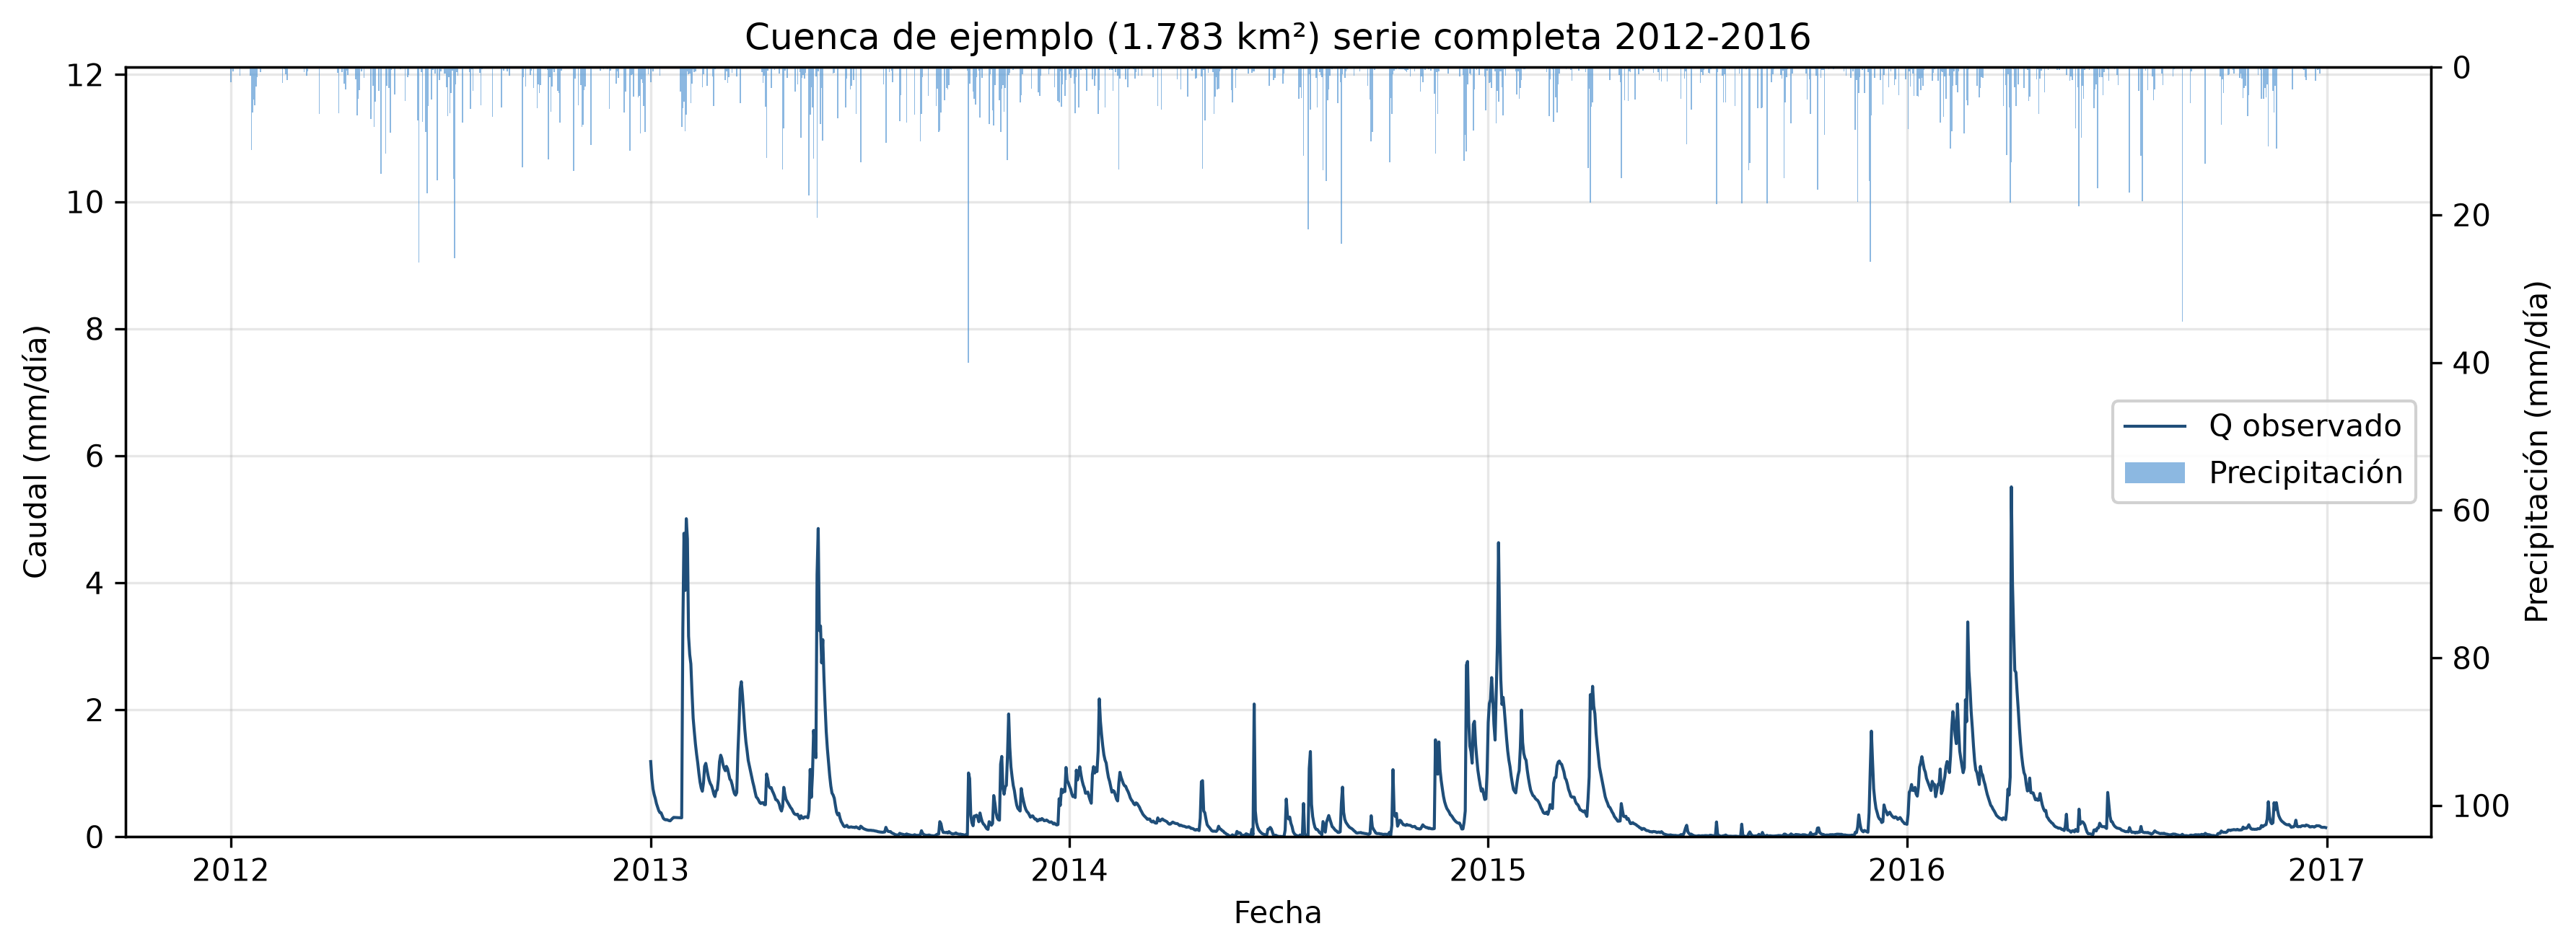

In [21]:
# Define una función que grafica el caudal y la precipitación sobre el mismo eje temporal.
def hietograma_hidrograma(datos, titulo="", ax=None):
    """Grafica caudal abajo y precipitación invertida arriba."""

    # Si no se recibe un eje, crea una figura de 12 × 4.5 pulgadas.
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 4.5))

    # Grafica el caudal como línea: lw controla el grosor y label identifica la serie.
    ax.plot(datos.index, datos["Q_mm"], color="#1f4e79", lw=1.0, label="Q observado")

    # Configura la etiqueta, los límites y el nombre del eje horizontal.
    ax.set_ylabel("Caudal (mm/día)")
    ax.set_ylim(0, datos["Q_mm"].max() * 2.2)
    ax.set_xlabel("Fecha")

    # Crea un segundo eje vertical que comparte las mismas fechas.
    axp = ax.twinx()

    # Grafica la precipitación como barras; alpha controla la transparencia.
    axp.bar(datos.index, datos["P_mm"], width=1.0, color="#5b9bd5", alpha=0.7, label="Precipitación")

    # Configura e invierte el eje de precipitación según la convención hidrológica.
    axp.set_ylabel("Precipitación (mm/día)")
    axp.invert_yaxis()
    axp.set_ylim(datos["P_mm"].max() * 2.6, 0)
    axp.grid(False)

    # Obtiene las series de ambos ejes y las reúne en una sola leyenda.
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = axp.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="center right", framealpha=0.9)

    # Agrega el título y devuelve el eje principal.
    ax.set_title(titulo)
    return ax


# Genera el hietograma e hidrograma para toda la serie 2012–2016.
hietograma_hidrograma(df, "Cuenca de ejemplo (1.783 km²) serie completa 2012-2016")

# Ajusta los espacios de la figura y la muestra.
plt.tight_layout()
plt.show()

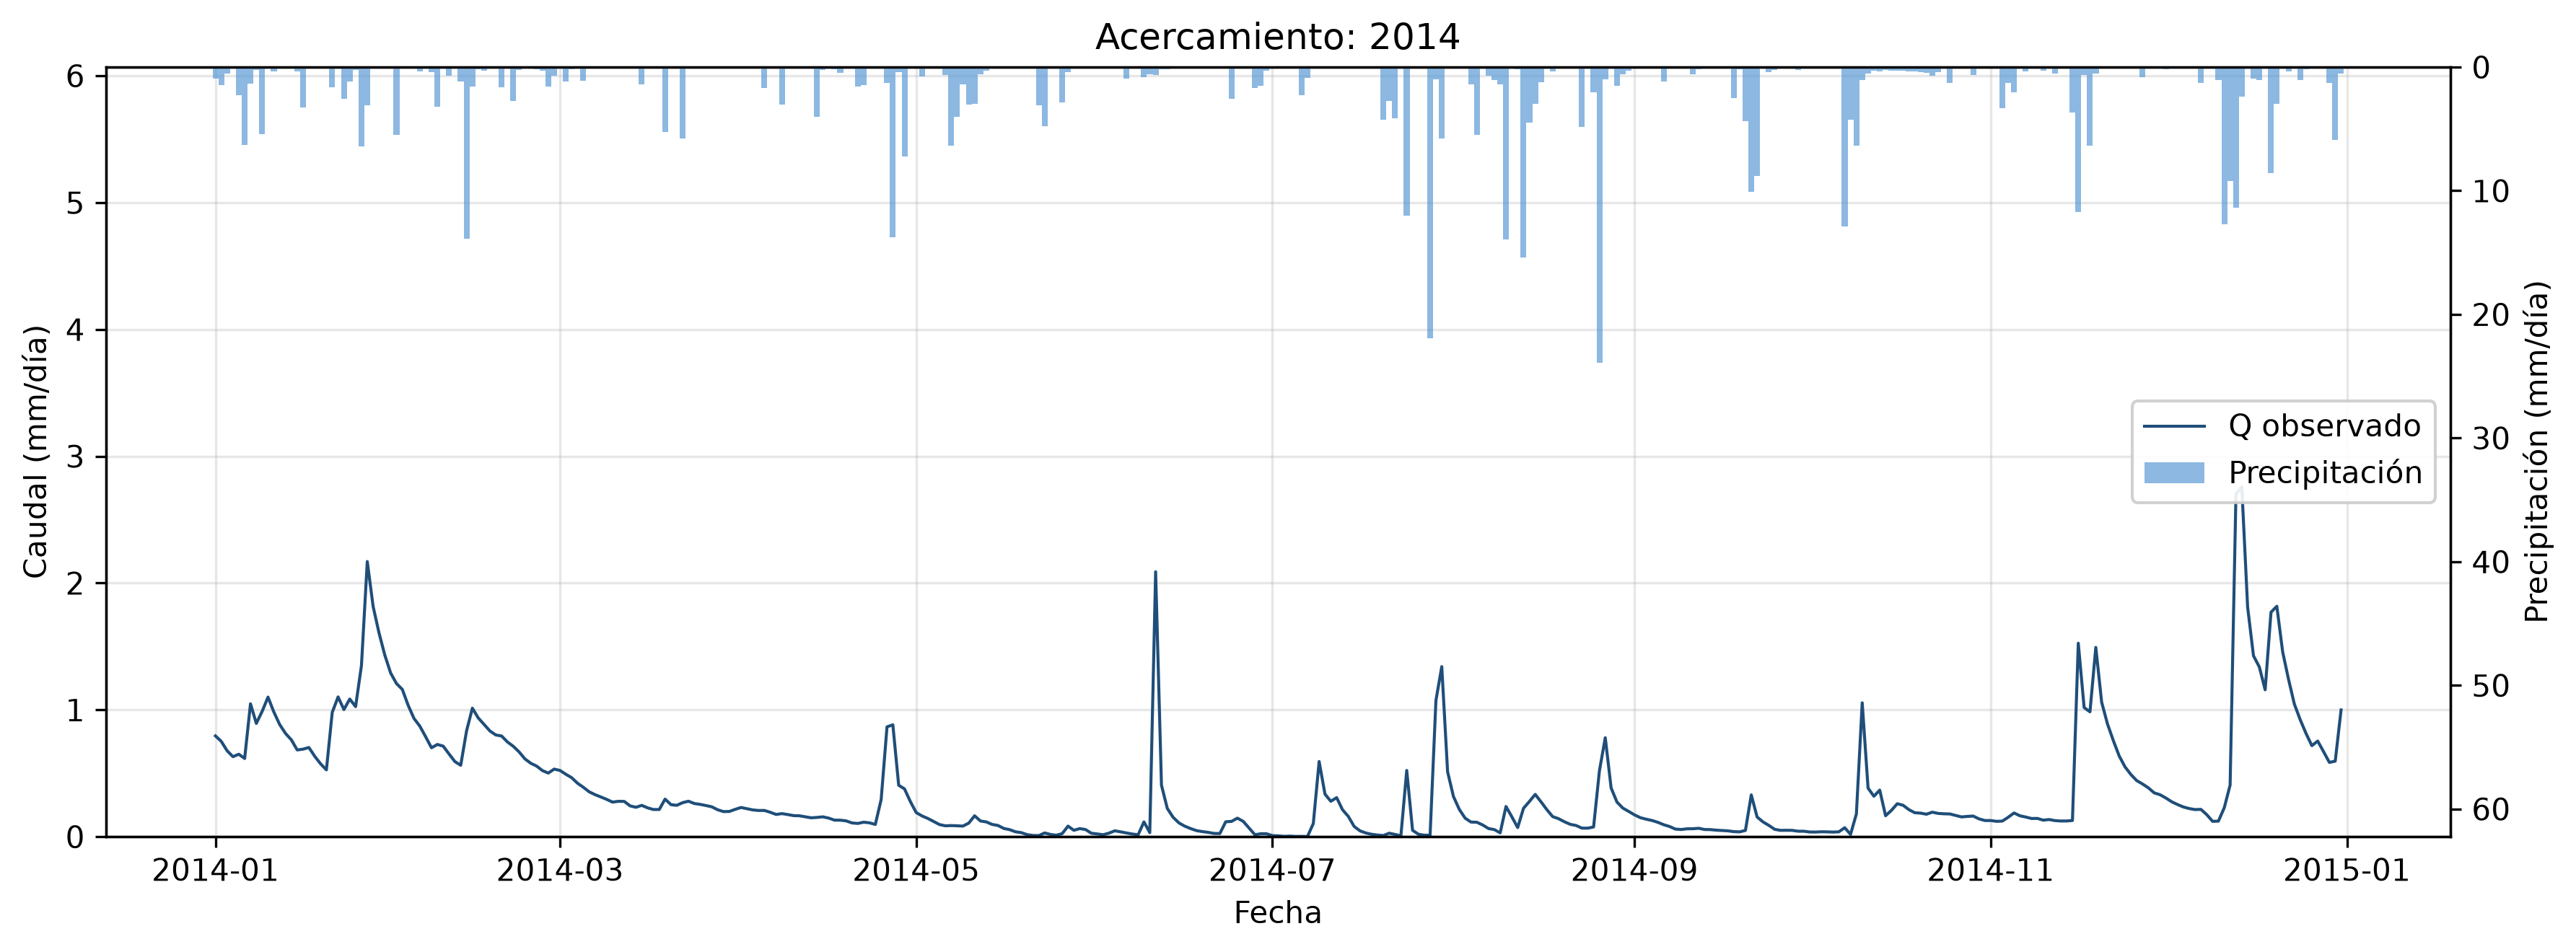

In [22]:
# Un acercamiento a un solo año deja ver la respuesta a eventos individuales
# loc["2014"] selecciona solamente los registros correspondientes al año 2014.
hietograma_hidrograma(df.loc["2014"], "Acercamiento: 2014")

# Ajusta los espacios de la figura y la muestra.
plt.tight_layout()
plt.show()

## 2.5 Curva de duración de caudales

La curva de duración responde a la siguiente pregunta. *¿Qué porcentaje del tiempo es excedido un caudal dado?* Es una de las formas más compactas de describir el régimen de una cuenca y va a reaparecer en la Parte 4, cuando discutamos qué favorece cada función objetivo. Su principal limitación es que se pierden los componentes de ocurrencia y duración consecutiva de eventos de interés hidrológico.

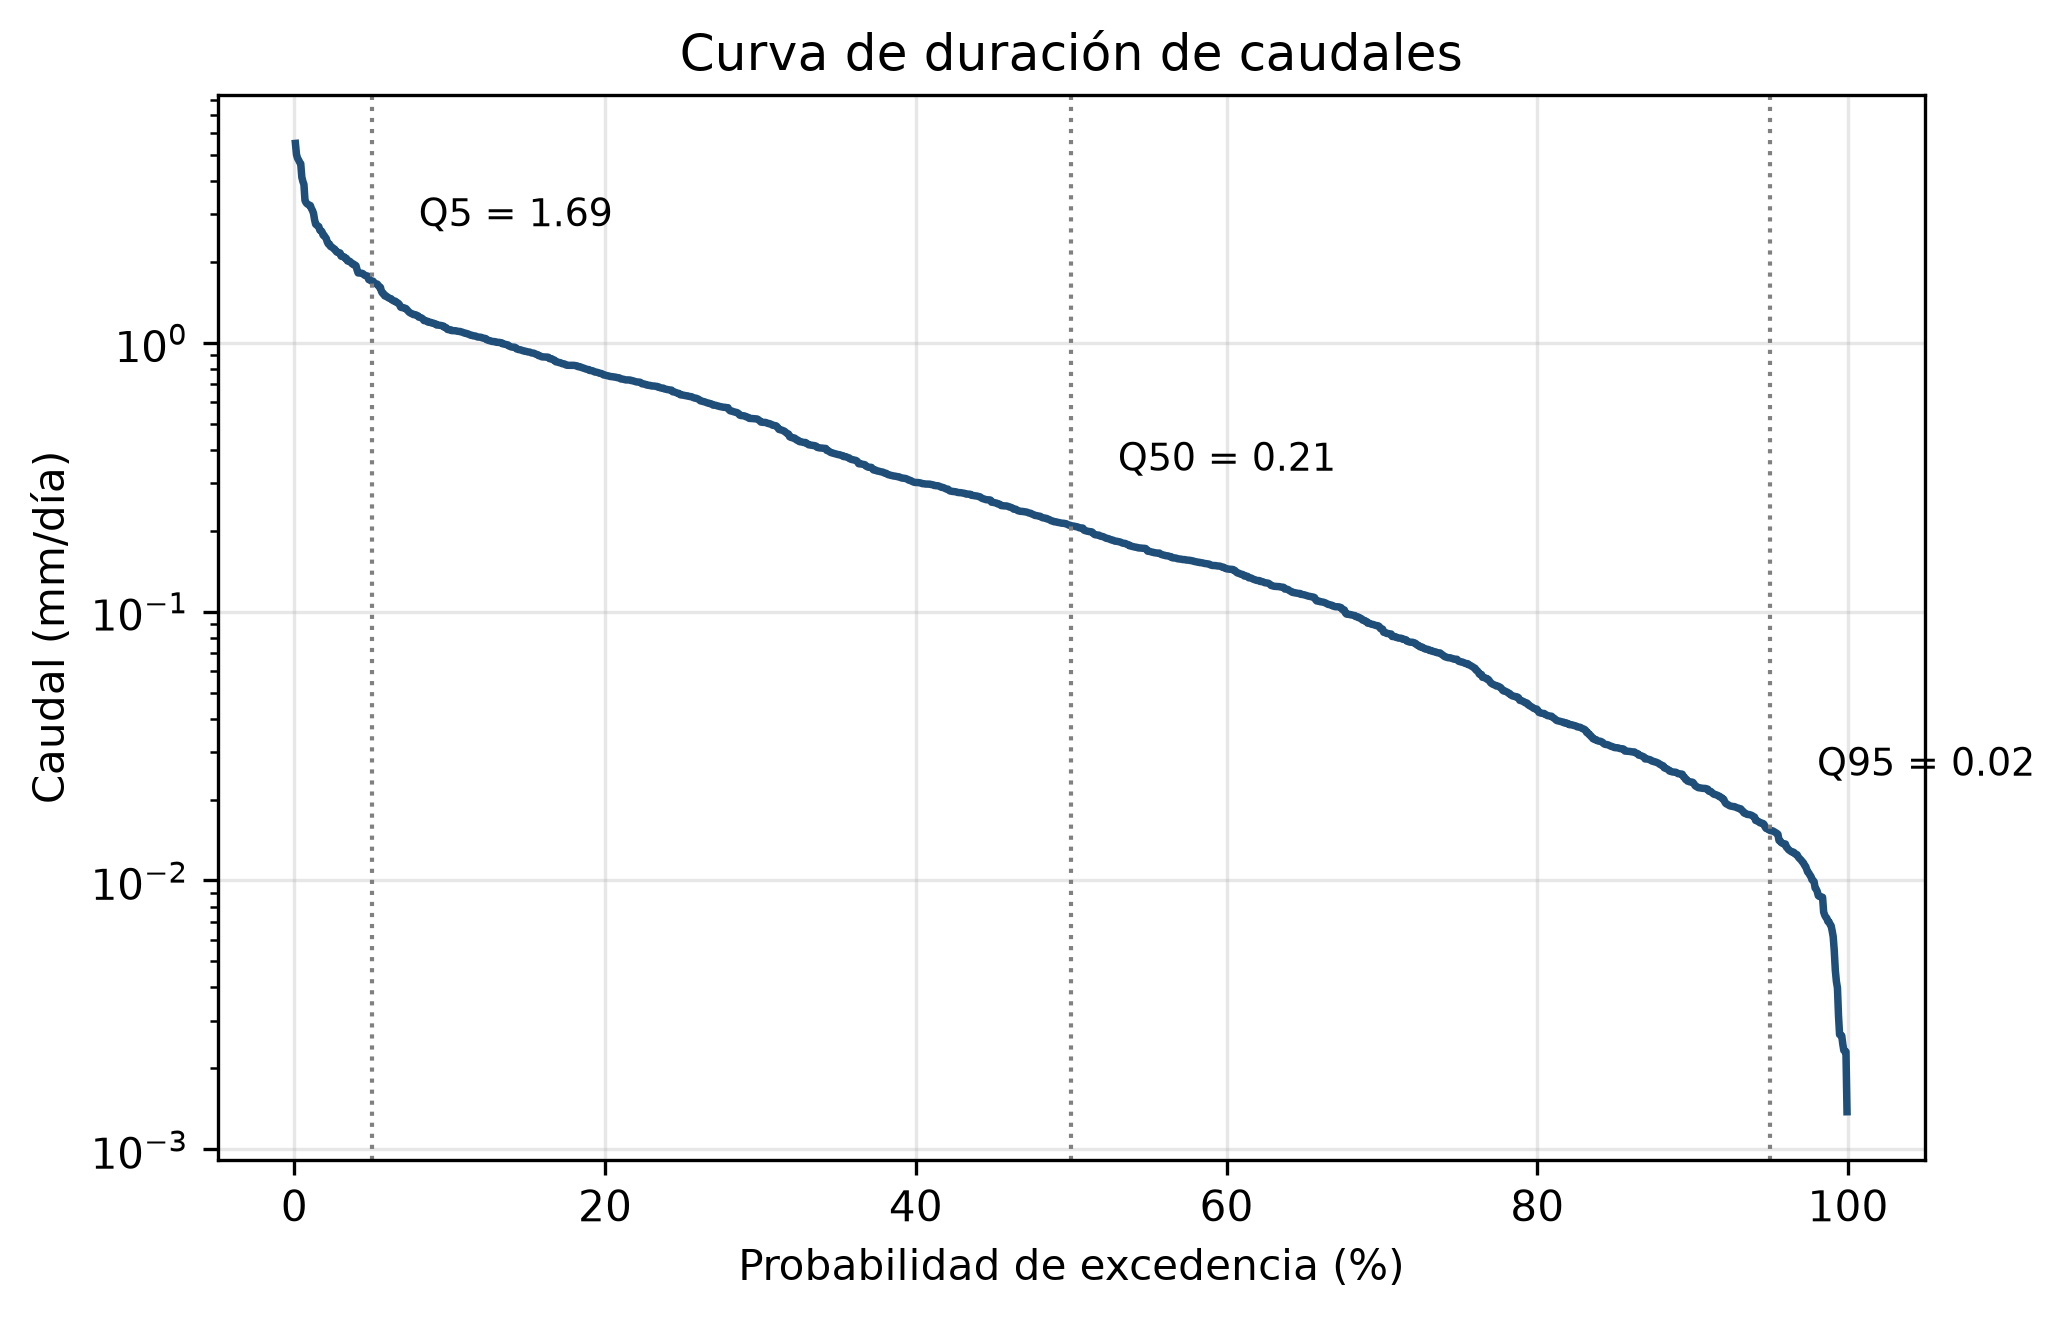

In [23]:
# Define una función que calcula la curva de duración de una serie de caudales.
def curva_duracion(Q):
    """Devuelve la probabilidad de excedencia (%) y los caudales ordenados."""

    # Convierte Q en arreglo, elimina NaN e infinitos, ordena de mayor a menor.
    # [::-1] invierte el orden ascendente producido por np.sort().
    q = np.sort(np.asarray(Q)[np.isfinite(Q)])[::-1]

    # Asigna a cada caudal su probabilidad empírica de ser igualado o superado.
    # np.arange(1, len(q) + 1) genera los rangos desde 1 hasta el total de datos.
    prob = np.arange(1, len(q) + 1) / (len(q) + 1) * 100

    # Devuelve las dos series calculadas.
    return prob, q


# Aplica la función al caudal observado expresado como lámina en mm/día.
prob, q = curva_duracion(df["Q_mm"])

# Crea la figura y el eje con dimensiones de 7 × 4.5 pulgadas.
fig, ax = plt.subplots(figsize=(7, 4.5))

# Grafica el caudal ordenado frente a su probabilidad de excedencia.
ax.plot(prob, q, color="#1f4e79", lw=1.8)

# Usa escala logarítmica para distinguir caudales altos y bajos.
ax.set_yscale("log")

# Define los nombres de los ejes y el título.
ax.set_xlabel("Probabilidad de excedencia (%)")
ax.set_ylabel("Caudal (mm/día)")
ax.set_title("Curva de duración de caudales")

# Recorre las probabilidades 5 %, 50 % y 95 %.
for p_ in (5, 50, 95):

    # Interpola el caudal correspondiente a cada probabilidad.
    v = np.interp(p_, prob, q)

    # Dibuja una línea vertical punteada en cada probabilidad.
    ax.axvline(p_, color="grey", ls=":", lw=1)

    # Identifica en la gráfica los valores Q5, Q50 y Q95.
    ax.annotate(f"Q{p_} = {v:.2f}", xy=(p_, v), xytext=(p_ + 3, v * 1.6), fontsize=9)

# Ajusta los espacios y muestra la gráfica.
plt.tight_layout()
plt.show()

---
## ✏️ Ejercicio 2: Particionar la serie

Antes de calibrar un modelo, hay que decidir **qué parte de la serie se usa para qué**. El protocolo separa
explícitamente el *conjunto para estimación de parámetros* (CAL) del *conjunto para prueba de
aceptabilidad* (ACE), y además necesitamos un período de **calentamiento** para que la condición inicial
supuesta (todos los almacenamientos en cero) no influya sobre los resultados.

Complete las tres fechas abajo. Criterios que debe respetar:

- El calentamiento debe cubrir, como mínimo, el período **sin datos de caudal**.
- Los dos períodos restantes deben ser **disjuntos** y de longitud razonable.
- Los tres juntos deben cubrir toda la serie disponible.

**Justifique su partición en la celda de texto que sigue.** No hay una única respuesta correcta, pero
sí hay respuestas indefendibles.

In [24]:
# ✏️ COMPLETE las tres fechas (formato "AAAA-MM-DD")

# Final del periodo utilizado para estabilizar los almacenamientos del modelo.
FIN_CALENTAMIENTO = "2012-12-31"

# Inicio del periodo utilizado para estimar los parámetros.
INICIO_CALIBRACION = "2013-01-01"

# Inicio del periodo independiente para probar la aceptabilidad.
INICIO_ACEPTABILIDAD = "2015-01-01"

# --- No modifique de aquí en adelante ---
for _nombre, _valor in [("FIN_CALENTAMIENTO", FIN_CALENTAMIENTO),
                        ("INICIO_CALIBRACION", INICIO_CALIBRACION),
                        ("INICIO_ACEPTABILIDAD", INICIO_ACEPTABILIDAD)]:
    assert _valor != "....", (
        f"Falta completar {_nombre}. Escriba una fecha en formato \"AAAA-MM-DD\" "
        "en las tres variables de arriba antes de correr esta celda.")

CAL  = slice(INICIO_CALIBRACION, pd.Timestamp(INICIO_ACEPTABILIDAD) - pd.Timedelta(days=1))
ACE  = slice(INICIO_ACEPTABILIDAD, str(df.index.max().date()))
# Período de evaluación = todo menos el calentamiento. Es el único sobre el que
# tiene sentido calcular balances y estadísticos del modelo.
EVAL = slice(INICIO_CALIBRACION, str(df.index.max().date()))

print(f"Calentamiento : {df.index.min().date()} -> {FIN_CALENTAMIENTO}   ({len(df.loc[:FIN_CALENTAMIENTO])} días)")
print(f"Calibración   : {CAL.start} -> {CAL.stop.date()}   ({len(df.loc[CAL])} días, "
      f"{df.loc[CAL,'Q_mm'].notna().sum()} con caudal observado)")
print(f"Aceptabilidad : {ACE.start} -> {ACE.stop}   ({len(df.loc[ACE])} días, "
      f"{df.loc[ACE,'Q_mm'].notna().sum()} con caudal observado)")
print(f"\nPeriodo de evaluación (calibración + aceptabilidad): {EVAL.start} -> {EVAL.stop}")

Calentamiento : 2012-01-01 -> 2012-12-31   (366 días)
Calibración   : 2013-01-01 -> 2014-12-31   (730 días, 730 con caudal observado)
Aceptabilidad : 2015-01-01 -> 2016-12-31   (731 días, 731 con caudal observado)

Periodo de evaluación (calibración + aceptabilidad): 2013-01-01 -> 2016-12-31


> ✏️ **Justificación (3–5 líneas):**

* Como revisamos en clase, Se toma 2012 (366 días) al calentamiento: aunque no existe caudal observado, la precipitación y la ET0 permiten que los almacenamientos internos del modelo evolucionen desde su condición inicial -artificial-.
Los cuatro años con caudal se dividieron en periodos consecutivos, sin superposición y de duración similar: 2013–2014 para CAL y 2015–2016 para ACE. 
CAL incluye el año más húmedo (2013) y el más seco (2014) del periodo evaluable, según la precipitación anual analizada en el ejercicio 2.3: 2013 (573,93 mm) y 2014 (458,29 mm). 
ACE se determina como prueba independiente para evaluar el modelo.


---
# Parte 3: HYMOD, del modelo conceptual al código

> **Protocolo:** cajas *Conceptualizar el modelo* y *Seleccionar o desarrollar el código*.

## 3.1 El modelo conceptual

HYMOD es un modelo **agregado** (toda la cuenca es una caja (o punto) que recibe unas entradas y devuelve una salida), **conceptual** (los almacenamientos no corresponden a volúmenes medibles) y de **paso diario**. Tiene dos bloques:

**Bloque 1, Producción de escorrentía.** La cuenca no se satura de golpe debido a que unas regiones o zonas se saturan
antes que otras. HYMOD representa eso con una *distribución de capacidades de almacenamiento*, en donde la
fracción de la cuenca con capacidad menor o igual a $c$ es

$$F(c) = 1 - \left(1 - \frac{c}{c_{max}}\right)^{b}, \qquad 0 \le c \le c_{max}$$

Con $b$ pequeño, la cuenca es casi homogénea. Con $b$ grande, hay mucha heterogeneidad y se genera
escorrentía desde el comienzo del evento. La capacidad de almacenamiento **promediada sobre la
cuenca** es $S_{max} = c_{max}/(b+1)$, que resulta de integrar $1-F(c)$ entre 0 y $c_{max}$. El máximo
puntual sigue siendo $c_{max}$, alcanzado solo en la fracción de la cuenca con mayor capacidad.

La evapotranspiración real se limita según la humedad disponible en el suelo,

$$ET_{real} = \min\!\left(\frac{S}{S_{max}}\;ET_0,\; S\right)$$

de donde se sigue que $ET_{real} \le ET_0$ y que el modelo nunca evapora más agua de la que tiene
almacenada.

> ### Tres términos que conviene no confundir
>
> **$ET_0$, evapotranspiración de referencia.** Definida por FAO-56 sobre un cultivo hipotético de
> características fijas (pasto de 0.12 m, resistencia superficial de 70 s m⁻¹, albedo de 0.23). Al estar
> especificada la superficie, es una variable puramente climática y por tanto reproducible.
>
> **$ETP$, evapotranspiración potencial.** Término histórico de Thornthwaite y Penman, que no fija la
> superficie de referencia y por eso resulta ambiguo. En modelación conceptual se conserva por
> costumbre para nombrar el forzamiento que representa la demanda atmosférica.
>
> **$ET_{real}$, evapotranspiración real.** Lo que efectivamente ocurre, limitado por el agua
> disponible en el suelo. Es lo que el modelo calcula.
>
> En este taller el forzamiento del modelo es siempre una $ET_0$, tanto en la cuenca de ejemplo
> (fórmula de Turc) como en las tres cuencas colombianas (fórmula de Hargreaves-Samani). La reducción
> $S/S_{max}$ cumple en HYMOD el papel que en agronomía cumplen los coeficientes de cultivo y de
> estrés hídrico.

**Bloque 2, Tránsito.** El exceso de precipitación se reparte de la siguiente forma. Una fracción $\alpha$ va a una cascada de **tres embalses lineales rápidos** (respuesta de crecientes) y la fracción $1-\alpha$ va a **un embalse lineal lento** (flujo base).

Un embalse lineal descarga en cada paso una fracción fija $K$ del agua disponible, y lo que queda almacenado es simplemente el resto:

$$O_t = K\,\bigl(S_{t-1} + I_t\bigr), \qquad
  S_t = \underbrace{S_{t-1} + I_t - O_t}_{\text{continuidad}} = (1-K)\,\bigl(S_{t-1} + I_t\bigr)$$

La segunda igualdad **es** la ecuación de conservación de la masa, es decir, lo que queda es lo que había, más lo que entró, menos lo que salió. Escrito así el balance de masa cierra de forma exacta en cada paso (y eso lo vamos a comprobar numéricamente en el Ejercicio 3).

> **Sobre la discretización, vale la pena leer esto con cuidado.**
> En la literatura este mismo embalse aparece escrito de dos maneras, y **no** son equivalentes:
>
> - **Implícita** (la de arriba; es la que usa HYMOD). La salida se calcula sobre el agua disponible
>   *después* de recibir el aporte del paso: $O_t = K\,(S_{t-1} + I_t)$, de donde
>   $S_t = (1-K)(S_{t-1}+I_t)$.
> - **Explícita.** La salida depende solo del almacenamiento al *inicio* del paso: $O_t = K\,S_{t-1}$,
>   de donde $S_t = I_t + (1-K)\,S_{t-1}$.
>
> Las dos conservan masa y difieren en el comportamiento. Con la implícita el tanque responde el
> mismo día en que recibe el agua; con la explícita responde al día siguiente. Para un paso diario y
> un $K$ pequeño la diferencia es menor, pero con $K$ grande (los tanques rápidos) no lo es.
>
> Lo que **no** conserva masa es mezclar las dos formas, esto es, escribir $S_t = I_t + (1-K)\,S_{t-1}$ y calcular la
> salida como $O_t = K\,S_t$. Ahí la salida se calcula sobre un almacenamiento al que nunca se le
> descontó esa misma salida. El desbalance de cada paso vale exactamente $K\,(S_t - S_{t-1})$, de modo que se
> cancela en buena parte a lo largo de la serie (el error acumulado termina siendo solo $K\,S_{final}$)
> pero **en un día concreto de ascenso del hidrograma puede ser del mismo orden que el caudal de ese
> día**, y con $K$ grande, varias veces mayor. Dicho de otro modo, el volumen total sale casi bien y el error se
> esconde justo donde importa, en los picos.
>
> Es un error fácil de cometer, imposible de ver en un hidrograma, y que solo se detecta verificando el
> balance de masa **paso a paso** (que es lo que haremos en el Ejercicio 3).

## 3.2 Los cinco parámetros

| Parámetro | Significado físico aproximado | Rango usual | Efecto si aumenta |
|---|---|---|---|
| `cmax`  | Capacidad máxima de almacenamiento de suelo (mm) | 1 – 500 | Más agua se retiene: menos escorrentía total |
| `b`     | Heterogeneidad espacial de esa capacidad (–) | 0.1 – 2.0 | Se genera escorrentía más temprano en el evento |
| `alpha` | Fracción del exceso que va al flujo rápido (–) | 0.1 – 0.99 | Picos más altos, recesiones más cortas |
| `Ks`    | Constante del embalse lento (–) | 0.001 – 0.10 | Flujo base se agota más rápido |
| `Kq`    | Constante de los embalses rápidos (–) | 0.1 – 0.99 | Picos más agudos y adelantados |

En la formulación discreta que usa este código, `Ks` y `Kq` son fracciones adimensionales del agua
disponible que cada embalse libera en un paso de tiempo, no constantes de recesión con unidades de
tiempo inverso. Los rangos de la tabla son los que trae el ejemplo de SPOTPY para esta cuenca, y no
son universales. En la Parte 6 la búsqueda se hará sobre un rango más amplio de `cmax`, porque las
cuencas colombianas son más grandes.

Conviene subrayar que estos parámetros son *conceptuales*. `cmax` no es una capacidad de campo que
usted pueda ir a medir en terreno. Se estiman calibrando, y por esa razón su interpretación física es limitada.

In [25]:
# Define el modelo lluvia–escorrentía HYMOD con paso de tiempo diario.
def hymod(P, ET0, cmax, b, alpha, Ks, Kq, devolver_estados=False):
    """Modelo lluvia-escorrentía HYMOD, paso diario, unidades en mm.

    Parámetros
    ----------
    P, ET0 : array de precipitación y de evapotranspiración de referencia (mm/día)
    cmax   : capacidad máxima de almacenamiento del suelo (mm)
    b      : exponente de la distribución de capacidades (-)
    alpha  : fracción del exceso que va al flujo rápido (-)
    Ks, Kq : constantes de los embalses lento y rápidos (1/día)

    Devuelve
    --------
    array de caudal simulado (mm/día), o un diccionario con los estados internos
    si devolver_estados=True.
    """

    # Convierte las entradas en arreglos numéricos y obtiene su longitud.
    P = np.asarray(P, dtype=float)
    ET0 = np.asarray(ET0, dtype=float)
    n = len(P)

    # Inicializa los arreglos donde se guardarán los resultados diarios.
    Qsim = np.zeros(n); ETr = np.zeros(n); Hs = np.zeros(n)
    Qrap = np.zeros(n); Qlen = np.zeros(n); Exc = np.zeros(n); Str = np.zeros(n)

    # Define en cero los almacenamientos iniciales del modelo.
    S = 0.0                       # Humedad del suelo (mm) <- condición inicial.
    S_lento = 0.0                # Almacenamiento del tanque lento.
    S_rapido = [0.0, 0.0, 0.0]  # Cascada de tres tanques rápidos.

    # Calcula la capacidad media máxima de almacenamiento de la cuenca.
    S_max = cmax / (b + 1.0)

    # Recorre la serie diaria de precipitación y ET0.
    for t in range(n):

        # 1) Producción de escorrentía -----------------------------------

        # Obtiene la capacidad equivalente asociada a la humedad antecedente.
        c_ant = cmax * (1.0 - max(1.0 - S / S_max, 0.0) ** (1.0 / (b + 1.0)))

        # Calcula el exceso generado cuando se supera la capacidad máxima.
        ER1 = max(P[t] - cmax + c_ant, 0.0)

        # Determina la precipitación que todavía puede ingresar al suelo.
        Pn = P[t] - ER1

        # Calcula la fracción de capacidad alcanzada después de la lluvia.
        frac = min((c_ant + Pn) / cmax, 1.0)

        # Actualiza el almacenamiento medio antes de la evapotranspiración.
        S_nuevo = S_max * (1.0 - (1.0 - frac) ** (b + 1.0))

        # Calcula el exceso asociado a la saturación parcial de la cuenca.
        ER2 = max(Pn - (S_nuevo - S), 0.0)

        # 2) Evapotranspiración real, limitada por la humedad -------------

        # Limita la ET real por la humedad y por el agua almacenada.
        et = min((S_nuevo / S_max) * ET0[t], S_nuevo)

        # Descuenta la ET real del almacenamiento del suelo.
        S = max(S_nuevo - et, 0.0)

        # 3) Reparto rápido / lento --------------------------------------

        # Suma los excesos producidos por saturación total y parcial.
        exceso = ER1 + ER2

        # Reparte el exceso entre las rutas rápida y lenta.
        U_rapido = alpha * exceso
        U_lento = (1.0 - alpha) * exceso

        # 4) Tránsito por embalses lineales ------------------------------

        # De cada tanque sale una fracción K del agua disponible;
        # lo que no sale permanece almacenado.
        disponible = S_lento + U_lento
        q_lento = Ks * disponible
        S_lento = disponible - q_lento

        # La salida de cada tanque rápido alimenta al siguiente.
        entrada = U_rapido
        for i in range(3):
            disponible = S_rapido[i] + entrada
            entrada = Kq * disponible
            S_rapido[i] = disponible - entrada

        # La salida del tercer tanque corresponde al flujo rápido.
        q_rapido = entrada

        # Suma los componentes rápido y lento del caudal simulado.
        Qsim[t] = q_lento + q_rapido

        # Guarda los estados y flujos calculados durante el día.
        ETr[t] = et; Hs[t] = S; Qrap[t] = q_rapido; Qlen[t] = q_lento; Exc[t] = exceso

        # Registra el agua que permanece en los tanques de tránsito.
        Str[t] = S_lento + sum(S_rapido)

    # Devuelve el diagnóstico completo cuando se solicitan los estados.
    if devolver_estados:
        return {"Q": Qsim, "ET": ETr, "humedad_suelo": Hs, "almacen_transito": Str,
                "Q_rapido": Qrap, "Q_lento": Qlen, "exceso": Exc, "S_max": S_max}

    # En el uso normal devuelve solamente el caudal simulado.
    return Qsim


# Confirma que la función quedó definida correctamente.
print("HYMOD listo.")

HYMOD listo.


## 3.3 Primera corrida

Antes de calibrar el modelo, se debe correr con un conjunto de parámetros **a priori** (valores razonables
tomados de la literatura o de cuencas parecidas) y se debe evalúar la respuesta. Esto es lo que el protocolo llama
*ejercicios preliminares de cuantificación, para comenzar a sentir la respuesta del caso de estudio*.

In [26]:
# Define un conjunto inicial de parámetros tomado como punto de partida.
# Estos valores son a priori: todavía no han sido calibrados con esta serie.
PAR_INICIAL = dict(cmax=412.33, b=0.173, alpha=0.813, Ks=0.040, Kq=0.559)

# Ejecuta HYMOD con las entradas diarias de precipitación y ET0.
# **PAR_INICIAL entrega a la función los cinco parámetros del diccionario.
# El operador ** desempaqueta y entrega a HYMOD los cinco parámetros del diccionario.
# devolver_estados=True solicita también los flujos y almacenamientos internos.
salida = hymod(df["P_mm"].values, df["ET0_mm"].values, **PAR_INICIAL, devolver_estados=True)

# Incorpora al DataFrame el caudal simulado expresado en mm/día.
df["Q_sim"] = salida["Q"]

# Presenta los parámetros utilizados y el almacenamiento medio máximo calculado.
print("Parámetros a priori:", PAR_INICIAL)
print(f"S_max = {salida['S_max']:.1f} mm")

# Selecciona los mismos días para comparar el caudal observado y el simulado.
# Se excluye el calentamiento y se eliminan días sin alguna de las dos series.
comp = dias_comparables(df, ["Q_mm", "Q_sim"], EVAL)

# Informa el periodo comparable y los caudales medios de ambas series.
print(f"\nComparando sobre {len(comp)} días ({comp.index.min().date()} a {comp.index.max().date()})")
print(f"Q observado medio  : {comp['Q_mm'].mean():.3f} mm/día")
print(f"Q simulado medio   : {comp['Q_sim'].mean():.3f} mm/día")

Parámetros a priori: {'cmax': 412.33, 'b': 0.173, 'alpha': 0.813, 'Ks': 0.04, 'Kq': 0.559}
S_max = 351.5 mm

Comparando sobre 1461 días (2013-01-01 a 2016-12-31)
Q observado medio  : 0.456 mm/día
Q simulado medio   : 0.326 mm/día


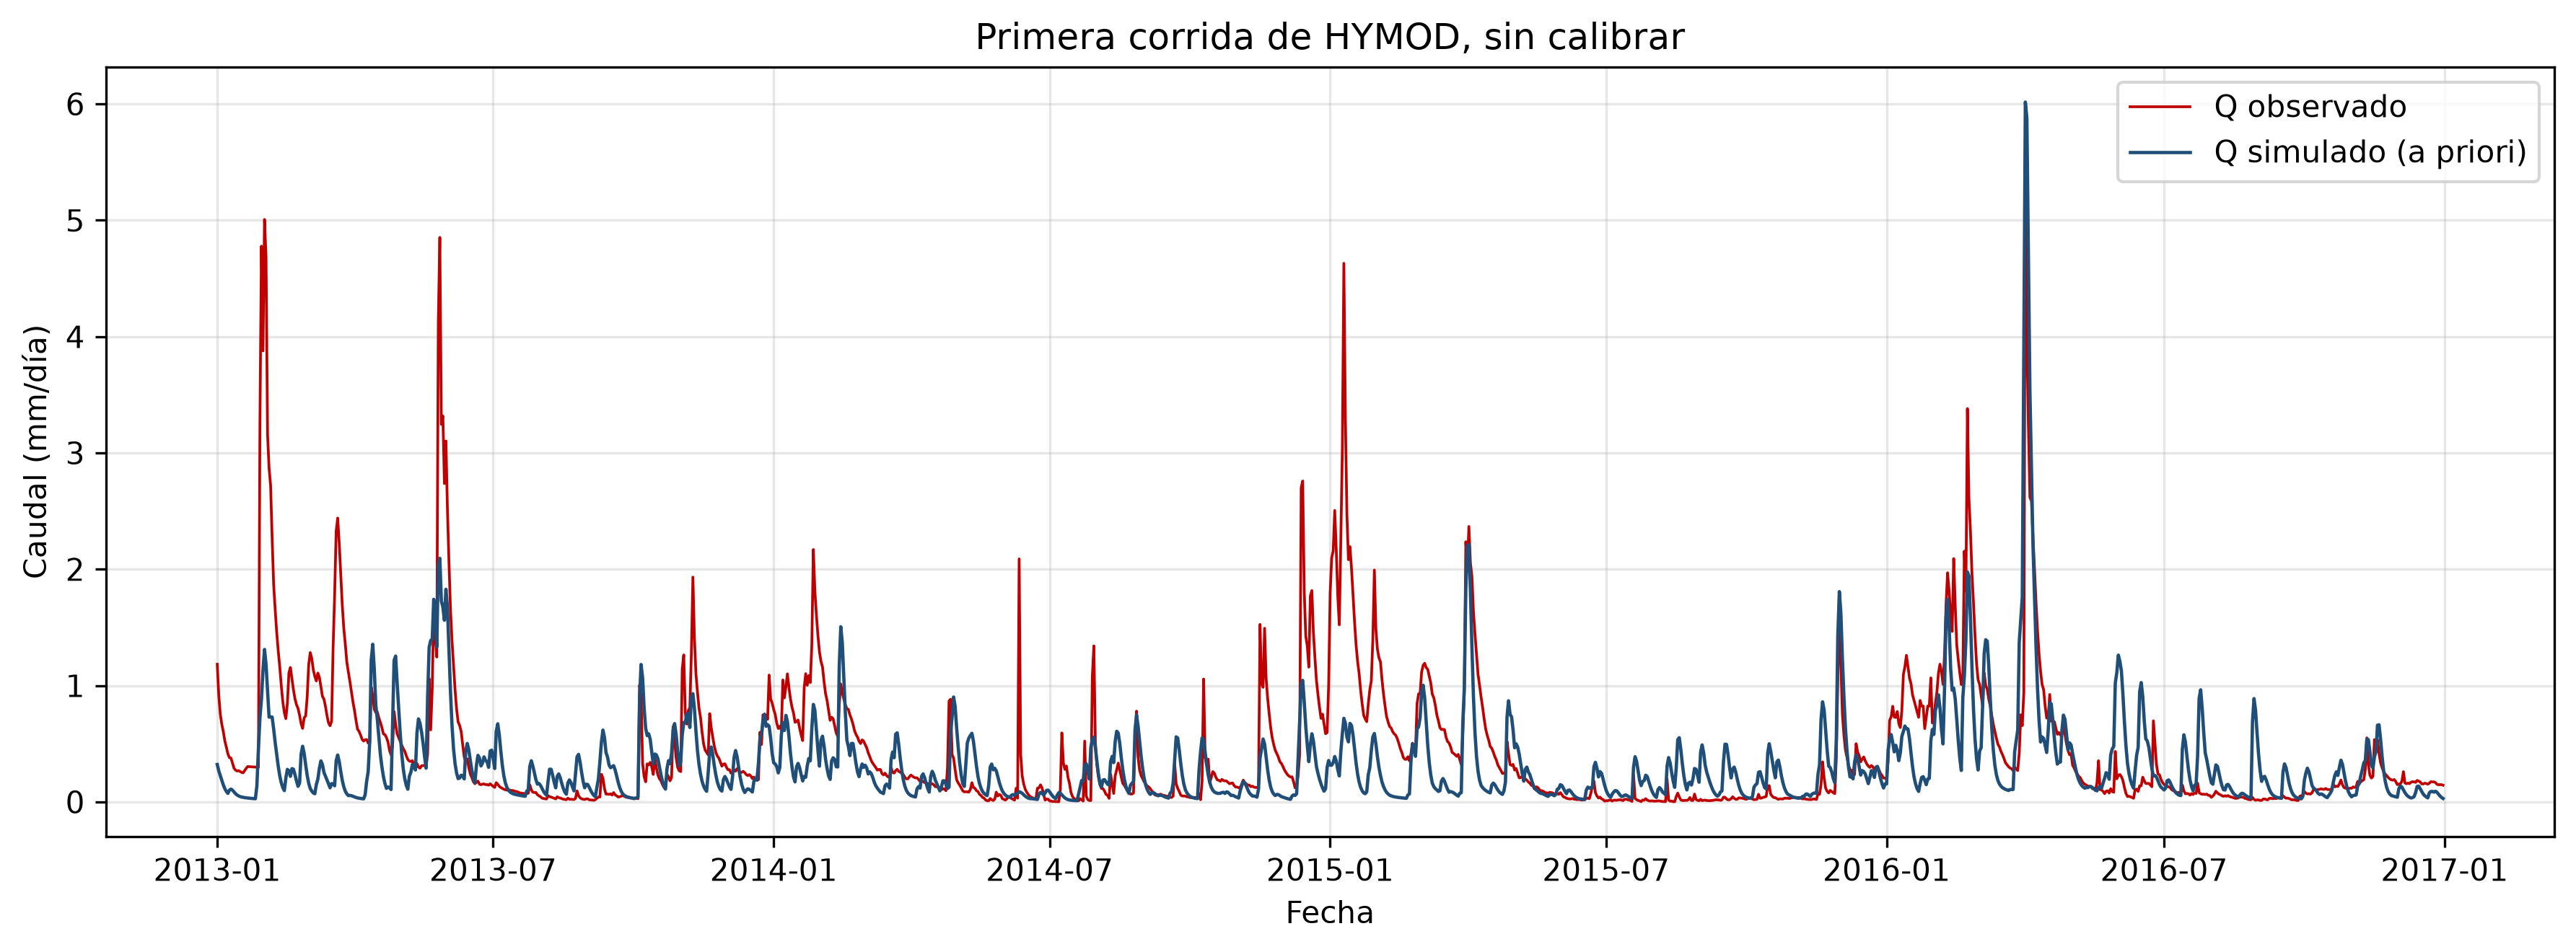

In [27]:
# Crea la figura donde se compararán ambos hidrogramas.
fig, ax = plt.subplots(figsize=(12, 4.5))

# Selecciona el periodo desde 2013, excluyendo el calentamiento de 2012.
d = df.loc["2013":]

# Grafica el caudal observado en rojo.
ax.plot(d.index, d["Q_mm"], color="#c00000", lw=0.9, label="Q observado")

# Grafica en azul el caudal simulado con los parámetros a priori.
ax.plot(d.index, d["Q_sim"], color="#1f4e79", lw=1.1, label="Q simulado (a priori)")

# Configura los ejes, el título y la leyenda.
ax.set_ylabel("Caudal (mm/día)"); ax.set_xlabel("Fecha")
ax.set_title("Primera corrida de HYMOD, sin calibrar")
ax.legend()

# Ajusta los espacios y presenta la figura.
plt.tight_layout(); plt.show()

## 3.4 Mirar por dentro del modelo

Un hidrograma de salida no dice si el modelo está funcionando por las razones correctas. Los estados
internos sí. Estas tres gráficas son la traducción directa de los puntos 5 a 8 de la diapositiva de
credibilidad del protocolo.

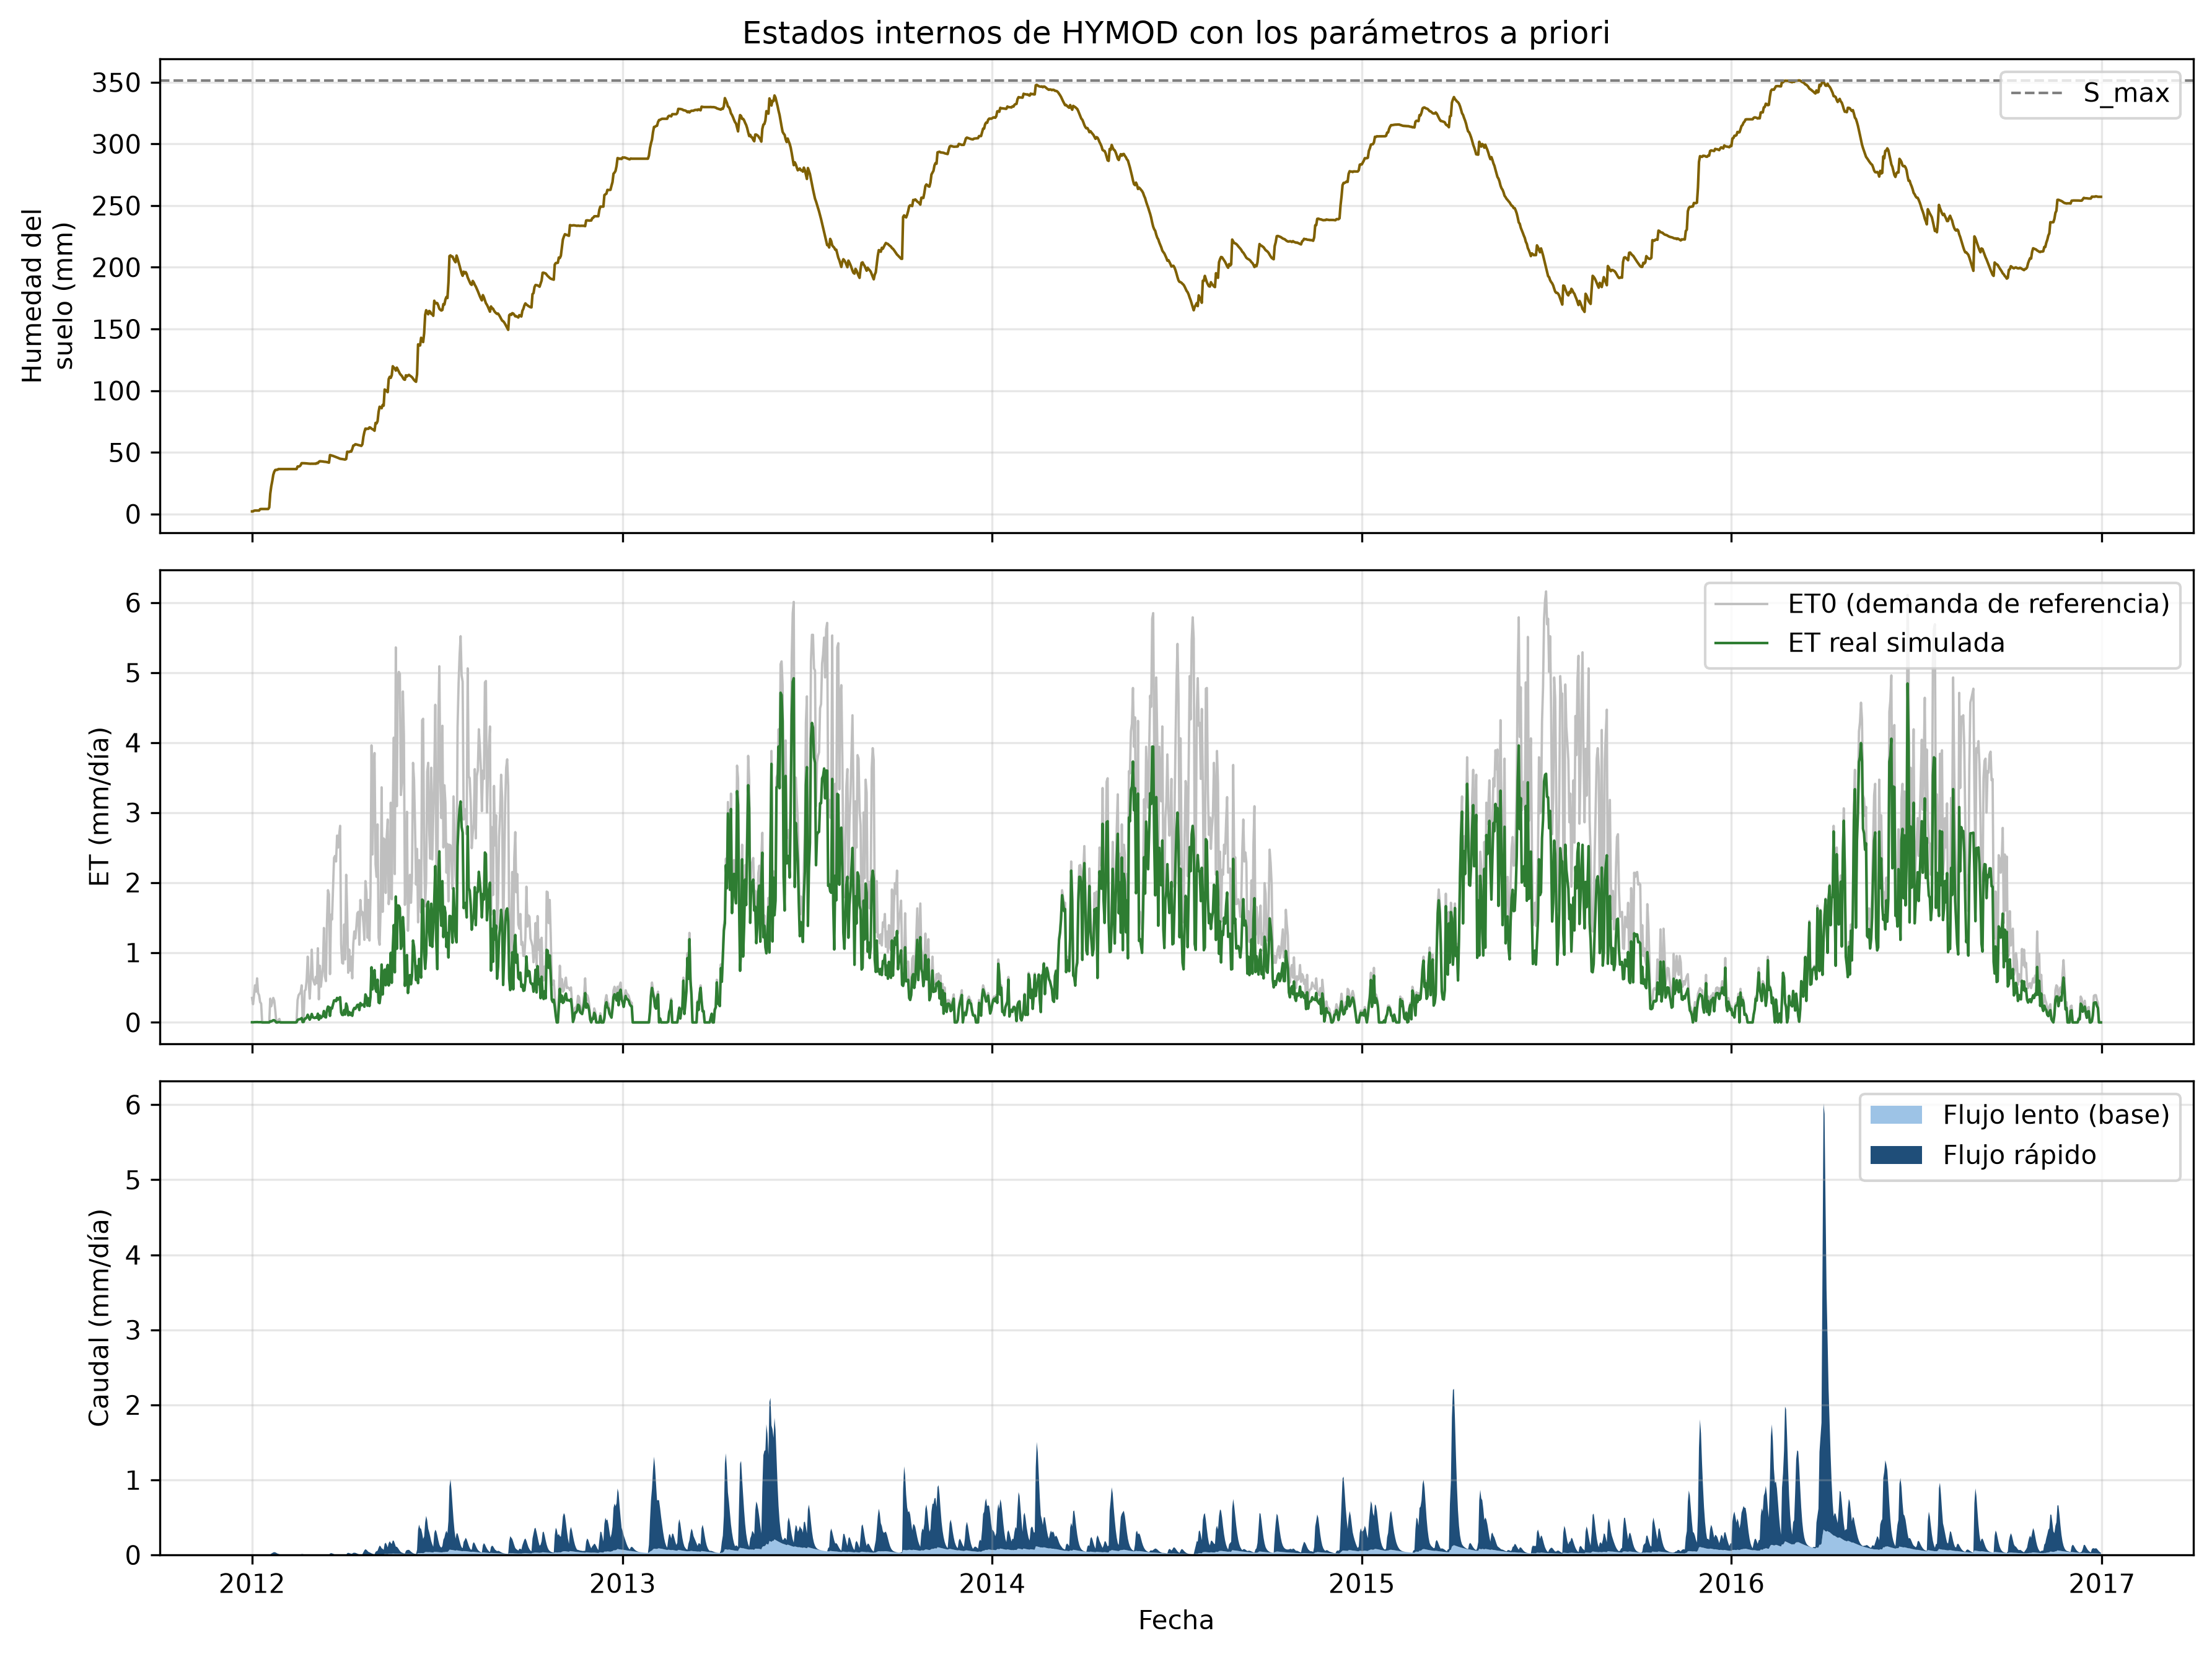

In [28]:
# Organiza en un DataFrame los estados y flujos internos devueltos por HYMOD.
# Se conserva el mismo índice diario utilizado en la serie original.
estados = pd.DataFrame({

    # Agua almacenada en el bloque conceptual del suelo.
    "humedad_suelo": salida["humedad_suelo"],

    # Suma del agua que permanece en los tres tanques rápidos y el tanque lento.
    "almacen_transito": salida["almacen_transito"],

    # Evapotranspiración real calculada según la humedad disponible.
    "ET_real": salida["ET"],

    # Componentes rápido y lento del caudal simulado.
    "Q_rapido": salida["Q_rapido"],
    "Q_lento": salida["Q_lento"],

}, index=df.index)

# Crea tres gráficas verticales que comparten el mismo eje temporal.
fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

# Primera gráfica: humedad almacenada en el suelo.
axs[0].plot(estados.index, estados["humedad_suelo"], color="#7f6000", lw=1)

# Dibuja como referencia la capacidad media máxima S_max.
axs[0].axhline(salida["S_max"], color="grey", ls="--", lw=1, label="S_max")

# Configura la etiqueta, leyenda y título del primer panel.
axs[0].set_ylabel("Humedad del\nsuelo (mm)"); axs[0].legend(loc="upper right")
axs[0].set_title("Estados internos de HYMOD con los parámetros a priori")

# Segunda gráfica: compara la demanda atmosférica ET0 con la ET real simulada.
axs[1].plot(df.index, df["ET0_mm"], color="#bfbfbf", lw=0.9,
            label="ET0 (demanda de referencia)")
axs[1].plot(estados.index, estados["ET_real"], color="#2e7d32", lw=1.0,
            label="ET real simulada")

# Configura la etiqueta y la leyenda del segundo panel.
axs[1].set_ylabel("ET (mm/día)"); axs[1].legend(loc="upper right")

# Tercera gráfica: presenta apilados los componentes lento y rápido.
# La altura total del área corresponde al caudal simulado Q_sim.
axs[2].stackplot(estados.index, estados["Q_lento"], estados["Q_rapido"],
                 labels=["Flujo lento (base)", "Flujo rápido"],
                 colors=["#9dc3e6", "#1f4e79"])

# Configura las etiquetas y la leyenda del tercer panel.
axs[2].set_ylabel("Caudal (mm/día)"); axs[2].set_xlabel("Fecha")
axs[2].legend(loc="upper right")

# Ajusta los espacios y muestra la figura completa.
plt.tight_layout(); plt.show()

---
## ✏️ Ejercicio 3: Coherencia interna

La celda siguiente calcula tres verificaciones. **Córrala y luego responda.**

In [29]:
# Las verificaciones se realizan sobre el periodo de evaluación.
# Se excluye 2012 porque durante el calentamiento los almacenamientos
# parten artificialmente de cero y se encuentran en proceso de llenado.
ev = df.loc[EVAL]
est = estados.loc[EVAL]

# El almacenamiento inicial de la evaluación corresponde al valor
# existente al terminar el día anterior, es decir, al final del calentamiento.
# shift(1) desplaza la serie un día para recuperar ese estado inicial.
S0_suelo = estados["humedad_suelo"].shift(1).loc[EVAL].iloc[0]
S0_transito = estados["almacen_transito"].shift(1).loc[EVAL].iloc[0]

# Calcula las entradas y salidas acumuladas durante 2013–2016.
P_tot = ev["P_mm"].sum()
ET_tot = est["ET_real"].sum()
Q_tot = ev["Q_sim"].sum()

# Calcula el cambio entre los almacenamientos iniciales y finales.
dS_suelo = est["humedad_suelo"].iloc[-1] - S0_suelo
dS_transito = est["almacen_transito"].iloc[-1] - S0_transito

# Presenta el periodo utilizado en todas las comprobaciones.
print(f"Período evaluado: {ev.index.min().date()} a {ev.index.max().date()}  ({len(ev)} días)")
print("(el calentamiento queda fuera de todos los números que siguen)\n")

# VERIFICACIÓN 1: BALANCE DE MASA -------------------------------

# Presenta entradas, salidas y cambios de almacenamiento.
print("--- Verificación 1: balance de masa del modelo ---")
print(f"Entradas   P                    = {P_tot:10.2f} mm")
print(f"Salidas    ET                   = {ET_tot:10.2f} mm")
print(f"           Q                    = {Q_tot:10.2f} mm")
print(f"Almacena.  dS suelo             = {dS_suelo:10.2f} mm   "
      f"(de {S0_suelo:.1f} a {est['humedad_suelo'].iloc[-1]:.1f} mm)")
print(f"           dS tanques tránsito  = {dS_transito:10.2f} mm   "
      f"(de {S0_transito:.1f} a {est['almacen_transito'].iloc[-1]:.1f} mm)")
print(f"{'-'*46}")

# Comprueba la ecuación P = ET + Q + ΔS_suelo + ΔS_tránsito.
residual = P_tot - ET_tot - Q_tot - dS_suelo - dS_transito
print(f"Residual   P - ET - Q - dS     = {residual:10.2e} mm")
print("   Debe ser cero salvo error de redondeo. Si no lo es, el código del")
print("   modelo está creando o destruyendo agua, y nada de lo que siga sirve.")

# VERIFICACIÓN 2: RESTRICCIÓN DE LA ET REAL --------------------

# Comprueba que la ET real nunca supere la demanda de referencia ET0.
# La tolerancia 1e-9 evita identificar como error una diferencia
# extremadamente pequeña producida por precisión numérica.
print("\n--- Verificación 2. La ET real no puede superar la demanda de referencia ---")
print(f"Días en que ET_real > ET0: {(est['ET_real'] > ev['ET0_mm'] + 1e-9).sum()}")

# Compara la ET real acumulada con la ET0 acumulada.
print(f"Relación ET_real / ET0 (media): {ET_tot / ev['ET0_mm'].sum():.2f}")

# VERIFICACIÓN 3: ÍNDICE DE FLUJO BASE -------------------------

# Calcula qué fracción del caudal simulado procede del tanque lento.
print("\n--- Verificación 3: índice de flujo base simulado ---")
print(f"Fracción del caudal que sale por el embalse lento: "
      f"{est['Q_lento'].sum() / Q_tot:.2f}")

# VERIFICACIÓN 4: COMPARACIÓN CON EL RESIDUO OBSERVADO ---------

# Conserva los días del periodo de evaluación que tienen datos comparables.
obs = dias_comparables(df, ["P_mm", "ET0_mm", "Q_mm"], EVAL)

# Compara P-Q observado con la ET real simulada.
# El residuo P-Q no es una medición directa de evapotranspiración.
print("\n--- Verificación 4: el modelo contra el residuo del balance ---")
print(f"Sobre los {len(obs)} días con caudal observado dentro del período de evaluación:")
print(f"   residuo del balance (P - Q_obs) = {obs['P_mm'].mean() - obs['Q_mm'].mean():.3f} mm/día")
print(f"   ET simulada por el modelo       = {est.loc[obs.index, 'ET_real'].mean():.3f} mm/día")
print("   Recuerde la sección 2.3: el residuo no es una medición de ET, así que esta")
print("   comparación detecta discrepancias pero no arbitra cuál de los dos está mal.")

Período evaluado: 2013-01-01 a 2016-12-31  (1461 días)
(el calentamiento queda fuera de todos los números que siguen)

--- Verificación 1: balance de masa del modelo ---
Entradas   P                    =    2093.07 mm
Salidas    ET                   =    1648.95 mm
           Q                    =     476.43 mm
Almacena.  dS suelo             =     -30.64 mm   (de 287.7 a 257.1 mm)
           dS tanques tránsito  =      -1.67 mm   (de 2.1 a 0.4 mm)
----------------------------------------------
Residual   P - ET - Q - dS     =  -4.95e-12 mm
   Debe ser cero salvo error de redondeo. Si no lo es, el código del
   modelo está creando o destruyendo agua, y nada de lo que siga sirve.

--- Verificación 2. La ET real no puede superar la demanda de referencia ---
Días en que ET_real > ET0: 0
Relación ET_real / ET0 (media): 0.71

--- Verificación 3: índice de flujo base simulado ---
Fracción del caudal que sale por el embalse lento: 0.19

--- Verificación 4: el modelo contra el residuo del bal

> ✏️ **Respuesta 3.**
>
> **3a.** ¿La verificación 2 se cumple? Explique en una línea por qué el modelo *no puede*
> producir `ET_real > ET0`, mirando la línea del código donde se calcula `et`.
>
> * Sí cumple. La expresión min((S_nuevo/S_max) *ET0[t], S_nuevo), selecciona el menor entre valor_1 (Snuevo/Smax *ETo) y valor_2 (Snuevo), que corresponden a  la relación matematica de la formula ETr=min(S/Smax *ETo, s), en resumen, el modelo revisa no sacar más agua de la que dispone - ETreal es la menor entre la ET permitida por humedad y agua existente*; 
>
> **3b.** Compare la fracción de flujo base **simulada** (verificación 3) con lo que sugiere el
> hidrograma **observado** de la Parte 2. ¿Le parece que el modelo está repartiendo bien el agua entre
> flujo rápido y flujo base? ¿Qué parámetro tocaría para corregirlo?
>
> * HYMOD, divide el exceso de lluvia, en dos rutas; una rapida lleva el agua rápidamente a cuerpos de agua -rios-, y produce picos*
* la otra ruta almacena y libera lentamente, manteniendo el río entre lluvias, esta relación la explica la variable alpha, donde alpha=0.813, luego 81.3% va por vía rapida, y el excedente, aprox. 19% va por ruta lenta. los parametros alpha, Kq, y Ks, son determinados inicialmente, En este ejercicio, la fracción lenta es solo 19 %. Por eso, para corregir inicialmente el reparto de volumen, el parámetro más directo es alpha. Después se utilizarían Ks y Kq para ajustar la forma temporal de las rutas lenta y rápida.*
* Poco flujo base → revisar primero alpha. _ Flujo base que desaparece demasiado rápido → revisar Ks. _ Picos demasiado agudos, bajos, altos o retrasados → revisar Kq y también alpha.*

---
# Parte 4 · Criterios de desempeño aceptable

> **Protocolo:** caja *Determinar criterios de desempeño aceptable*.

Una función objetivo (FO) resume en un número la distancia entre lo simulado y lo observado. El punto
de esta parte es que **no existe una única FO correcta**, dado que cada una favorece un aspecto distinto, y elegir cuál
usar es una decisión de modelación tan importante como elegir el modelo.

## 4.1 Las cinco funciones objetivo del taller

$$NSE = 1 - \frac{\sum (Q_{sim} - Q_{obs})^2}{\sum (Q_{obs} - \overline{Q_{obs}})^2}
\qquad\text{(1 es perfecto; 0 equivale a usar la media observada)}$$

$$KGE = 1 - \sqrt{(r-1)^2 + (\beta-1)^2 + (\gamma-1)^2}$$

donde $r$ es la correlación, $\beta = \overline{Q_{sim}}/\overline{Q_{obs}}$ el sesgo de volumen y
$\gamma$ la relación de coeficientes de variación (Gupta et al., 2009). El KGE resulta útil porque
**separa** esos tres errores en lugar de mezclarlos.

> **Los dos índices no comparten escala.** Un modelo que responda siempre con la media observada
> obtiene $NSE = 0$, pero $KGE = 1-\sqrt{2} \approx -0.41$ (Knoben et al., 2019). Comparar un NSE de
> 0.43 con un KGE de 0.37 como si fueran equivalentes induce a error. Cada índice se interpreta contra
> su propio referente.

$$PBIAS = 100\,\frac{\sum (Q_{sim} - Q_{obs})}{\sum Q_{obs}}
\qquad\text{(negativo = el modelo subestima el volumen)}$$

El **logNSE** es el NSE calculado sobre $\log Q$, de modo que comprime los picos y amplifica los caudales bajos,
así que mide qué tan bien se reproduce el estiaje. El **RMSE** está en las unidades del caudal, lo que
lo hace fácil de interpretar pero dificulta comparar entre cuencas.

In [30]:
# Elimina los días en los que falta el caudal observado o simulado.
# Las métricas solo deben comparar pares de datos correspondientes al mismo día.
def _limpiar(obs, sim):
    """Descarta los días sin observacion. Toda FO debe hacer esto primero."""

    # Convierte ambas series en arreglos numéricos.
    obs = np.asarray(obs, dtype=float); sim = np.asarray(sim, dtype=float)

    # isfinite identifica valores numéricos válidos y excluye NaN e infinitos.
    # El operador & exige que ambas series tengan información el mismo día.
    m = np.isfinite(obs) & np.isfinite(sim)

    # Devuelve únicamente los pares de días comparables.
    return obs[m], sim[m]


# Calcula la eficiencia de Nash-Sutcliffe.
# Penaliza fuertemente las diferencias grandes y, por tanto, los errores en picos.
def nse(obs, sim):
    o, s = _limpiar(obs, sim)

    # Compara el error del modelo con la variabilidad del caudal observado.
    return 1 - np.sum((s - o) ** 2) / np.sum((o - o.mean()) ** 2)


# Calcula NSE después de transformar los caudales mediante logaritmos.
# Esta transformación reduce el peso de los picos y destaca los caudales bajos.
def log_nse(obs, sim, eps=0.01):
    o, s = _limpiar(obs, sim)

    # eps evita calcular log(0).
    # maximum impide aplicar el logaritmo a caudales simulados negativos.
    o, s = np.log(o + eps), np.log(np.maximum(s, 0) + eps)

    # Aplica la misma ecuación de NSE sobre las series transformadas.
    return 1 - np.sum((s - o) ** 2) / np.sum((o - o.mean()) ** 2)


# Calcula la eficiencia Kling-Gupta y, opcionalmente, sus componentes.
def kge(obs, sim, componentes=False):
    o, s = _limpiar(obs, sim)

    # r mide la coincidencia temporal y la forma de ambas series.
    r = np.corrcoef(o, s)[0, 1]

    # beta compara el caudal medio simulado con el observado.
    # beta = 1 indica ausencia de sesgo en el volumen medio.
    beta = s.mean() / o.mean()

    # gamma compara la variabilidad relativa de ambas series.
    # gamma = 1 indica variabilidad relativa equivalente.
    gamma = (s.std() / s.mean()) / (o.std() / o.mean())

    # KGE es mejor cuando r, beta y gamma se aproximan simultáneamente a 1.
    valor = 1 - np.sqrt((r - 1) ** 2 + (beta - 1) ** 2 + (gamma - 1) ** 2)

    # Devuelve solo KGE o también sus tres componentes.
    return (valor, r, beta, gamma) if componentes else valor


# Calcula el sesgo porcentual del volumen simulado.
def pbias(obs, sim):
    o, s = _limpiar(obs, sim)

    # PBIAS negativo indica subestimación y positivo, sobreestimación.
    return 100 * np.sum(s - o) / np.sum(o)


# Calcula la raíz del error cuadrático medio.
def rmse(obs, sim):
    o, s = _limpiar(obs, sim)

    # El resultado conserva las unidades de las series: en este caso, mm/día.
    return np.sqrt(np.mean((s - o) ** 2))


# Reúne las cinco métricas en un solo diccionario.
def resumen(obs, sim):
    """Devuelve las cinco métricas en un diccionario."""

    return {"NSE": nse(obs, sim), "logNSE": log_nse(obs, sim),
            "KGE": kge(obs, sim), "PBIAS_%": pbias(obs, sim),
            "RMSE": rmse(obs, sim)}


# Utiliza como simulación la misma serie observada.
# Una comparación de la serie consigo misma debe ser perfecta.
q = df["Q_mm"].values

# Calcula las métricas y presenta los resultados con tres decimales.
print({k: round(v, 3) for k, v in resumen(q, q).items()})

{'NSE': np.float64(1.0), 'logNSE': np.float64(1.0), 'KGE': np.float64(1.0), 'PBIAS_%': np.float64(0.0), 'RMSE': np.float64(0.0)}


## 4.2 Cuatro modelos, cuatro respuestas

Aquí están cuatro combinaciones de parámetros para la misma cuenca y el mismo modelo. Tres de ellos salieron
de optimizar una FO distinta. Corra la celda y **lea la tabla con cuidado**.

In [31]:
# Define cuatro combinaciones de parámetros para la misma cuenca.
COMBINACIONES = {

    # A: parámetros iniciales utilizados en la primera corrida.
    "A · a priori": dict(cmax=412.33, b=0.173, alpha=0.813, Ks=0.0400, Kq=0.559),

    # B: combinación obtenida buscando maximizar el NSE.
    "B · óptimo NSE": dict(cmax=139.69, b=0.100, alpha=0.556, Ks=0.0217, Kq=0.535),

    # C: combinación obtenida buscando maximizar el logNSE.
    "C · óptimo logNSE": dict(cmax=141.81, b=0.100, alpha=0.461, Ks=0.0429, Kq=0.511),

    # D: combinación orientada a obtener un sesgo de volumen cercano a cero.
    "D · sesgo cero": dict(cmax=131.82, b=0.150, alpha=0.776, Ks=0.0674, Kq=0.811),
}

# Crea dos diccionarios vacíos:
# sim guardará las series simuladas y filas almacenará sus métricas.
sim = {}
filas = {}

# Recorre las cuatro combinaciones.
for nombre, par in COMBINACIONES.items():

    # Ejecuta HYMOD con cada conjunto de parámetros.
    # **par entrega a la función los cinco valores del diccionario.
    s = pd.Series(
        hymod(df["P_mm"].values, df["ET0_mm"].values, **par),
        index=df.index
    )

    # Conserva la serie completa para utilizarla en gráficas posteriores.
    sim[nombre] = s

    # Calcula las cinco métricas solamente durante el periodo CAL.
    filas[nombre] = resumen(df.loc[CAL, "Q_mm"], s.loc[CAL])

# Convierte los resultados en una tabla.
# .T transpone la tabla para mostrar una combinación en cada fila.
tabla = pd.DataFrame(filas).T

# Presenta todas las métricas con tres cifras decimales.
tabla.round(3)

,NSE,logNSE,KGE,PBIAS_%,RMSE
A · a priori,0.290,0.193,0.422,-38.601,0.549
B · óptimo NSE,0.667,0.619,0.754,-4.081,0.376
C · óptimo logNSE,0.648,0.663,0.752,-4.728,0.387
D · sesgo cero,0.030,0.314,0.541,0.024,0.642


In [32]:
# Calcula por separado los tres componentes del KGE
# para cada una de las cuatro simulaciones.

# El ciclo recorre el diccionario sim:
# n representa el nombre del modelo y s su serie simulada.
comp = {

    # zip relaciona los nombres de las columnas con los cuatro valores
    # devueltos por kge(..., componentes=True):
    # KGE total, correlación, beta y gamma.
    n: dict(zip(
        ["KGE", "r (correlación)", "beta (volumen)", "gamma (variabilidad)"],

        # Calcula el KGE sobre el periodo de calibración.
        # Se compara el caudal observado con cada serie simulada.
        kge(
            df.loc[CAL, "Q_mm"],
            s.loc[CAL],
            componentes=True
        )
    ))

    # Repite el procedimiento para las cuatro simulaciones.
    for n, s in sim.items()
}

# Convierte el diccionario en una tabla.
# .T organiza una simulación por fila y round(3) muestra tres decimales.
pd.DataFrame(comp).T.round(3)

,KGE,r (correlación),beta (volumen),gamma (variabilidad)
A · a priori,0.422,0.631,0.614,0.779
B · óptimo NSE,0.754,0.817,0.959,0.841
C · óptimo logNSE,0.752,0.806,0.953,0.852
D · sesgo cero,0.541,0.672,1.000,1.320


## 4.3 Las mismas simulaciones, vistas de tres formas

La tabla anterior no dice **dónde** falla cada modelo. Estas tres gráficas sí.

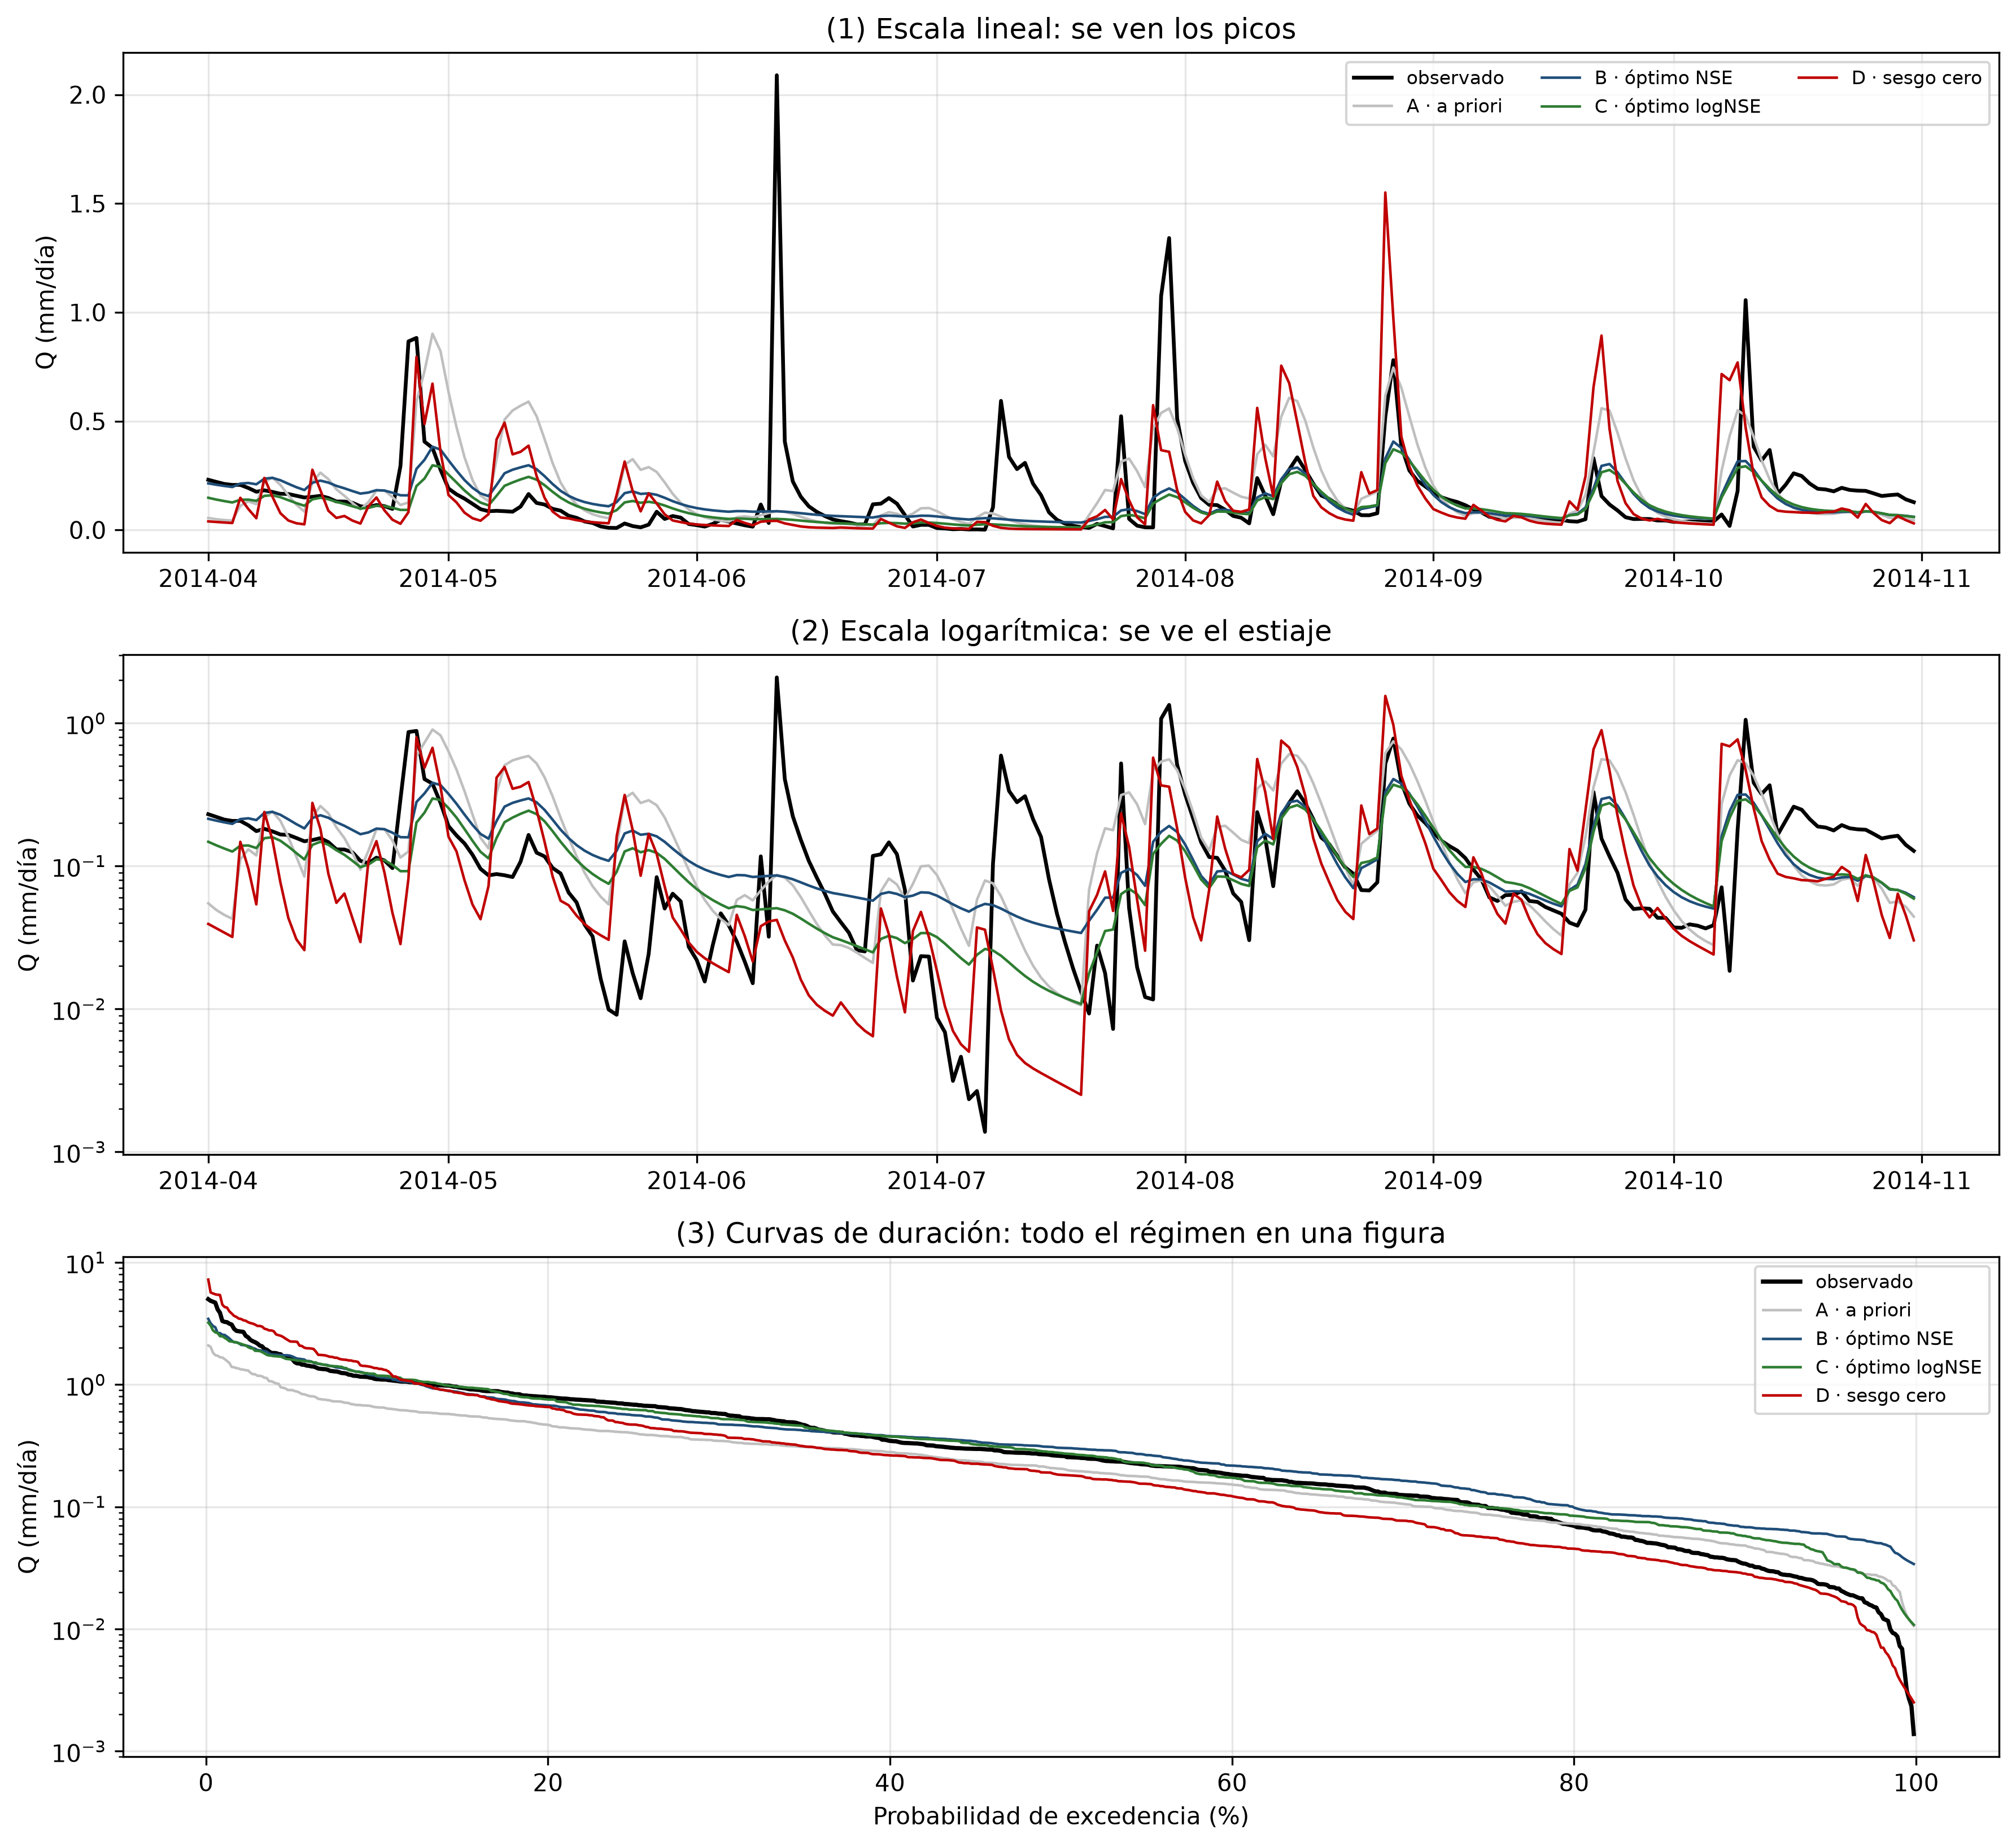

In [33]:
# Asigna un color fijo a cada combinación para mantener la misma
# identificación visual en las tres gráficas.
colores = {
    "A · a priori": "#bfbfbf",
    "B · óptimo NSE": "#1f4e79",
    "C · óptimo logNSE": "#2e7d32",
    "D · sesgo cero": "#c00000"
}

# Crea tres paneles verticales.
fig, axs = plt.subplots(3, 1, figsize=(12, 11))

# (1) HIDROGRAMA EN ESCALA LINEAL -------------------------------

# Selecciona un periodo de 2014 para examinar los eventos con mayor detalle.
d = df.loc["2014-04-01":"2014-10-31"]

# Grafica el caudal observado como referencia en color negro.
axs[0].plot(d.index, d["Q_mm"], color="k", lw=1.6, label="observado")

# Agrega las cuatro simulaciones utilizando sus colores respectivos.
for n, s in sim.items():
    axs[0].plot(d.index, s.loc[d.index], color=colores[n], lw=1.1, label=n)

# La escala lineal hace más visibles los picos y caudales altos.
axs[0].set_title("(1) Escala lineal: se ven los picos")
axs[0].set_ylabel("Q (mm/día)")
axs[0].legend(fontsize=8, ncol=3)

# (2) HIDROGRAMA EN ESCALA LOGARÍTMICA --------------------------

# Vuelve a graficar el caudal observado y las cuatro simulaciones.
axs[1].plot(d.index, d["Q_mm"], color="k", lw=1.6, label="observado")

for n, s in sim.items():
    axs[1].plot(d.index, s.loc[d.index], color=colores[n], lw=1.1, label=n)

# La escala logarítmica comprime los picos y permite distinguir el estiaje.
axs[1].set_yscale("log")
axs[1].set_title("(2) Escala logarítmica: se ve el estiaje")
axs[1].set_ylabel("Q (mm/día)")

# (3) CURVAS DE DURACIÓN ----------------------------------------

# Calcula y grafica la curva de duración del caudal observado durante CAL.
pr, qq = curva_duracion(df.loc[CAL, "Q_mm"])
axs[2].plot(pr, qq, color="k", lw=1.8, label="observado")

# Calcula la curva de duración de cada simulación sobre el mismo periodo.
for n, s in sim.items():
    pr_s, q_s = curva_duracion(s.loc[CAL])
    axs[2].plot(pr_s, q_s, color=colores[n], lw=1.1, label=n)

# Utiliza escala logarítmica para representar caudales altos y bajos.
axs[2].set_yscale("log")
axs[2].set_xlabel("Probabilidad de excedencia (%)")
axs[2].set_ylabel("Q (mm/día)")
axs[2].set_title("(3) Curvas de duración: todo el régimen en una figura")
axs[2].legend(fontsize=8)

# Ajusta los espacios y presenta la figura.
plt.tight_layout()
plt.show()

---
## ✏️ Ejercicio 4: Elegir la función objetivo

Mire la tabla de la sección 4.2 y las gráficas de la 4.3, y responda:

**4a.** La combinación **D** tiene `PBIAS` cercano a 0%, es decir, reproduce el volumen total de agua de forma casi exacta.
Sin embargo, su `NSE` es prácticamente cero. Recuerde qué significa un NSE de cero y explique por qué
un `PBIAS` casi perfecto **no** garantiza un buen modelo.

> ✏️ 
*  Un NSE cercano a cero indica que el modelo no representa el comportamiento diario mejor que si se usa el caudal medio observado. La combinación D reproduce el volumen total (PBIAS = 0.024 %), puede distribuirlo en fechas equivocadas, ya que las sobreestimaciones y subestimaciones se compensan al sumarse*

**4b.** Suponga tres propósitos de modelación distintos (caja 1 del protocolo). Para cada uno diga qué
FO usaría como criterio principal y por qué, en una línea:

| Propósito | FO principal | Por qué |
|---|---|---|
| Diseño de un vertedero de creciente | NSE | Favorece la representación de caudales altos y crecientes, anuque da mayor peso a errores grandes |
| Evaluar la oferta hídrica en época seca para una concesión de agua | Log NSE | Son más importantes los caudales bajos o de estiaje, determina cuánta agua permanece disponible en periodos secos |
| Cerrar el balance hídrico anual de la cuenca | PBIAS | Funciona para verificacr si el volument total simulado es mayor o menor que el observado. |

**4c.** ¿Cuál de las cuatro combinaciones escogería usted si el propósito fuera **operar un embalse de
abastecimiento**? Justifique en dos líneas usando al menos dos métricas de la tabla.

> ✏️ 
*  Escogería la combinación C, óptimo logNSE, porque representa mejor los caudales bajos (logNSE = 0.663), fundamentales para operar el embalse durante el estiaje. Además, conserva un buen desempeño general (KGE = 0.752) y presenta una subestimación moderada del volumen (PBIAS = −4.728 %)*

---
# Parte 5 · Estimación de parámetros por ensayo y error

> **Protocolo:** caja *Estimación de parámetros*. Esta es la calibración **manual** de la diapositiva
> correspondiente, dado que el ajuste es subjetivo, depende de la habilidad del modelador y requiere
> normalmente diez o muchas más iteraciones.

La herramienta siguiente es una sola función, que cambia parámetros, corre el modelo y calcula las métricas **en el
período de calibración**, grafica y guarda el resultado en una bitácora.

In [34]:
# Lista inicialmente vacía donde se almacenará cada intento de calibración.
# ADVERTENCIA: si se ejecuta nuevamente esta celda, la bitácora vuelve a quedar vacía.
bitacora = []      # aquí se van acumulando todos los intentos


def probar(cmax, b, alpha, Ks, Kq, nota="", graficar=True):
    """Corre HYMOD, evalúa en el período de calibración y registra el intento."""

    # Agrupa los cinco parámetros recibidos en un diccionario.
    # Esto facilita entregarlos juntos a la función hymod mediante **par.
    par = dict(cmax=cmax, b=b, alpha=alpha, Ks=Ks, Kq=Kq)

    # Comprueba si quedó algún parámetro escrito como "...".
    # Ellipsis es el nombre que Python asigna a los tres puntos.
    faltan = [k for k, v in par.items() if v is Ellipsis]

    # Si falta un parámetro, detiene la ejecución e indica cuál debe completarse.
    if faltan:
        raise ValueError("Reemplace los '...' por valores numéricos en: " + ", ".join(faltan))

    # Ejecuta HYMOD sobre toda la serie de P y ET0.
    # Se usa toda la serie porque 2012 debe servir como calentamiento.
    # **par distribuye los valores del diccionario entre los argumentos de hymod.
    #
    # El resultado se convierte en una Serie de pandas con las mismas fechas de df.
    s = pd.Series(
        hymod(df["P_mm"].values, df["ET0_mm"].values, **par),
        index=df.index
    )

    # Calcula las métricas comparando Q observado y Q simulado.
    # Aunque HYMOD se ejecutó desde 2012, la evaluación se limita a CAL (2013–2014).
    m = resumen(df.loc[CAL, "Q_mm"], s.loc[CAL])

    # Registra el número del intento, los parámetros, las métricas y la nota.
    # len(bitacora) + 1 asigna consecutivamente los intentos 1, 2, 3...
    bitacora.append({
        "intento": len(bitacora) + 1,
        **par,
        **m,
        "nota": nota
    })

    # Solo genera la gráfica cuando graficar=True.
    if graficar:

        # Selecciona del DataFrame únicamente el periodo de calibración.
        d = df.loc[CAL]

        # Crea la figura donde se compararán ambos hidrogramas.
        fig, ax = plt.subplots(figsize=(12, 3.8))

        # Caudal observado: línea negra.
        ax.plot(d.index, d["Q_mm"], color="k", lw=1.2, label="observado")

        # Caudal simulado: línea azul.
        ax.plot(d.index, s.loc[CAL], color="#1f4e79", lw=1.0, label="simulado")

        # Define las unidades del eje vertical.
        ax.set_ylabel("Q (mm/día)")

        # Presenta en el título las métricas obtenidas y la nota del intento.
        ax.set_title(
            f"Intento {len(bitacora)}  |  NSE={m['NSE']:.3f}   "
            f"logNSE={m['logNSE']:.3f}   "
            f"KGE={m['KGE']:.3f}   "
            f"PBIAS={m['PBIAS_%']:+.1f}%   {nota}"
        )

        # Agrega la leyenda, ajusta los espacios y muestra la figura.
        ax.legend()
        plt.tight_layout()
        plt.show()

    # Devuelve la serie completa de caudal simulado.
    # Esto permite utilizarla después en otras comparaciones.
    return s


def ver_bitacora():
    # Convierte la lista de intentos en una tabla.
    # El número del intento se utiliza como índice.
    # round() define el número de decimales mostrado para cada variable.
    return (
        pd.DataFrame(bitacora)
        .set_index("intento")
        .round({"cmax": 1, "b": 3, "alpha": 3, "Ks": 4, "Kq": 3, "NSE": 3,
            "logNSE": 3, "KGE": 3, "PBIAS_%": 1, "RMSE": 4
        })
    )


# Confirma que las dos funciones quedaron definidas.
print("Listo. Use probar(...) tantas veces como quiera.")

Listo. Use probar(...) tantas veces como quiera.


## 5.1 Tres intentos guiados

Los tres primeros los hacemos juntos, para ver cómo se mueve cada parámetro.

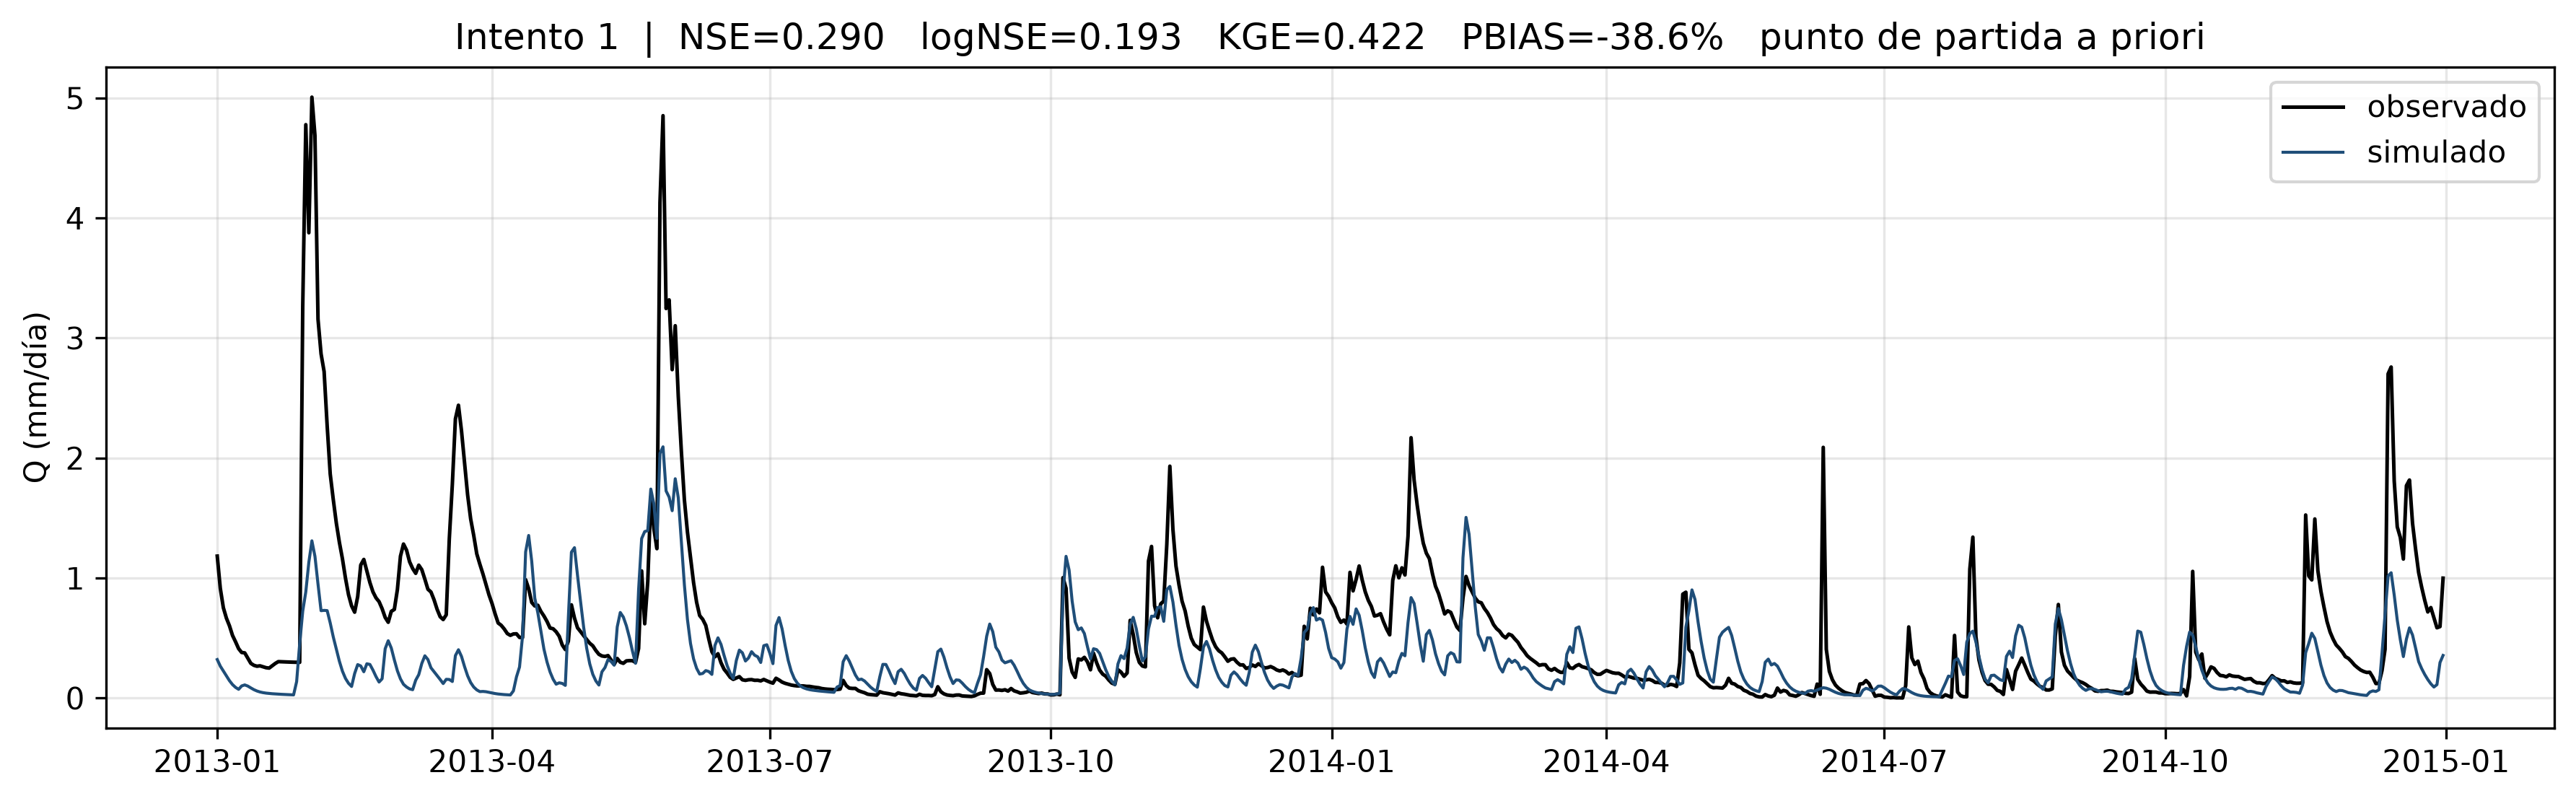

In [35]:
# Ejecuta el primer intento con los parámetros iniciales.
# El resultado se asigna a "_" porque, por ahora, solo interesa
# registrar el intento y observar la gráfica y sus métricas.
_ = probar(cmax=412.33, b=0.173, alpha=0.813, Ks=0.040, Kq=0.559,
           nota="punto de partida a priori")

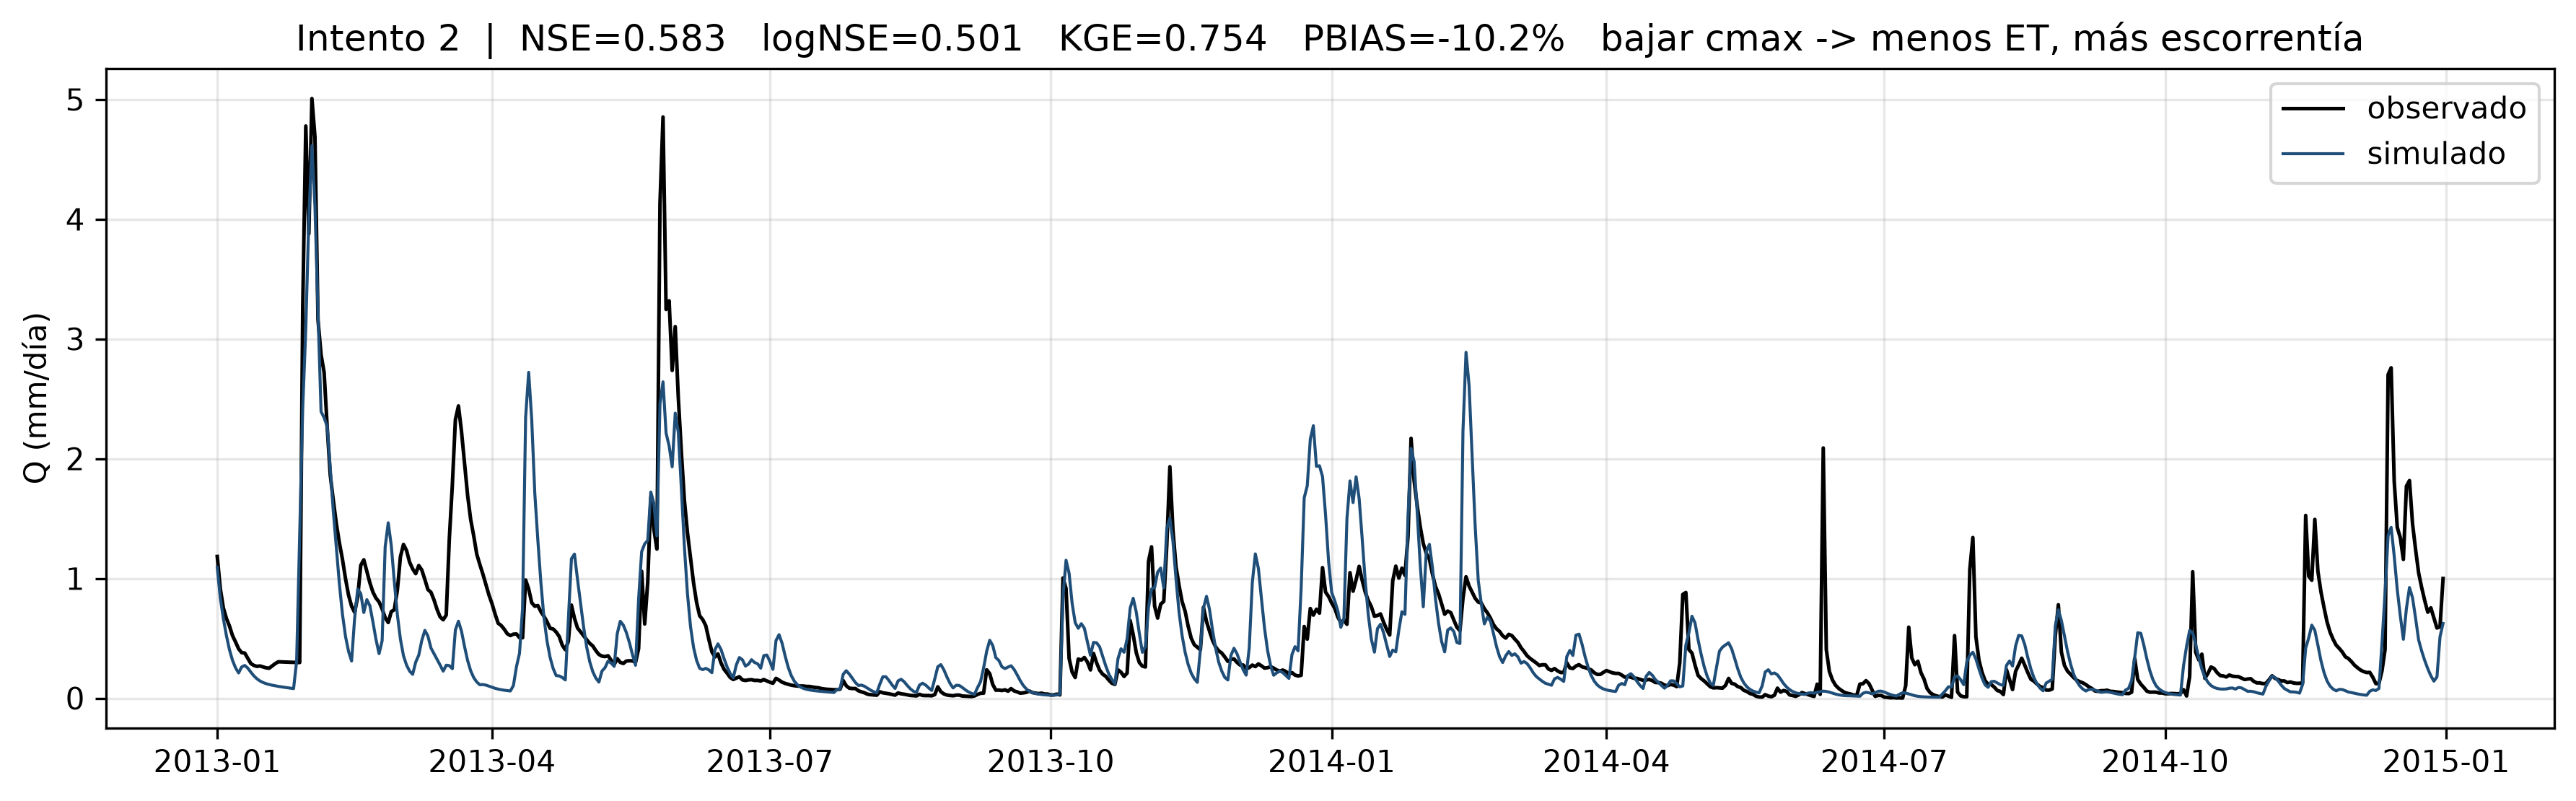

In [36]:
# El modelo subestima el volumen: hay demasiado almacenamiento de suelo, se evapora de más.
# Bajamos cmax.
_ = probar(cmax=200.0, b=0.173, alpha=0.813, Ks=0.040, Kq=0.559,
           nota="bajar cmax -> menos ET, más escorrentía")  
# NSE pasa de 0.29 a 0.58

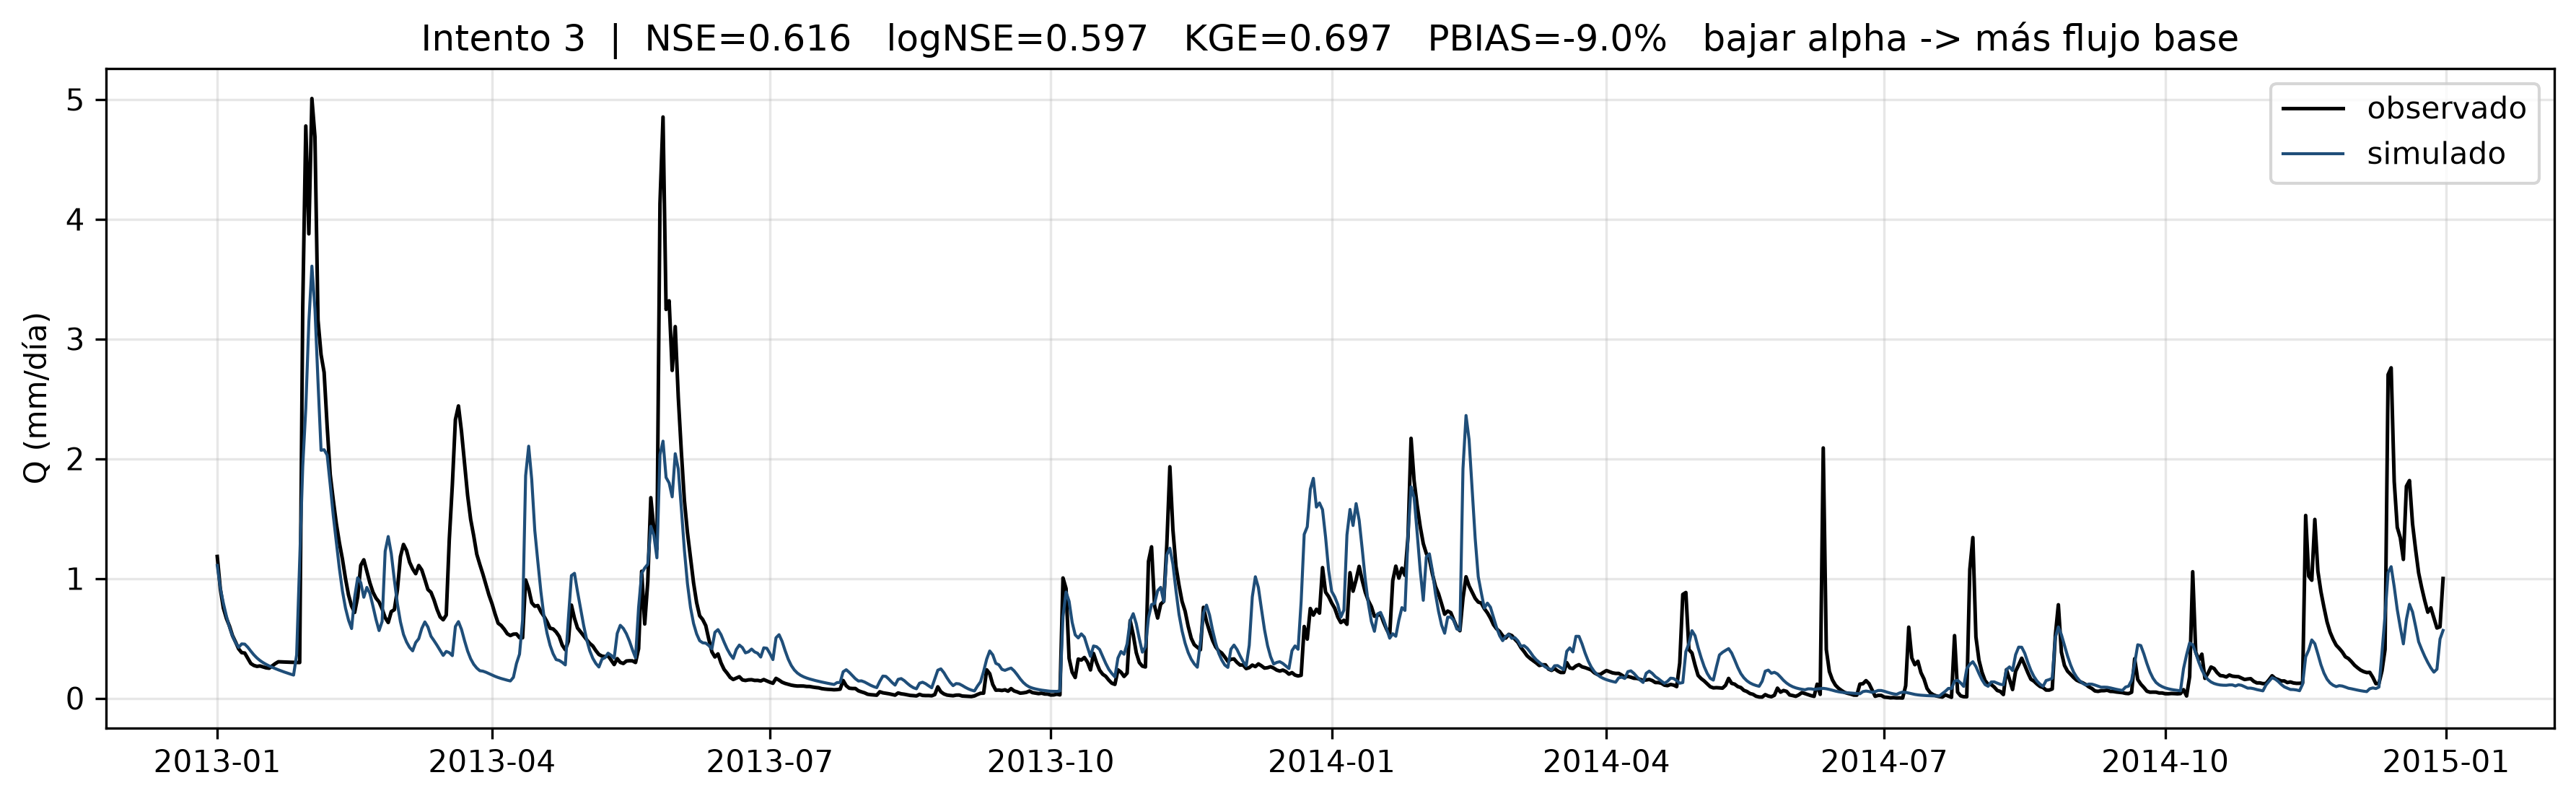

In [37]:
# Ahora el reparto: alpha muy alto manda casi todo al flujo rápido.
_ = probar(cmax=200.0, b=0.173, alpha=0.550, Ks=0.040, Kq=0.559,
           nota="bajar alpha -> más flujo base")

---
## ✏️ Ejercicio 5: Su turno

**5a.** Haga **al menos cuatro intentos más** buscando mejorar el NSE. Cambie **un parámetro a la
vez** y anote en `nota=` qué esperaba que pasara. Guía rápida de qué mueve qué:

- Volumen total mal (`PBIAS` grande) → `cmax` y, en segundo lugar, `b`.
- Picos muy bajos o muy altos → `alpha` y `Kq`.
- Recesión demasiado rápida o demasiado lenta → `Ks`.

*Meta sugerida: NSE > 0.60 en el período de calibración. El mejor valor alcanzable con este modelo y
estos datos está alrededor de 0.67. No espere una mejora monótona, ya que es normal que un intento empeore
el resultado (eso también es información).*

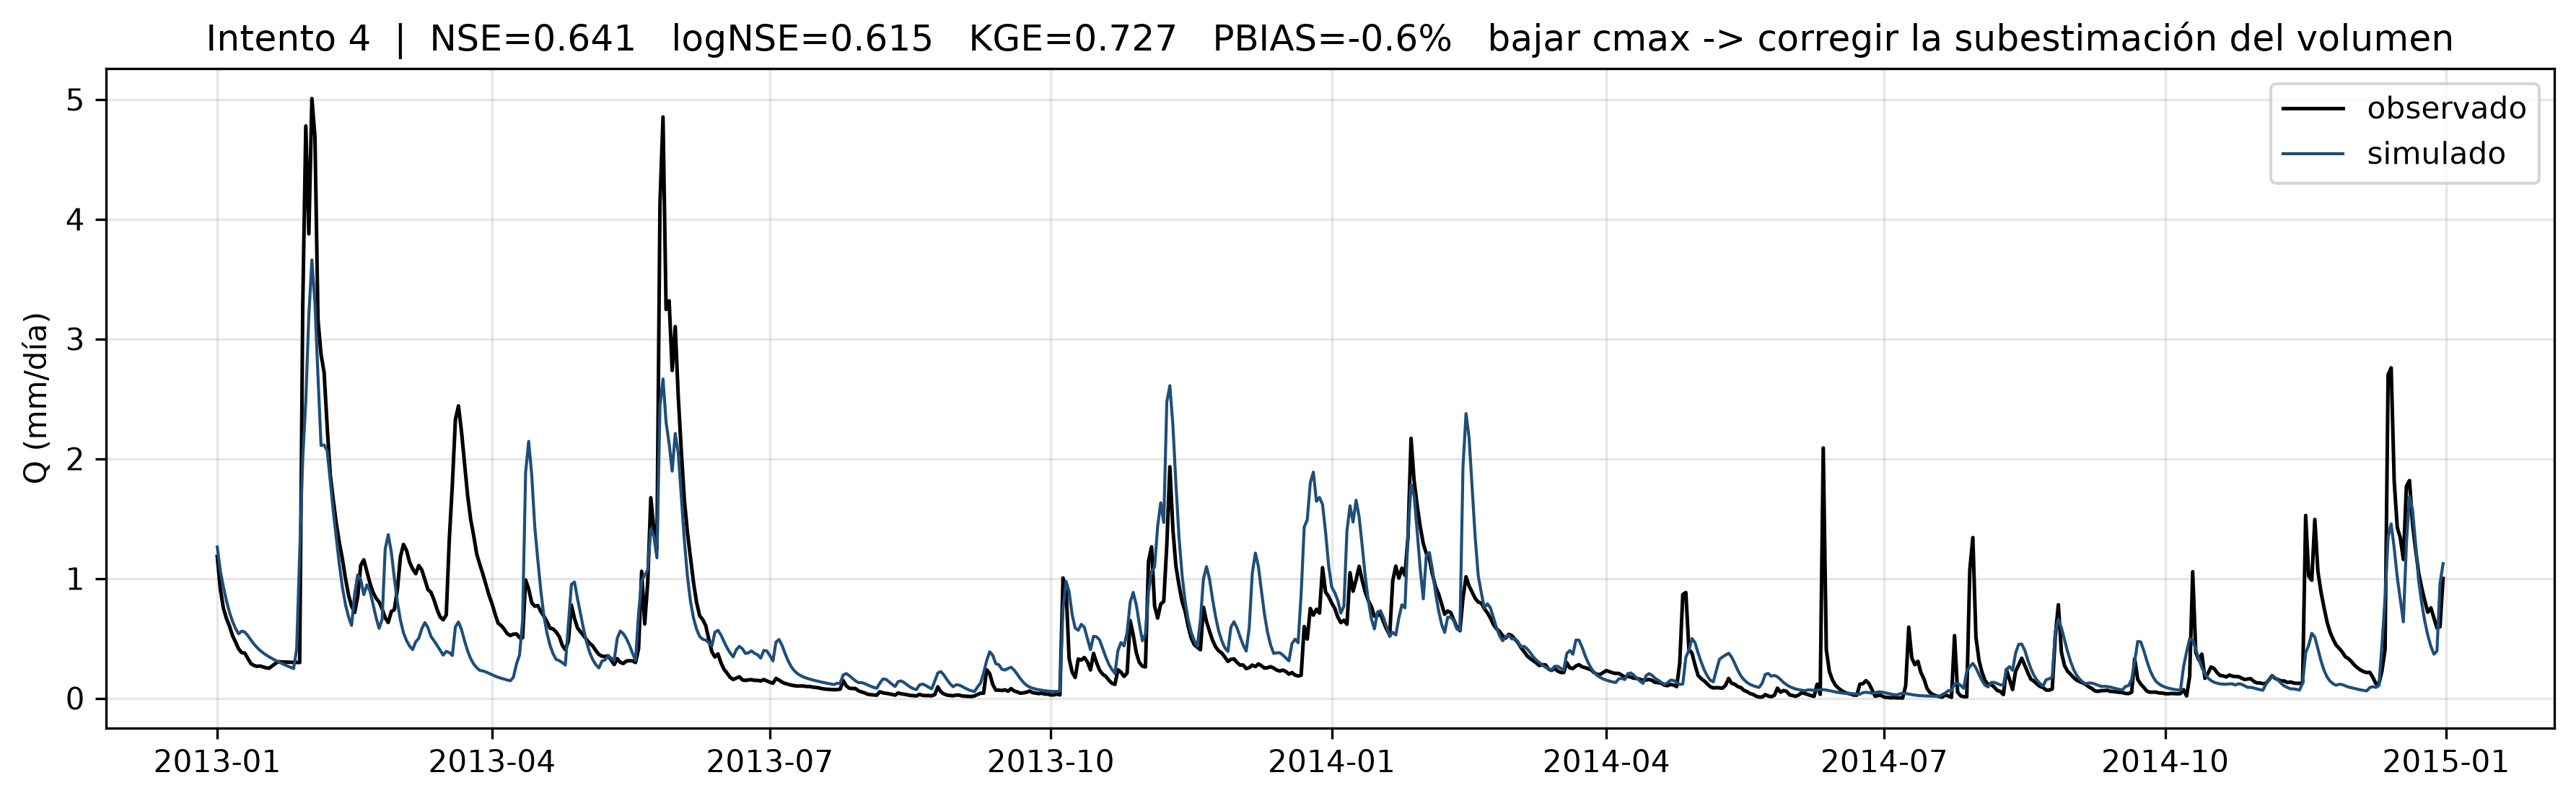

In [38]:
# ✏️ Intento 4
# Se reduce cmax DE 200 A 150, para disminuir la retención en el suelo
# Y generar más escorrentía.
_ = probar(cmax=150.0, b=0.173, alpha=0.550, Ks=0.040, Kq=0.559,
           nota="bajar cmax -> corregir la subestimación del volumen")

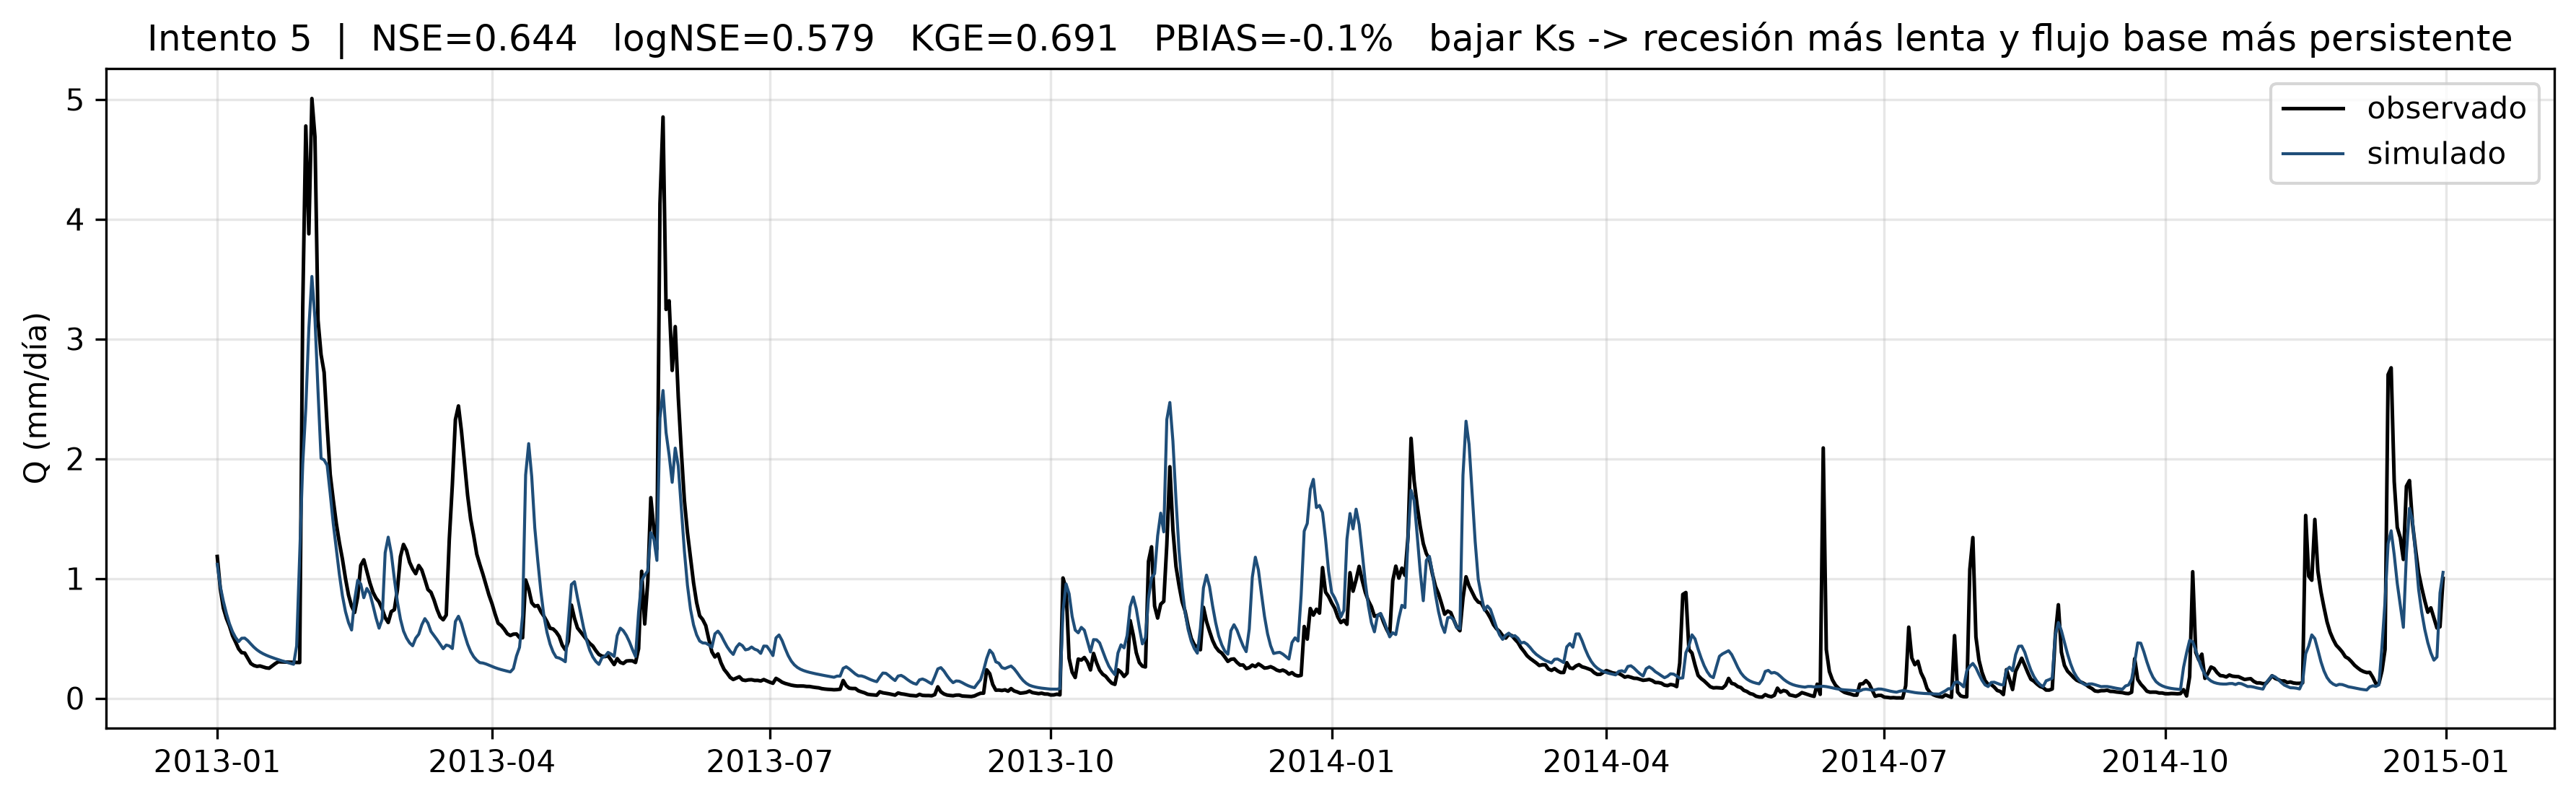

In [39]:
# ✏️ Intento 5
# Se reduce Ks para que el embalse lento libere el agua más gradualmente.
_ = probar(cmax=150.0, b=0.173, alpha=0.550, Ks=0.025, Kq=0.559,
           nota="bajar Ks -> recesión más lenta y flujo base más persistente")

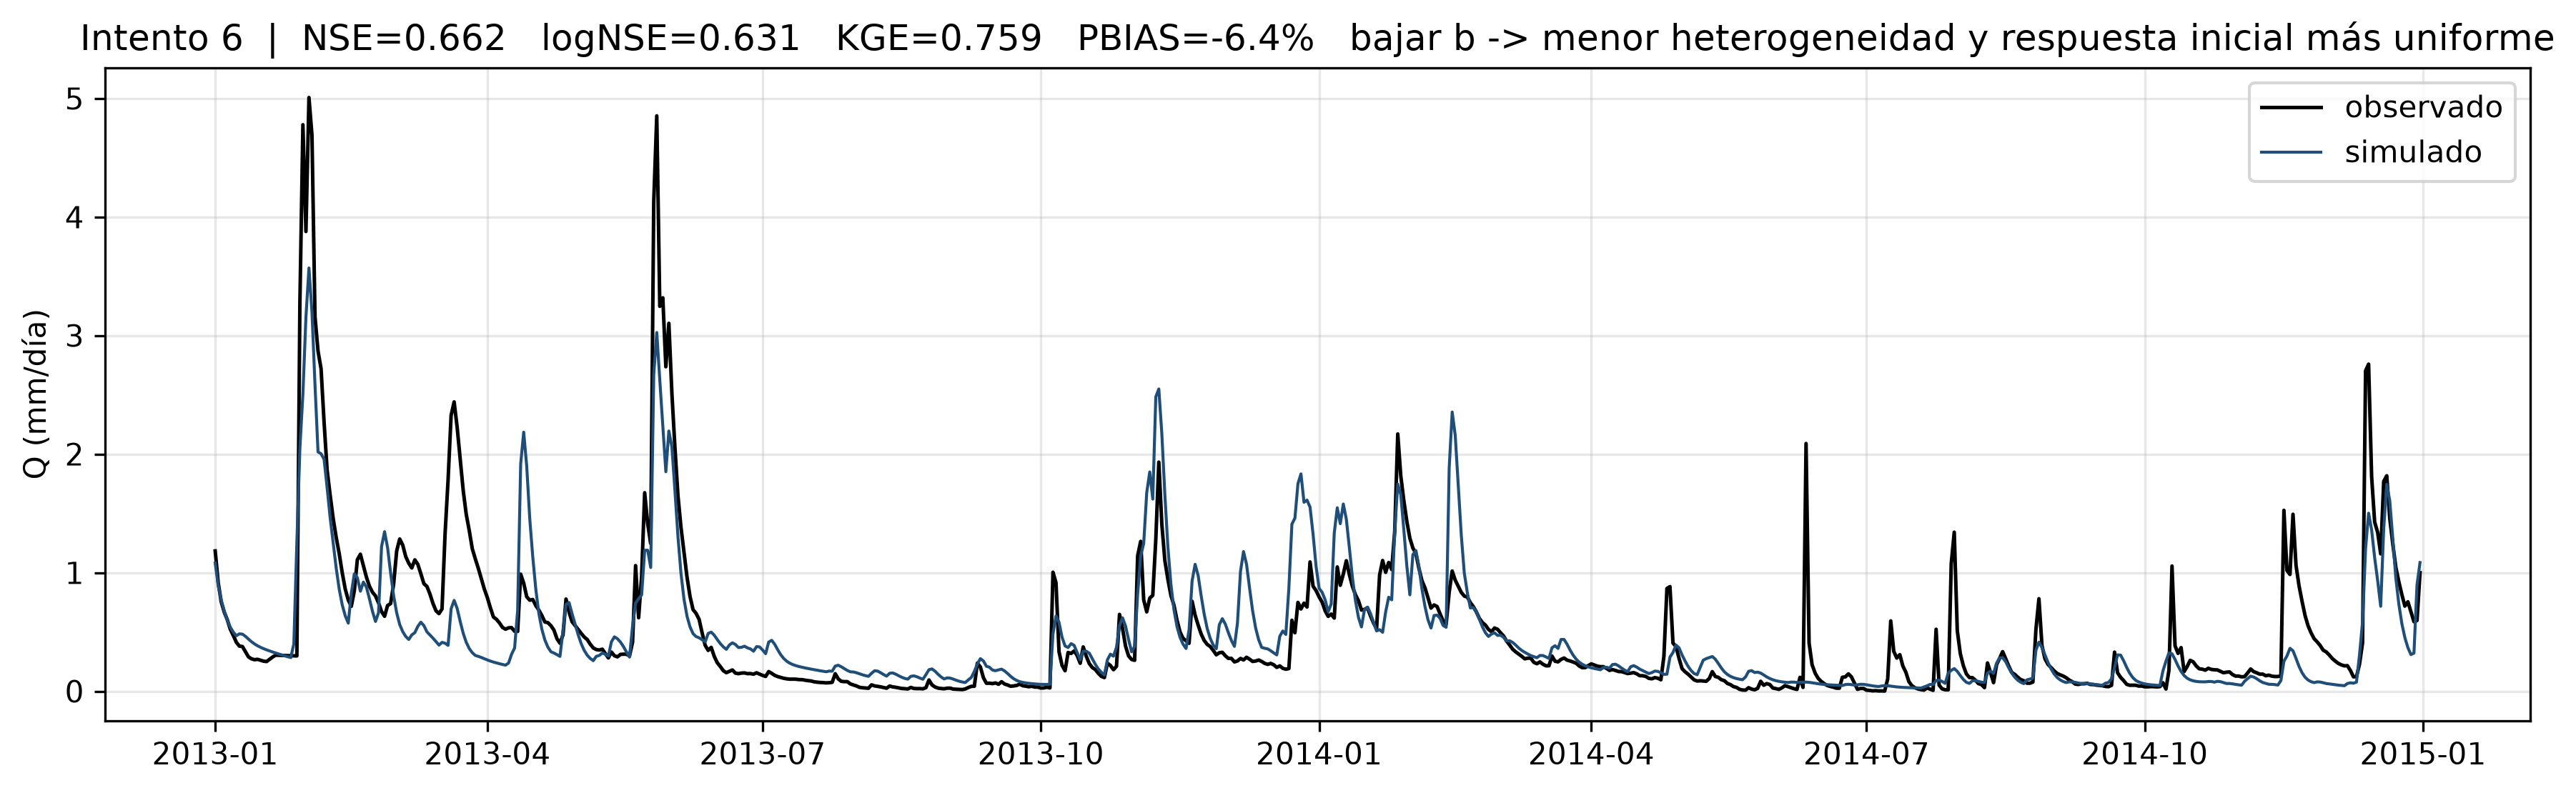

In [40]:
# ✏️ Intento 6
# Se reduce b para representar una cuenca más homogénea
# y modificar el inicio de la escorrentía.
_ = probar(cmax=150.0, b=0.100, alpha=0.550, Ks=0.025, Kq=0.559,
           nota="bajar b -> menor heterogeneidad y respuesta inicial más uniforme")

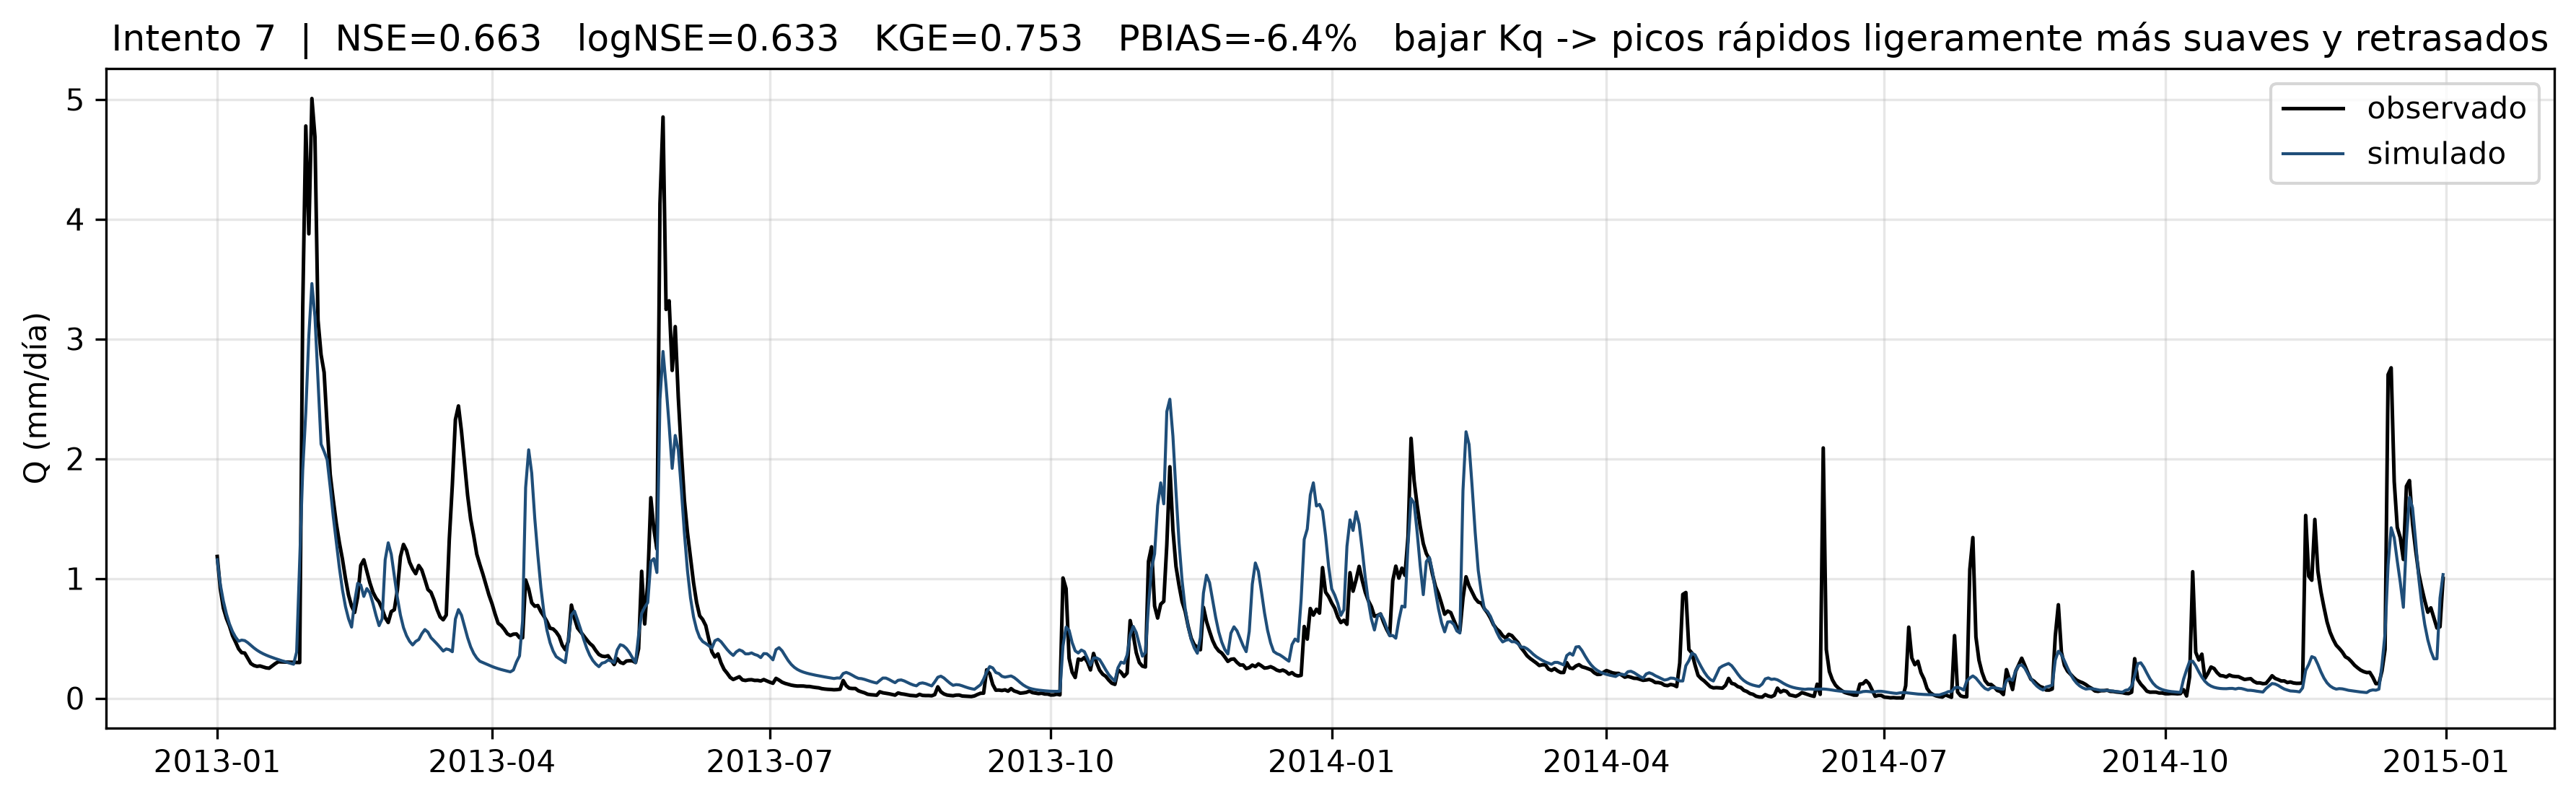

In [41]:
# ✏️ Intento 7
# Se reduce ligeramente Kq para suavizar y retrasar la respuesta del flujo rápido.
_ = probar(cmax=150.0, b=0.100, alpha=0.550, Ks=0.025, Kq=0.535,
           nota="bajar Kq -> picos rápidos ligeramente más suaves y retrasados")

In [42]:
# Confirma si se ha corrido y cuantos intentos se han registrado_GAB.
print("Intentos registrados:", len(bitacora))

Intentos registrados: 7


In [43]:
ver_bitacora()

,cmax,b,alpha,Ks,Kq,NSE,logNSE,KGE,PBIAS_%,RMSE,nota
intento,,,,,,,,,,,
1,412.3,0.173,0.813,0.040,0.559,0.290,0.193,0.422,-38.6,0.5492,punto de partida a priori
2,200.0,0.173,0.813,0.040,0.559,0.583,0.501,0.754,-10.2,0.4206,"bajar cmax -> menos ET, más escorrentía"
3,200.0,0.173,0.550,0.040,0.559,0.616,0.597,0.697,-9.0,0.4041,bajar alpha -> más flujo base
4,150.0,0.173,0.550,0.040,0.559,0.641,0.615,0.727,-0.6,0.3903,bajar cmax -> corregir la subestimación del vo...
5,150.0,0.173,0.550,0.025,0.559,0.644,0.579,0.691,-0.1,0.3890,bajar Ks -> recesión más lenta y flujo base má...
6,150.0,0.100,0.550,0.025,0.559,0.662,0.631,0.759,-6.4,0.3788,bajar b -> menor heterogeneidad y respuesta in...
7,150.0,0.100,0.550,0.025,0.535,0.663,0.633,0.753,-6.4,0.3783,bajar Kq -> picos rápidos ligeramente más suav...


**5b.** Tome su mejor combinación de parámetros y evalúelo en el período de **aceptabilidad**, que hasta
ahora no ha tocado. Este es el paso *Prueba de aceptabilidad* del protocolo.

In [44]:
# Ordena la bitácora desde el NSE más alto hasta el más bajo.
# iloc[0] selecciona la primera fila, correspondiente al mejor NSE.
mejor = ver_bitacora().sort_values("NSE", ascending=False).iloc[0]

# Extrae únicamente los cinco parámetros del mejor intento.
# float() garantiza que los valores sean numéricos para ejecutar HYMOD.
PAR_MEJOR = {k: float(mejor[k]) for k in ["cmax", "b", "alpha", "Ks", "Kq"]}

# Muestra la combinación seleccionada, redondeada a tres decimales.
print("Mejor combinación encontrada:", {k: round(v, 3) for k, v in PAR_MEJOR.items()})

# Ejecuta nuevamente HYMOD con la mejor combinación.
# Se utiliza toda la serie para conservar el calentamiento de 2012.
s_final = pd.Series(hymod(df["P_mm"].values, df["ET0_mm"].values, **PAR_MEJOR), index=df.index)

# Calcula las mismas métricas en dos periodos independientes:
# CAL: 2013–2014, utilizado para ajustar los parámetros.
# ACE: 2015–2016, reservado para comprobar la capacidad predictiva.
comparacion = pd.DataFrame({
    "Calibración":   resumen(df.loc[CAL, "Q_mm"], s_final.loc[CAL]),
    "Aceptabilidad": resumen(df.loc[ACE, "Q_mm"], s_final.loc[ACE]),
})

# Presenta la tabla con tres cifras decimales.
comparacion.round(3)

Mejor combinación encontrada: {'cmax': 150.0, 'b': 0.1, 'alpha': 0.55, 'Ks': 0.025, 'Kq': 0.535}


,Calibración,Aceptabilidad
NSE,0.663,0.579
logNSE,0.633,0.608
KGE,0.753,0.719
PBIAS_%,-6.370,18.504
RMSE,0.378,0.406


> ✏️ **Respuesta 5b.** ¿El desempeño cae al pasar al período de aceptabilidad? ¿Cuánto?
> Según el protocolo, ¿qué haría usted si el modelo **no** pasa la prueba de aceptabilidad, es decir, volver a
> qué caja del diagrama?
>
> *CUando se compara los datos que aparentemente corresponden a la mejor combinación, Se observa una variación desfavorable, El NSE disminuye de 0.663 a 0.579, una caída de 0.084, mientras el PBIAS cambia de −6.37 % a +18.50 %, evidenciando sobreestimación en aceptabilidad. Al no cumplir el criterio sugerido de NSE > 0.60,*
*Se puede revisar directamente las etapas de asignación de combinaciones en las cajas de prueba (intento #)-Realizar nuevas pruebas en probar()*
* Como ACE presenta sobreestimación de volumen (PBIAS = +18.50 %), el parámetro que primero conviene explorar es cmax. Un cmax mayor retiene más agua y reduce la escorrentía, aca es importante recordar que la función probar actua sobre el periodo de calibración 2013-2014, y posterior se comparan en ACE, sin embargo esta dinamica manual de ensayo y error, resultaria en un costo alto de tiempo y recursos*



## 5.2 Reto: equifinalidad en 1000 corridas con simulaciones de Monte Carlo

La calibración manual sirve para entender el modelo, pero no para explorar el espacio de parámetros.

La celda siguiente hace lo que más adelante reemplazaremos con herramientas como SPOTPY con algoritmos de optimización más sofisticados. Muestrear 1000 combinaciones de parámetros al azar y graficar cada parámetro contra el NSE que produjo (los llamados *dotty plots*) se llama ejecutar **SIMULACIONES DE MONTE CARLO**.

Lo que va a ver es **equifinalidad**, esto es, combinaciones de parámetros muy distintos que dan desempeños casi idénticos.

Mejor NSE de las 1000 corridas al azar: 0.619
Corridas con NSE > 0.60: 1


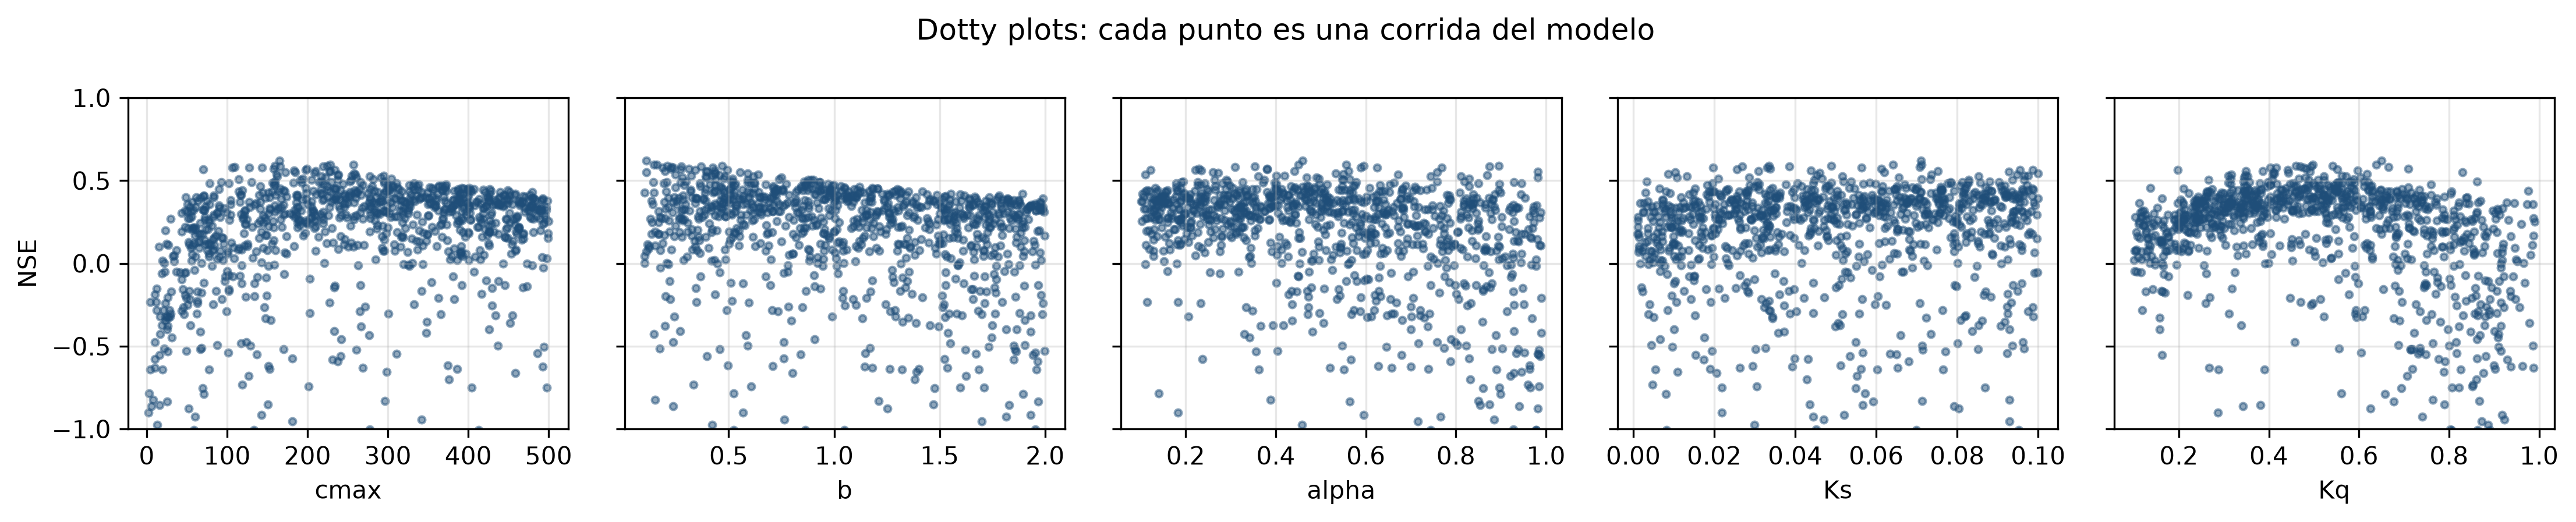

,cmax,b,alpha,Ks,Kq,NSE
322,164.852,0.110,0.459,0.071,0.651,0.619
720,256.853,0.146,0.556,0.064,0.498,0.597
728,228.104,0.159,0.450,0.071,0.639,0.597
591,224.655,0.210,0.895,0.033,0.542,0.589
276,159.678,0.467,0.595,0.049,0.460,0.587
756,166.037,0.368,0.874,0.027,0.469,0.587
40,219.139,0.274,0.353,0.039,0.494,0.586
481,109.597,0.227,0.309,0.071,0.666,0.581
993,106.765,0.235,0.589,0.033,0.416,0.580
266,143.075,0.424,0.769,0.020,0.476,0.578


In [45]:
# Crea un generador aleatorio.
# La semilla 42 permite reproducir exactamente las mismas 1000 combinaciones.
rng = np.random.default_rng(42)

# Número de corridas de HYMOD.
N = 1000

# Define los límites de búsqueda para los cinco parámetros.
LIM = {"cmax": (1, 500), "b": (0.1, 2.0), "alpha": (0.1, 0.99),
       "Ks": (0.001, 0.10), "Kq": (0.1, 0.99)}

# Genera N valores aleatorios con distribución uniforme dentro de cada rango.
# Todas las posiciones del rango tienen la misma probabilidad de ser seleccionadas.
muestras = {k: rng.uniform(lo, hi, N) for k, (lo, hi) in LIM.items()}

# Reserva un arreglo vacío para almacenar el NSE de cada corrida.
obj = np.empty(N)

# Recorre las 1000 combinaciones.
for i in range(N):

    # Construye el diccionario con los cinco parámetros de la corrida i.
    par = {k: muestras[k][i] for k in LIM}

    # Ejecuta HYMOD con esa combinación sobre toda la serie.
    s = hymod(df["P_mm"].values, df["ET0_mm"].values, **par)

    # Calcula el NSE únicamente en CAL: 2013–2014.
    obj[i] = nse(df.loc[CAL, "Q_mm"], pd.Series(s, index=df.index).loc[CAL])

# Crea una tabla con los parámetros y agrega el NSE de cada corrida.
mc = pd.DataFrame(muestras); mc["NSE"] = obj

# Informa el mejor NSE encontrado y cuántas corridas superaron 0.60.
print(f"Mejor NSE de las {N} corridas al azar: {mc['NSE'].max():.3f}")
print(f"Corridas con NSE > 0.60: {(mc['NSE'] > 0.60).sum()}")

# Crea cinco gráficas: una para cada parámetro.
fig, axs = plt.subplots(1, 5, figsize=(15, 3), sharey=True)

# Cada punto representa una corrida:
# eje X = valor del parámetro; eje Y = NSE obtenido.
for ax, k in zip(axs, LIM):
    ax.scatter(mc[k], mc["NSE"], s=8, alpha=0.5, color="#1f4e79")
    ax.set_xlabel(k); ax.set_ylim(-1, 1)

axs[0].set_ylabel("NSE")
fig.suptitle("Dotty plots: cada punto es una corrida del modelo")
plt.tight_layout(); plt.show()

# Ordena las corridas por NSE y presenta las diez mejores.
mc.sort_values("NSE", ascending=False).head(10).round(3)

> ✏️ **Respuesta 5c (reto).** Mire las 10 mejores combinaciones de la tabla. ¿Los valores de `cmax` de
> esas 10 simulaciones son parecidos entre sí? ¿Y los de `Ks`? Un parámetro cuyos buenos valores están muy
> dispersos se llama **poco identificable**. ¿Cuál de los cinco parámetros le parece el más
> identificable y cuál el menos? ¿Qué implica eso para interpretarlos físicamente?
>
> * Los valores de cmax de la lista de 10  mejores combinaciones, no son iguales, pero se concentran entre 106.8 y 256.8 mm, en la parte baja del rango explorado. Ks está más disperso, entre 0.020 y 0.071. En esta muestra, b es el parámetro más identificable porque sus mejores valores se concentran cerca del límite inferior, mientras que alpha es el menos identificable porque presenta buenos resultados entre 0.309 y 0.895; Ks también muestra baja identificabilidad. Esto evidencia equifinalidad y limita la interpretación física de los parámetros calibrados, pues un buen NSE no demuestra que sus valores representen propiedades únicas y medibles de la cuenca.* 
* Los parámetros son bastante diferentes, pero los NSE son casi iguales. Esto ocurre porque los efectos pueden compensarse:

  un alpha alto envía más agua al flujo rápido;
  un Kq menor puede retrasar esa respuesta;
  un cmax mayor retiene más agua;
  un cambio en b puede hacer que algunas zonas generen escorrentía antes.

  Como resultado, las combinaciones pueden producir un caudal total semejante, aunque representen de manera diferente lo que sucede dentro de la cuenca.

---
# Parte 6: Tres cuencas colombianas

> **Protocolo:** volvemos a la primera caja. Con datos reales, *establecer el propósito* y *evaluar los
> datos* dejan de ser trámites.

Hasta aquí trabajamos con una cuenca experimental de 1.8 km², con datos completos y sin vacíos. Ahora vamos a mirar tres cuencas colombianas reales del conjunto **CAMELS-COL**
(Jiménez et al., 2025), con precipitación satelital CHIRPS, temperaturas de MSWX y caudales del IDEAM.

| | Cuenca **llanera** | Cuenca **andina** | Cuenca **Caribe** |
|---|---|---|---|
| Estación IDEAM | 35127020 | 21167080 | 28037030 |
| Departamento | Meta | Tolima | Cesar |
| Área | 1 894.8 km² | 446.8 km² | 3 434.1 km² |
| Elevación media de la cuenca | 211 m | 1 560 m | 1 164 m |
| Elevación de la estación | 149 m | 415 m | 108 m |
| Precipitación | 2 700 mm/año | 1 835 mm/año | 1 520 mm/año |
| Régimen de lluvias | **unimodal** (abril a octubre) | **bimodal** (abril y noviembre) | **bimodal** con temporada seca larga |
| Período del taller | 2001–2008 | 2001–2008 | 2001–2008 |

Las tres series traen `P_mm` (CHIRPS), la columna `ETP_mm` que publica el conjunto original,
temperaturas mínima y máxima, y `Q` observado, ya convertido a lámina de agua (`Q_mm`) con el área de cada
cuenca. Siguiendo la nomenclatura fijada en la Parte 3, en lo que sigue reservamos $ET_0$ para la
evapotranspiración de referencia que calculamos nosotros y dejamos `ETP_mm` como el nombre del dato
publicado, sin suponer que ambos coincidan.

## 6.1 Cálculo propio de la evapotranspiración de referencia

Los archivos traen una columna `ETP_mm` tomada del conjunto original, pero en este taller vamos a
calcular nuestra propia evapotranspiración de referencia. Las temperaturas mínima y máxima diarias
vienen en el mismo archivo, y con ellas basta para aplicar la fórmula de Hargreaves-Samani.

$$ET_0 = 0.0023\;R_a\;(T_{media} + 17.8)\;\sqrt{T_{max}-T_{min}}$$

$R_a$ es la **radiación extraterrestre**, la energía solar que llega al tope de la atmósfera. Depende
solo de la latitud y del día del año (no del clima), así que se calcula exactamente, sin necesidad de
ningún dato medido. La fórmula la exige expresada como **lámina de agua equivalente (mm/día)** y no como
energía. La conversión usa el calor latente de vaporización del agua, cercano a 2.45 MJ kg⁻¹ a 20 °C,
de modo que evaporar 1 mm consume 2.45 MJ por metro cuadrado.

Calcular uno mismo el forzamiento tiene dos ventajas. La primera es que usted sabe exactamente qué está
usando y bajo qué supuestos, en lugar de heredar la definición de otro. La segunda es que le da una
referencia propia contra la cual comparar cualquier producto que le entreguen, que es parte de la caja
*evaluar datos y necesidades de datos* del protocolo.

In [46]:
def radiacion_extraterrestre(lat_grados, dia_del_anio):
    """Radiación extraterrestre Ra, en mm/día de agua equivalente (FAO-56, ec. 21 a 25).

    Es la energía solar que llega al tope de la atmósfera. Depende solo de la
    latitud y del día del año, así que se calcula exactamente, sin datos medidos.
    """

    # Convierte la latitud de grados a radianes porque las funciones
    # trigonométricas de NumPy operan con radianes.
    phi = np.radians(lat_grados)

    # Calcula la distancia relativa Tierra-Sol.
    # Su variación se debe a que la órbita terrestre no es perfectamente circular.
    dr  = 1 + 0.033 * np.cos(2 * np.pi * dia_del_anio / 365)

    # Calcula la declinación solar: posición angular aparente del Sol
    # respecto al plano ecuatorial terrestre.
    dec = 0.409 * np.sin(2 * np.pi * dia_del_anio / 365 - 1.39)

    # Calcula el ángulo horario correspondiente al ocaso.
    # clip() evita valores numéricos fuera del intervalo válido de arccos.
    ws  = np.arccos(np.clip(-np.tan(phi) * np.tan(dec), -1, 1))

    # Calcula Ra como energía en MJ por metro cuadrado y por día.
    # 0.0820 es la constante solar expresada en MJ m-2 min-1.
    Ra_MJ = (24 * 60 / np.pi) * 0.0820 * dr * (
        ws * np.sin(phi) * np.sin(dec) + np.cos(phi) * np.cos(dec) * np.sin(ws))

    # Convierte energía en lámina de agua equivalente.
    # Evaporar 1 mm de agua requiere aproximadamente 2.45 MJ/m².
    return Ra_MJ / 2.45      # 1 mm de agua evaporada consume 2.45 MJ m-2


def et0_hargreaves(T_min, T_max, lat_grados, fechas):
    """Evapotranspiración de referencia diaria, Hargreaves-Samani (1985), en mm/día."""

    # Calcula Ra para la latitud de la cuenca y cada día del año.
    Ra = radiacion_extraterrestre(lat_grados, fechas.dayofyear.values)

    # Calcula la temperatura media diaria.
    T_media = (T_max + T_min) / 2

    # Aplica Hargreaves-Samani.
    # T_max - T_min es el rango térmico diario.
    # clip() evita calcular una raíz negativa si aparece Tmax < Tmin.
    return 0.0023 * Ra * (T_media + 17.8) * np.sqrt(np.clip(T_max - T_min, 0, None))


# Prueba de verificación: en el equinoccio y sobre el ecuador, Ra vale ~37.6 MJ m-2 d-1 (FAO-56)
ra = radiacion_extraterrestre(0, 80)
print(f"Ra en el ecuador, 21 de marzo: {ra:.2f} mm/día = {ra * 2.45:.1f} MJ m-2 d-1")

Ra en el ecuador, 21 de marzo: 15.44 mm/día = 37.8 MJ m-2 d-1


# Nota de analisis con apoyo de IA
* Ver formula ETo 6.1
* El primer valor no significa que se evaporen realmente 15.44 mm/día.     Representa la radiación extraterrestre convertida en una lámina energética equivalente. Hargreaves–Samani reduce posteriormente ese valor según la temperatura media y la amplitud térmica para calcular \(ET_0\).

* La diferencia entre el comentario aproximado de 37.6 y la salida de 37.8 MJ/m²/día se debe al redondeo y a las aproximaciones de las ecuaciones astronómicas. No indica un error de ejecución.

In [47]:
# Define el archivo, el área y la latitud de cada cuenca.
# La latitud se utiliza para calcular la radiación extraterrestre.
CUENCAS = {
    "Llanera (Meta, 35127020)":  {"archivo": "cuenca_llanos_35127020.csv", "area": 1894.80, "lat": 4.31},
    "Andina (Tolima, 21167080)": {"archivo": "cuenca_andina_21167080.csv", "area":  446.82, "lat": 3.70},
    "Caribe (Cesar, 28037030)":  {"archivo": "cuenca_caribe_28037030.csv", "area": 3434.05, "lat": 10.32},
}

# Diccionario donde se almacenará el DataFrame procesado de cada cuenca.
col = {}

# Recorre las tres cuencas.
for nombre, info in CUENCAS.items():

    # Lee el archivo CSV, convierte fecha en datetime y la establece como índice.
    # asfreq("D") crea una secuencia diaria continua; si falta una fecha,
    # incorpora ese día con valores NaN.
    d = pd.read_csv(DATOS / info["archivo"], parse_dates=["fecha"]).set_index("fecha").asfreq("D")

    # Cuenta los datos faltantes de precipitación antes de interpolar.
    huecos = int(d["P_mm"].isna().sum())

    # El caudal observado puede tener huecos (esos días no entran en las métricas), pero
    # el forzamiento no: si P o las temperaturas traen un NaN, el modelo lo arrastra y a
    # partir de ahí toda la simulación se vuelve NaN. Hay que rellenarlo y dejar constancia.
    for c in ["P_mm", "T_min_C", "T_max_C"]:      # ETP_mm no se usa, no se interpola

        # Completa linealmente los vacíos de precipitación y temperatura.
        # limit_direction="both" también permite completar vacíos en los extremos.
        d[c] = d[c].interpolate(limit_direction="both")

    # La ET0 que vamos a usar la calculamos nosotros, con la fórmula que declaran los
    # autores de CAMELS-COL y las temperaturas de su propio archivo.
    d["ET0_mm"] = et0_hargreaves(d["T_min_C"], d["T_max_C"], info["lat"], d.index)

    # Guarda la tabla procesada dentro del diccionario col.
    col[nombre] = d

    # Presenta el número de días, los días sin caudal y los vacíos de P interpolados.
    print(f"{nombre:28s} {len(d)} días | sin caudal: {int(d['Q_m3s'].isna().sum()):4d} | "
          f"forzamiento interpolado: {huecos:3d} días")

Llanera (Meta, 35127020)     2922 días | sin caudal:    5 | forzamiento interpolado:   5 días
Andina (Tolima, 21167080)    2922 días | sin caudal:    2 | forzamiento interpolado:   2 días
Caribe (Cesar, 28037030)     2922 días | sin caudal:   47 | forzamiento interpolado:  47 días


## 6.2 Tres regímenes en una figura

El ciclo anual medio (climatología mensual) es un resumen inicial muy informativo de una cuenca. Las
series graficadas allí van en las mismas unidades (mm/mes), para que las alturas de las barras y de la línea se
puedan comparar directamente. La diferencia entre la lluvia y el caudal es, como una primera aproximación, lo que se
evapora.

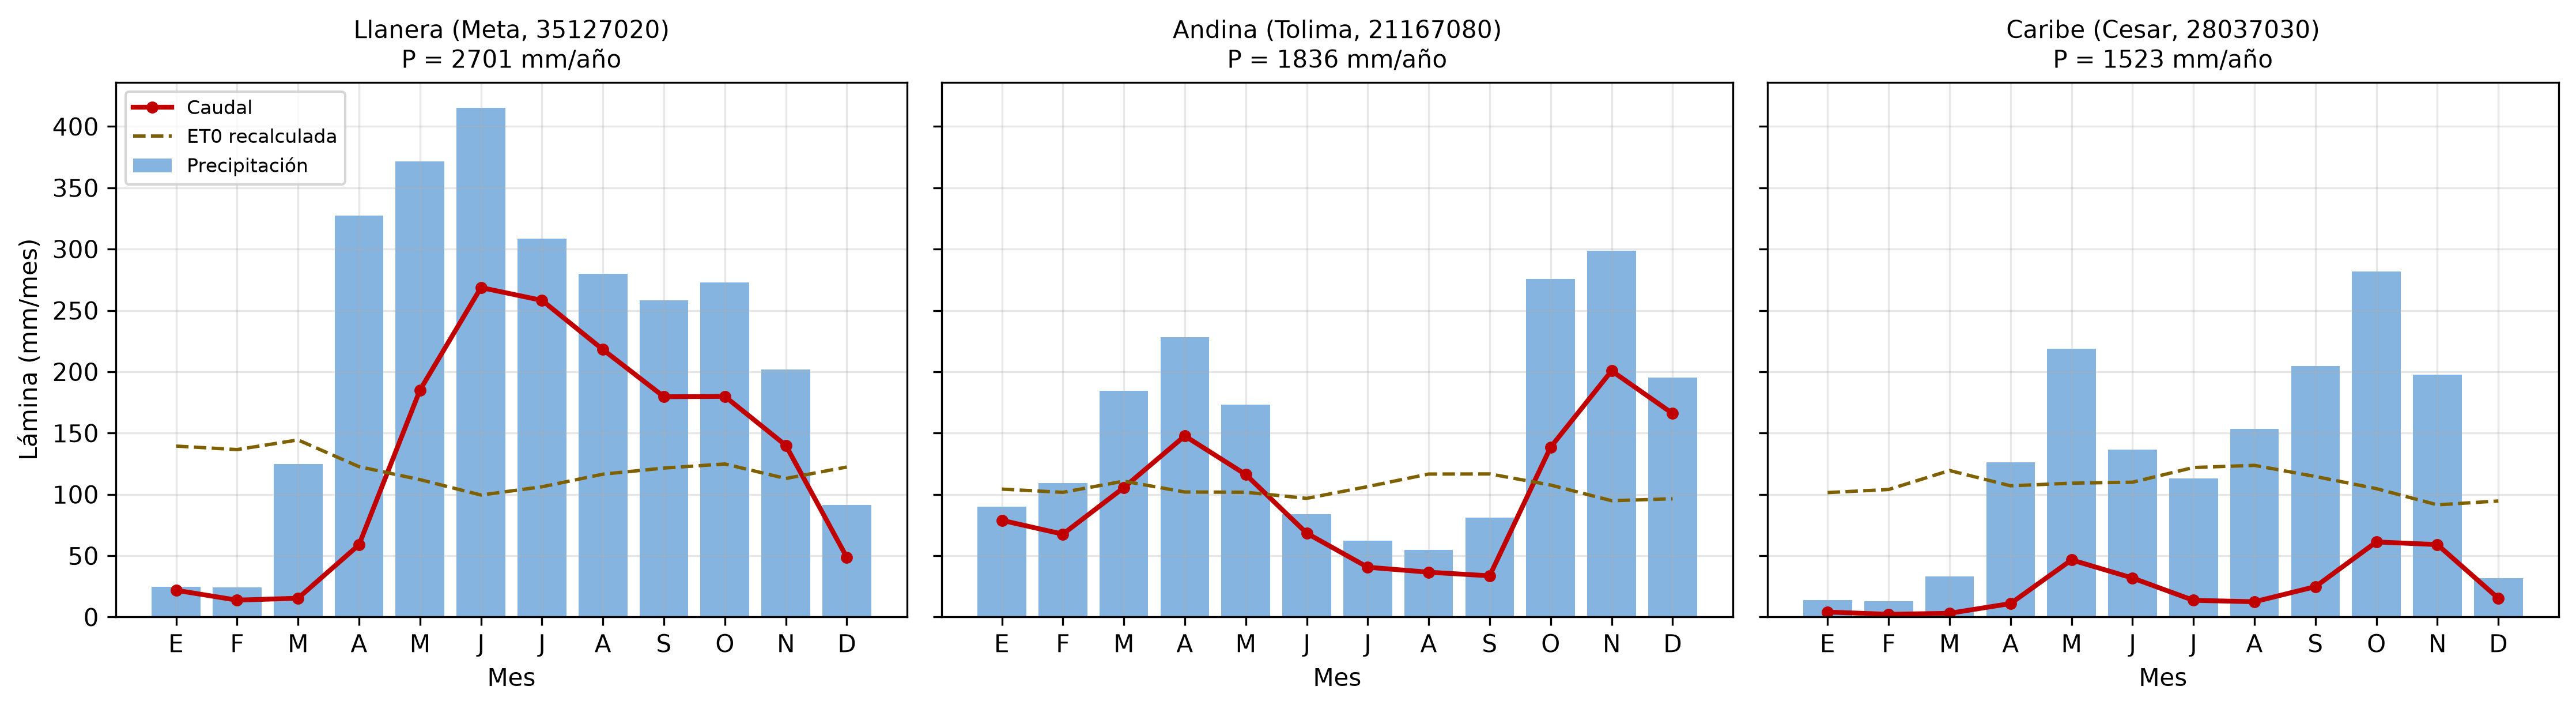

In [48]:
# Número medio de días de cada mes.
# Febrero se representa con 28.25 para considerar los años bisiestos.
DIAS_MES = np.array([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

# Iniciales de los doce meses para las etiquetas del eje horizontal.
MESES = list("EFMAMJJASOND")

# Crea una figura con tres paneles, uno por cuenca.
# sharey=True obliga a utilizar la misma escala vertical en los tres paneles.
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)

# Recorre simultáneamente cada eje y cada cuenca almacenada en col.
for ax, (nombre, d) in zip(axs, col.items()):

    # Calcula el promedio diario de precipitación para cada mes.
    # Luego lo multiplica por el número medio de días para obtener mm/mes.
    P_mes = d["P_mm"].groupby(d.index.month).mean().values * DIAS_MES

    # Convierte el caudal medio diario de cada mes en lámina mensual.
    Q_mes = d["Q_mm"].groupby(d.index.month).mean().values * DIAS_MES

    # Convierte la ET0 media diaria de cada mes en lámina mensual.
    E_mes = d["ET0_mm"].groupby(d.index.month).mean().values * DIAS_MES

    # Genera las posiciones de los doce meses en el eje X.
    meses = np.arange(1, 13)

    # Representa la precipitación mediante barras azules.
    ax.bar(meses, P_mes, color="#5b9bd5", alpha=0.75, label="Precipitación")

    # Representa el caudal mediante una línea roja.
    ax.plot(meses, Q_mes, color="#c00000", lw=2, marker="o", ms=4, label="Caudal")

    # Representa la ET0 mediante una línea café discontinua.
    ax.plot(meses, E_mes, color="#7f6000", lw=1.4, ls="--", label="ET0 recalculada")

    # Configura las posiciones y etiquetas mensuales.
    ax.set_xticks(meses); ax.set_xticklabels(MESES)

    # Presenta el nombre de la cuenca y la precipitación media anual.
    ax.set_title(f"{nombre}\n" + f"P = {P_mes.sum():.0f} mm/año", fontsize=10)

    # Etiqueta el eje horizontal.
    ax.set_xlabel("Mes")

# Define el nombre y las unidades del eje vertical compartido.
axs[0].set_ylabel("Lámina (mm/mes)")

# Agrega la leyenda al primer panel.
axs[0].legend(fontsize=8, loc="upper left")

# Ajusta los espacios y muestra la figura.
plt.tight_layout(); plt.show()

**Lea las tres figuras antes de seguir.**

- **Llanera:** una sola temporada de lluvias, de abril a octubre, y una estación seca corta y profunda
  en diciembre–febrero. Es el régimen unimodal clásico de la Orinoquía.
- **Andina:** dos temporadas de lluvia, abril y noviembre, separadas por dos períodos secos. Ninguno de
  los dos mínimos es severo, la cuenca nunca se seca del todo.
- **Caribe:** también dos picos, mayo y octubre, pero precedidos por cuatro meses (diciembre a marzo)
  con menos de 35 mm/mes. Es bimodal, pero con una estación seca larga, que es el régimen típico del
  valle del Cesar.

Observe ahora la línea de la ET0. Es **casi plana** en las tres cuencas, porque la demanda atmosférica
en el trópico varía poco a lo largo del año. La precipitación, en cambio, varía entre el mes más seco y
el más húmedo en un factor de 18 en la cuenca llanera, de 22 en la del Caribe y de 5 en la andina. Esa
asimetría marca una diferencia de fondo con las latitudes medias, donde el ciclo de la
evapotranspiración pesa tanto como el de la precipitación. **Aquí el régimen hidrológico queda definido
casi enteramente por la lluvia.**

La consecuencia se ve en el panel del Caribe, donde de diciembre a marzo la precipitación cae por debajo de la
demanda atmosférica, con déficits de 70 a 100 mm/mes durante cuatro meses seguidos. En ese período no
queda agua disponible para escorrentía, y eso ya anticipa un coeficiente de escorrentía bajo.

## 6.3 La prueba de consistencia que hicimos en la Parte 2, ahora con datos reales

En la Parte 2 dijimos que $P - Q$ es un residuo y no una medición, y que el supuesto
$\Delta S \approx 0$ no se sostiene para un año aislado. Con ocho años de tres cuencas ya podemos
ponerle número a esa afirmación en vez de repetirla. Por simplicidad, en este taller usamos un período de 8 años.
No obstante, cuando hablamos de "largo plazo" es conveniente trabajar con series de 20 o 30 años.

Si el almacenamiento no cambiara nunca, el residuo anual $P - Q$ sería igual todos los años salvo por la
variación real de la evapotranspiración, que en el trópico es pequeña porque la demanda atmosférica casi
no cambia de un año a otro. Todo lo que sobre de esa diferencia es, en buena parte, agua que un año se
guardó y que en otro se liberó.

In [49]:
# Diccionario donde se almacenará el resumen de cada cuenca.
resumen_anual = {}

# Recorre las tres cuencas procesadas.
for nombre, d in col.items():

    # Agrupa la información por años calendario:
    # P = precipitación anual acumulada.
    # Q = caudal anual acumulado como lámina.
    # n = número de días con caudal observado.
    a = d.resample("YS").agg(P=("P_mm", "sum"), Q=("Q_mm", "sum"), n=("Q_mm", "count"))

    # Conserva únicamente años con más de 350 días de caudal observado.
    # Así se excluyen los años demasiado incompletos.
    a = a[a["n"] > 350]                       # solo años prácticamente completos

    # Calcula el residuo anual del balance.
    res = a["P"] - a["Q"]

    # Guarda los indicadores estadísticos de cada cuenca.
    resumen_anual[nombre] = {

        # Número de años prácticamente completos.
        "años": len(a),

        # Promedio de P-Q durante los años seleccionados.
        "residuo medio (mm/año)": res.mean(),

        # Desviación estándar del residuo entre los diferentes años.
        "desv. entre años (mm/año)": res.std(),

        # Desviación estándar expresada como porcentaje del promedio.
        "dispersión (%)": 100 * res.std() / res.mean(),

        # Error estándar del promedio.
        "error del promedio (mm/año)": res.std() / np.sqrt(len(a)),

        # Error estándar expresado como porcentaje del promedio.
        "error del promedio (%)": 100 * res.std() / np.sqrt(len(a)) / res.mean(),
    }

# Convierte el diccionario en una tabla:
# cada fila es una cuenca y cada columna es un indicador.
pd.DataFrame(resumen_anual).T.round(1)

,años,residuo medio (mm/año),desv. entre años (mm/año),dispersión (%),error del promedio (mm/año),error del promedio (%)
"Llanera (Meta, 35127020)",8.0,1118.4,103.7,9.3,36.7,3.3
"Andina (Tolima, 21167080)",8.0,637.2,63.1,9.9,22.3,3.5
"Caribe (Cesar, 28037030)",7.0,1267.2,67.5,5.3,25.5,2.0


**Cómo se lee.** El residuo anual se mueve entre un 5 y un 10 % alrededor de su media según el año.
Ese es el orden de magnitud del error que se comete al estimar una ET con un **solo** año de datos, del
orden de ±100 mm/año, que en la cuenca andina es una sexta parte del total. Al promediar siete u ocho
años esa fluctuación se cancela en buena medida y el error del promedio baja a un 2 o 3 %. **Por eso el
balance hídrico en donde se supone un estado estable se hace sobre varios años y no sobre uno.**

Conviene precisar el alcance de ese resultado. Promediar reduce la componente **aleatoria** del error,
la que fluctúa entre años húmedos y secos, pero no altera la componente **sistemática**. Si la cuenca
pierde agua por flujo subterráneo hacia la cuenca vecina, si alguien capta agua aguas arriba, o si el
producto de precipitación a partir de datos satelitales tiene un sesgo, eso está presente todos los años por igual y ningún promedio lo
elimina. Ahí el residuo sigue absorbiéndolo todo, y sigue sin ser una ET.

Hecha esa advertencia, el residuo admite dos usos. **Primero**, compararlo con la ET0, ya que el
cociente entre los dos es, si los supuestos se cumplen, la fracción de la demanda atmosférica que la
cuenca alcanza a satisfacer. En una cuenca con temporada seca larga no debería acercarse a 1, porque
durante meses no hay agua que evaporar. **Segundo**, contrastarlo con la **curva de Budyko**, que dice
cuánta agua debería salir de una cuenca conociendo solo su índice de aridez $\phi = ET_0/P$:

$$\frac{ET}{P} = \sqrt{\phi \,\tanh\!\left(\frac{1}{\phi}\right)\left(1 - e^{-\phi}\right)}$$

de donde el coeficiente de escorrentía esperado es $C = 1 - ET/P$. No es una ley física ni una
predicción, es el comportamiento medio de cientos de cuencas del mundo, y parte del mismo
supuesto de cierre que acabamos de discutir. Una cuenca que se aparta de esa curva no está
necesariamente mal medida, pero debe llamar la atención del modelador.

In [50]:
def budyko_C(aridez):
    """Coeficiente de escorrentía esperado según la curva de Budyko (1974)."""
    return 1 - np.sqrt(aridez * np.tanh(1 / aridez) * (1 - np.exp(-aridez)))


filas = []
for nombre, d in col.items():
    # Regla de comparación de la Parte 2: como vamos a combinar las tres series en un
    # balance, se usan solo los días en que las tres están definidas.
    c = dias_comparables(d, ["P_mm", "ET0_mm", "Q_mm"])
    P_, E_, Q_ = c["P_mm"].mean(), c["ET0_mm"].mean(), c["Q_mm"].mean()
    aridez = E_ / P_
    filas.append({
        "cuenca": nombre,
        "días usados": len(c),
        "P (mm/año)": P_ * 365, "ET0 (mm/año)": E_ * 365, "Q obs (mm/año)": Q_ * 365,
        "residuo P-Q (mm/año)": (P_ - Q_) * 365,
        "residuo / ET0": (P_ - Q_) / E_,
        "aridez ET0/P": aridez,
        "C observado": Q_ / P_,
        "C esperado (Budyko)": budyko_C(aridez),
        "C obs / C esperado": (Q_ / P_) / budyko_C(aridez),
    })
pd.DataFrame(filas).set_index("cuenca").round(2)

,días usados,P (mm/año),ET0 (mm/año),Q obs (mm/año),residuo P-Q (mm/año),residuo / ET0,aridez ET0/P,C observado,C esperado (Budyko),C obs / C esperado
cuenca,,,,,,,,,,
"Llanera (Meta, 35127020)",2917,2701.85,1458.23,1584.24,1117.62,0.77,0.54,0.59,0.54,1.09
"Andina (Tolima, 21167080)",2920,1830.63,1255.19,1198.69,631.95,0.50,0.69,0.65,0.45,1.46
"Caribe (Cesar, 28037030)",2875,1499.76,1301.85,280.36,1219.40,0.94,0.87,0.19,0.36,0.52


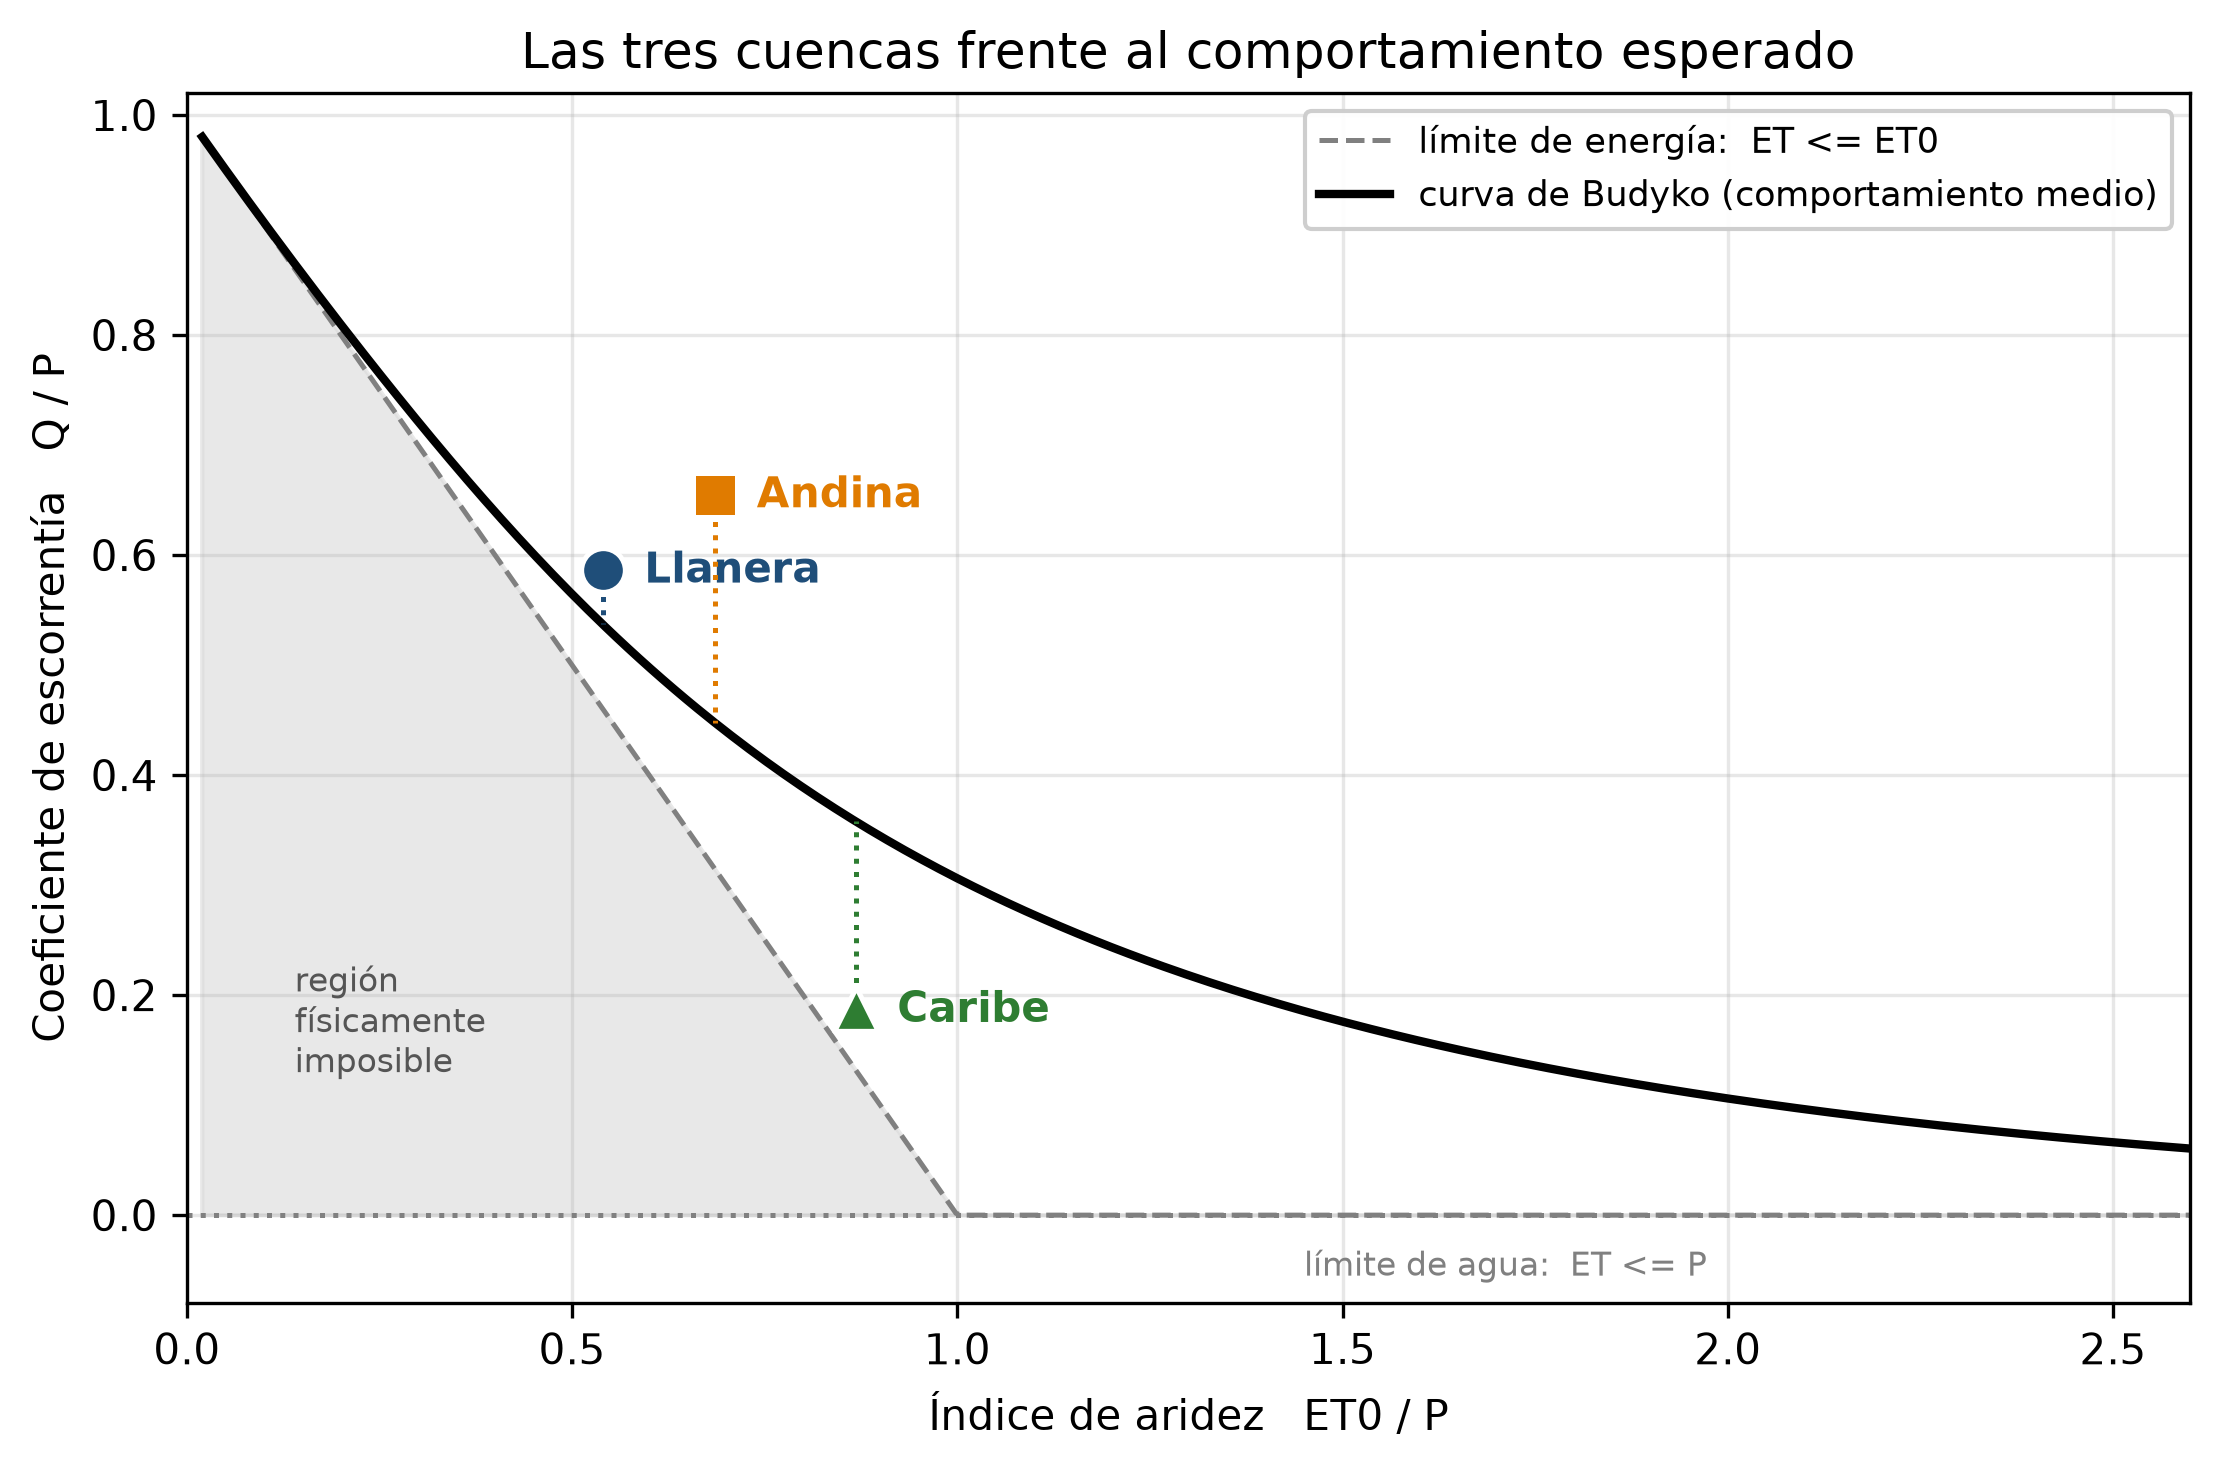

In [51]:
# Las tres cuencas sobre la curva de Budyko
phi = np.linspace(0.02, 3.0, 400)

fig, ax = plt.subplots(figsize=(7.5, 5))

# Región físicamente imposible: por debajo del límite de energía (exigiría ET > ET0)
ax.fill_between(phi, 0, np.clip(1 - phi, 0, 1), color="#d9d9d9", alpha=0.6, zorder=0)
ax.plot(phi, np.clip(1 - phi, 0, 1), color="grey", ls="--", lw=1.2,
        label="límite de energía:  ET <= ET0")
ax.axhline(0, color="grey", ls=":", lw=1.2)
ax.plot(phi, budyko_C(phi), color="k", lw=2.0, label="curva de Budyko (comportamiento medio)")

ax.text(0.14, 0.13, "región\nfísicamente\nimposible", fontsize=8, color="#555555")
ax.text(1.45, -0.055, "límite de agua:  ET <= P", fontsize=8, color="grey")

marcas = {"Llanera (Meta, 35127020)": ("o", "#1f4e79"),
          "Andina (Tolima, 21167080)": ("s", "#e07b00"),
          "Caribe (Cesar, 28037030)": ("^", "#2e7d32")}
for f in filas:
    m, c = marcas[f["cuenca"]]
    ax.scatter(f["aridez ET0/P"], f["C observado"], s=110, marker=m, color=c,
               edgecolor="white", linewidth=1.2, zorder=5)
    ax.annotate(f["cuenca"].split(" (")[0], (f["aridez ET0/P"], f["C observado"]),
                xytext=(10, -3), textcoords="offset points", fontsize=10, color=c, weight="bold")
    # segmento vertical hasta la curva: la distancia que hay que explicar
    ax.plot([f["aridez ET0/P"]] * 2, [f["C observado"], budyko_C(f["aridez ET0/P"])],
            color=c, ls=":", lw=1.2, zorder=4)

ax.set_xlabel("Índice de aridez   ET0 / P")
ax.set_ylabel("Coeficiente de escorrentía   Q / P")
ax.set_xlim(0, 2.6); ax.set_ylim(-0.08, 1.02)
ax.set_title("Las tres cuencas frente al comportamiento esperado")
ax.legend(fontsize=8.5, loc="upper right", framealpha=0.95)
plt.tight_layout(); plt.show()

**Qué dicen la tabla y la figura.**

Empiece por la columna `residuo / ET0`. En la cuenca del **Caribe** su valor es alrededor de **0.94**, de modo que el
residuo del balance implicaría que esa cuenca evapora el 94 % de todo lo que la atmósfera le demanda a
lo largo del año. En una cuenca con cuatro meses de menos de 35 mm/mes esa cifra es difícil de
sostener, porque durante esos meses la disponibilidad de agua, y no la demanda, es la que limita la
evapotranspiración. La lectura correcta no es "esta cuenca evapora
muchísimo", sino **"este residuo está absorbiendo algo que no es evapotranspiración"**. Compare con la
llanera (0.77) y la andina (0.50), que son valores más plausibles.

Y ahora la figura:

- **Llanera** cae prácticamente sobre la curva. Las tres series (lluvia, demanda atmosférica y caudal)
  son mutuamente coherentes. Es el conjunto de datos internamente consistente de los tres.
- **Andina** queda por **encima**. El río entrega más agua de la que su lluvia registrada puede
  justificar. Dado que la cuenca no puede generar agua, la explicación más probable es que CHIRPS
  subestime la precipitación real. Es un producto satelital calibrado con estaciones, y su desempeño se degrada en
  topografía compleja, donde la lluvia cambia mucho en pocos kilómetros.
- **Caribe** queda muy por **debajo**, con un caudal cercano a la mitad de lo esperado. Sumado al
  `residuo / ET0` de 0.94, la lectura es que una parte del agua **no llega al aforo**. Queda entonces
  la parte difícil, que consiste en proponer por dónde se va y descartar lo que se pueda descartar.

Hay dos candidatos, y conviene tratarlos como hipótesis y no como conclusiones:

1. **Captaciones aguas arriba.** La cobertura agropecuaria ocupa cerca del 32 % de la cuenca. Esa
   cifra por sí sola no explica nada, porque la cuenca andina tiene una fracción comparable, del 36 %,
   y no presenta déficit. Lo que distingue al Cesar es el contexto climático en que ocurre esa
   agricultura. Con un índice de aridez de 0.87, el más alto de las tres, y cuatro meses de menos de
   35 mm/mes, la producción agrícola en ese valle depende del riego, y el riego es una extracción neta
   que no retorna al cauce. Es un término sistemático, del signo correcto y de un orden de magnitud
   plausible. Confirmarlo exige el registro de concesiones de la autoridad ambiental, que no está en
   estos archivos.
2. **Flujo subterráneo hacia cuencas vecinas.** Bouaziz et al. (2018) documentan que ese término puede
   llegar al 10 % de la precipitación anual en promedio, y hasta el 25 %, y es invisible para cualquier
   balance superficial. No lo podemos descartar con los datos que tenemos.

Ninguno de los tres diagnósticos anteriores, uno por cuenca, salió de correr un modelo. **Los tres
salieron de contrastar los datos con una curva empírica, un límite físico y el conocimiento del
territorio**, que es lo que pide la caja *evaluar datos y necesidades de datos* antes de seguir
adelante.

> **Una advertencia sobre el método, no sobre las cuencas.** Todo lo anterior descansa en el supuesto de
> cierre. El enunciado defendible no es "a esta cuenca le falta la mitad del agua", sino que *el conjunto
> formado por la lluvia estimada, el caudal aforado y el supuesto de cierre es internamente incoherente*.
> Cuál de los tres es el que falla no lo resuelve el balance, lo resuelve ir a campo. Por eso el
> Ejercicio 6c le pide priorizar una campaña de medición y no un recalibrado.

## 6.4 Correr HYMOD en las tres cuencas

Estos parámetros salieron de una calibración automática sobre 2002–2005 (con 2001 como calentamiento),
usando la ET0 recalculada y **sin ningún factor de ajuste libre**. El período 2006–2008 no se usó para
calibrar.

Conviene advertir que el rango de búsqueda empleado aquí no es el mismo de la Parte 5. Las cuencas
colombianas son dos y tres órdenes de magnitud más grandes que la cuenca de ejemplo, de modo que la
búsqueda se hizo sobre $c_{max} \in [1, 1500]$ mm y no sobre $[1, 500]$ mm, mientras que los cuatro
rangos restantes se conservaron. Ese cambio tiene consecuencias que se discuten al final de esta misma
sección, cuando miremos los parámetros que resultaron.

In [52]:
# Parámetros calibrados de HYMOD para cada cuenca.
# Las asignaciones se mantienen en formato horizontal:
# cmax: capacidad máxima de almacenamiento del suelo (mm).
# b: distribución espacial de la capacidad de almacenamiento.
# alpha: fracción del exceso de agua dirigida al flujo rápido.
# Ks: coeficiente de descarga del almacenamiento lento.
# Kq: coeficiente de descarga de los almacenamientos rápidos.
PAR_COL = {
    "Llanera (Meta, 35127020)":  dict(cmax=365.21, b=0.231, alpha=0.390, Ks=0.0340, Kq=0.297),
    "Andina (Tolima, 21167080)": dict(cmax=58.73,  b=0.716, alpha=0.366, Ks=0.0510, Kq=0.980),
    "Caribe (Cesar, 28037030)":  dict(cmax=946.14, b=0.131, alpha=0.432, Ks=0.0010, Kq=0.393),
}

# Periodo utilizado para calibrar los parámetros del modelo.
CAL_COL = slice("2002-01-01", "2005-12-31")

# Periodo independiente de aceptabilidad o validación.
# Estos años no se utilizaron durante la calibración.
ACE_COL = slice("2006-01-01", "2008-12-31")

# Diccionario donde se almacenarán las métricas de cada cuenca.
resultados = {}

# Recorre las tres cuencas contenidas en el diccionario col.
for nombre, d in col.items():

    # Ejecuta HYMOD con P y ET0 como entradas y con los parámetros
    # calibrados correspondientes a la cuenca analizada.
    d["Q_sim"] = hymod(d["P_mm"].values, d["ET0_mm"].values, **PAR_COL[nombre])

    # Calcula el KGE del periodo de aceptabilidad y sus componentes:
    # r: correlación temporal.
    # beta: relación entre los volúmenes simulado y observado.
    # gamma: relación entre sus coeficientes de variación.
    k, r_, beta, gamma = kge(d.loc[ACE_COL, "Q_mm"], d.loc[ACE_COL, "Q_sim"], componentes=True)

    # Calcula y almacena las métricas de evaluación.
    resultados[nombre] = {

        # Desempeño diario durante el periodo utilizado para calibrar.
        "NSE cal (diario)":  nse(d.loc[CAL_COL, "Q_mm"], d.loc[CAL_COL, "Q_sim"]),

        # Desempeño diario durante el periodo independiente.
        "NSE ace (diario)":  nse(d.loc[ACE_COL, "Q_mm"], d.loc[ACE_COL, "Q_sim"]),

        # Desempeño de los caudales medios mensuales en aceptabilidad.
        # La agregación mensual reduce la influencia de errores diarios.
        "NSE ace (mensual)": nse(d.loc[ACE_COL, "Q_mm"].resample("MS").mean(),
                                 d.loc[ACE_COL, "Q_sim"].resample("MS").mean()),

        # KGE total y componentes calculados en aceptabilidad.
        "KGE ace":           k,
        "r":                 r_,
        "beta (volumen)":    beta,
        "gamma (variabilid.)": gamma,

        # Sesgo porcentual del volumen:
        # positivo indica sobreestimación y negativo, subestimación.
        "PBIAS ace (%)":     pbias(d.loc[ACE_COL, "Q_mm"], d.loc[ACE_COL, "Q_sim"]),

        # Variabilidad relativa de los caudales observados.
        "CV observado":      d.loc[ACE_COL, "Q_mm"].std() / d.loc[ACE_COL, "Q_mm"].mean(),
    }

# Convierte los resultados en una tabla:
# cada fila corresponde a una cuenca y cada columna a una métrica.
pd.DataFrame(resultados).T.round(3)

,NSE cal (diario),NSE ace (diario),NSE ace (mensual),KGE ace,r,beta (volumen),gamma (variabilid.),PBIAS ace (%),CV observado
"Llanera (Meta, 35127020)",0.809,0.832,0.939,0.860,0.915,0.957,0.897,-4.260,0.863
"Andina (Tolima, 21167080)",0.404,0.278,0.781,0.583,0.599,0.889,0.973,-11.080,1.109
"Caribe (Cesar, 28037030)",0.651,0.429,0.492,0.373,0.684,1.256,0.523,25.629,1.318


**Antes de mirar los hidrogramas, compare las dos primeras columnas de métricas con calma.**

Por NSE, la cuenca del **Caribe (0.43)** parece mejor modelada que la **andina (0.28)**. Por KGE el
orden se invierte, con **0.37 contra 0.58**, y el Caribe queda de último. Cuando dos funciones objetivo
razonables producen órdenes opuestos, el criterio para decidir cuál sospechar no es la preferencia del
analista sino cuál de las dos tiene un defecto documentado en esa situación.

El NSE compara el modelo contra **la media de lo observado**, de modo que su denominador es la varianza
de la serie. Obsérvese la última columna. El coeficiente de variación del Caribe vale **1.32**, el más
alto de los tres, porque esa cuenca pasa cuatro meses cerca de cero y luego sube a 6 mm/día. El NSE es
una medida de habilidad relativa a ese referente, y el referente es más fácil de superar cuanto más
variable sea la serie observada. La consecuencia, ya señalada por Schaefli y Gupta (2007), es que
**el NSE no es comparable entre cuencas cuya variabilidad observada difiere**, porque el mismo valor
numérico corresponde a exigencias distintas. Comparar el 0.43 del Caribe con el 0.28 de la andina, sin
más, no tiene sentido.

El KGE no comparte ese defecto, porque separa los tres errores en lugar de agregarlos, y aquí localiza
el problema.

- `gamma = 0.52`, es decir, el coeficiente de variación simulado es la mitad del observado. Como
  $\gamma$ es una razón de coeficientes de variación y $\beta$ vale 1.26, la razón de desviaciones
  estándar resulta $\gamma\beta = 0.66$.
- `beta = 1.26`, es decir, el modelo sobreestima además el volumen en un 26 %.

En conjunto, ambos componentes indican que el modelo **aplanó la señal**, que es lo que se observa en
el hidrograma de la celda siguiente. De ahí se sigue una recomendación general. *Un NSE alto en una
cuenca muy estacional aporta poca información sobre la calidad del modelo. Conviene pedir siempre el
KGE descompuesto, o comparar contra un referente más exigente que la media, como la climatología del
propio río.*

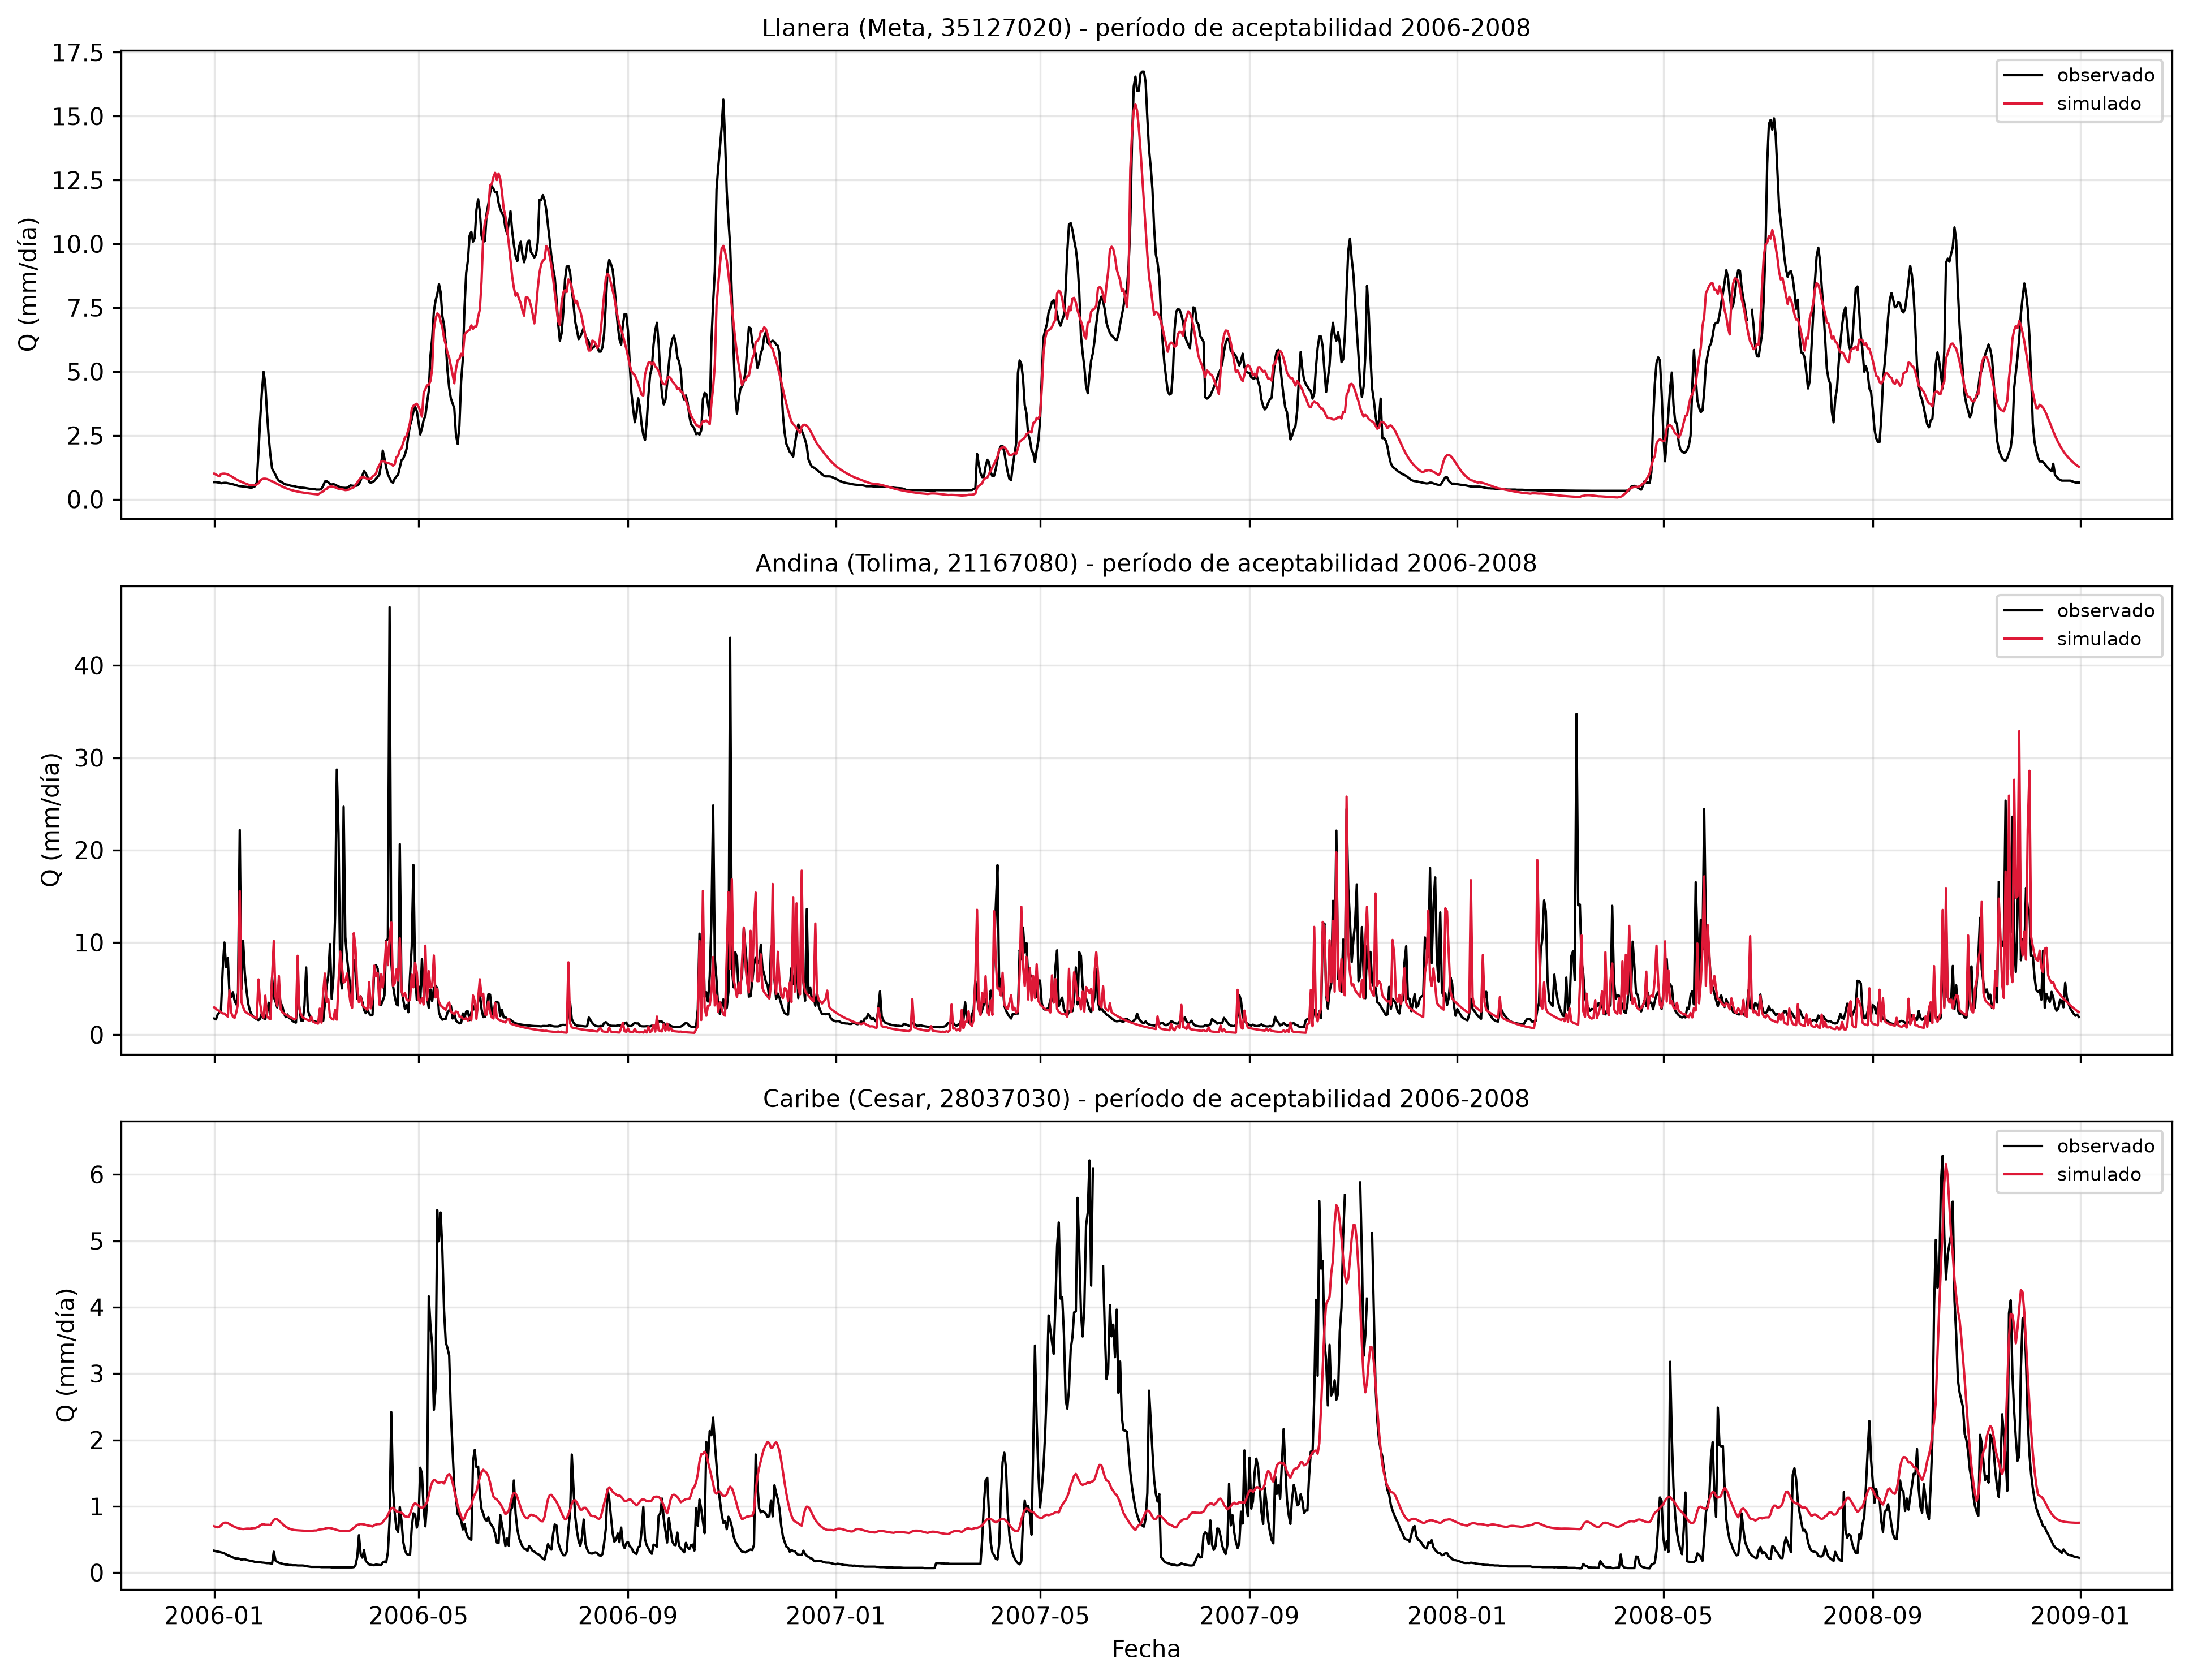

In [53]:
# Crea tres gráficos verticales con un eje temporal compartido.
fig, axs = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

# Recorre simultáneamente cada eje y cada cuenca.
for ax, (nombre, d) in zip(axs, col.items()):

    # Selecciona el periodo independiente de aceptabilidad: 2006-2008.
    v = d.loc[ACE_COL]

    # Grafica el caudal observado en negro.
    ax.plot(v.index, v["Q_mm"], color="k", lw=1.0, label="observado")

    # Grafica el caudal simulado por HYMOD en rojo.
    ax.plot(v.index, v["Q_sim"], color="#de1937", lw=1.0, label="simulado")

    # Define las unidades del eje vertical.
    ax.set_ylabel("Q (mm/día)")

    # Identifica la cuenca y el periodo evaluado.
    ax.set_title(f"{nombre} - período de aceptabilidad 2006-2008", fontsize=10)

    # Muestra la identificación de las series.
    ax.legend(fontsize=8)

# Coloca el nombre del eje temporal en el gráfico inferior.
axs[-1].set_xlabel("Fecha")

# Ajusta los espacios y muestra la figura.
plt.tight_layout(); plt.show()

**Una última mirada a los parámetros calibrados**, tan informativa como el NSE. La columna
$S_{max} = c_{max}/(b+1)$ es la capacidad de almacenamiento promediada sobre la cuenca que el modelo
necesita para reproducir el caudal observado.

| | `cmax` | `b` | `alpha` | `Ks` | `Kq` | $S_{max}$ |
|---|---|---|---|---|---|---|
| Llanera | 365 | 0.23 | 0.39 | 0.034 | 0.30 | 297 mm |
| Andina | 59 | 0.72 | 0.37 | 0.051 | 0.98 | 34 mm |
| Caribe | 946 | 0.13 | 0.43 | **0.001** ⚠ | 0.39 | **837 mm** ⚠ |

En la cuenca del Caribe la calibración exige un almacenamiento de 837 mm y empuja `Ks` contra el
**piso** de su rango, es decir, un embalse lento que prácticamente no descarga. Esa es la causa
mecánica del aplanamiento que identificó el KGE. Con `Ks` tan bajo el agua queda retenida y sale como
una descarga casi constante, que sostiene un flujo base inexistente durante la estación seca y no queda
disponible para los picos.

Cuando un parámetro calibrado se pega al borde de su rango, rara vez significa que haya que ampliar el
rango. Con más frecuencia significa que el modelo está compensando, con un valor no identificable, algo
que ocurre **fuera** del modelo. La hipótesis más simple aquí es el agua que se extrae aguas arriba, un
término que HYMOD no representa.

Compare con la cuenca andina, con 34 mm de almacenamiento, un valor compatible con un suelo de ladera
delgado. Los parámetros de un modelo conceptual no se miden en campo, pero cuando toman valores que el
clima de la cuenca no puede sostener están informando algo sobre el conjunto de datos.

---
## ✏️ Ejercicio 6: Cierre

**6a.** La cuenca que cae sobre la curva de Budyko es también la que el modelo reproduce mejor. Ponga
esa observación a prueba antes de creérsela:

1. Ordene las tres cuencas por su desviación respecto de la curva usando la **diferencia**
   $|C_{obs} - C_{esperado}|$, y después usando la **razón** $C_{obs}/C_{esperado}$. ¿Sale el mismo
   orden?
2. Compare cada orden con el de `NSE ace (diario)`.
3. Con tres cuencas, ¿qué puede afirmar y qué no puede afirmar? Escriba una frase que sea defendible
   ante alguien que le pregunte "¿y eso con cuántos casos lo comprobó?".

> ✏️ 
### 6a — Paso 1: entender qué se debe comparar

La pregunta solicita ordenar las cuencas mediante tres criterios:

Diferencia absoluta respecto a Budyko:
$$ D_C=\left|C_{\mathrm{obs}}-C_{\mathrm{esperado}}\right| $$

Cuanto menor sea \(D_C\), más cerca está la cuenca de la curva.

Razón respecto a Budyko:
$$ R_C=\frac{C_{\mathrm{obs}}}{C_{\mathrm{esperado}}} $$

El valor ideal es 1. Para ordenar por cercanía utilizaremos:

$$ D_R=\left|R_C-1\right| $$
NSE diario de aceptabilidad:

Aquí un valor mayor indica mejor desempeño según NSE.

### 6a.2 Comparación con el NSE diario _  Comparación NSE - ACE, y Ordenamiento

| Cuenca | C observado | C esperado | Diferencia absoluta | Razón Cobs/Cesp | Desviación de la razón | NSE diario |
|---|---:|---:|---:|---:|---:|---:|
| Llanera | 0.586 | 0.537 | 0.049 | 1.092 | 0.092 | 0.832 |
| Andina | 0.655 | 0.447 | 0.207 | 1.463 | 0.463 | 0.278 |
| Caribe | 0.187 | 0.358 | 0.171 | 0.522 | 0.478 | 0.429 |

Por diferencia absoluta, el orden es **Llanera–Caribe–Andina**, igual al orden del NSE diario de mayor a menor: 0.832, 0.429 y 0.278. En cambio, según la cercanía de la razón a 1, el orden es **Llanera–Andina–Caribe**. Por tanto, la diferencia absoluta coincide completamente con el NSE, mientras que la razón solo coincide en el primer lugar.

### 6a.3
> ✏️
 En las tres cuencas analizadas, el orden basado en la diferencia respecto a Budyko coincidió con el orden del NSE diario, y la cuenca Llanera fue la más cercana a la curva y la de mejor desempeño. Sin embargo, el orden no coincidió completamente al utilizar la razón y, con solo tres casos, no puede afirmarse que la cercanía a Budyko determine o prediga la calidad y acertividad del modelo. El resultado constituye únicamente una evidencia descriptiva para estas tres cuencas y tendría que verificarse con una muestra mayor.

**6b. En la cuenca andina el NSE ace (diario) es bajo, pero el NSE ace (mensual) es alto. Relacione ese contraste con la diapositiva del protocolo que ordena la evaluación así: (1) volumen anual, (2) volúmenes estacionales, (3) caudales semanales y diarios, (4) hidrogramas de creciente, con énfasis inicial en 1 y 2. ¿Por qué ese orden y no el contrario?

### 6b
> ✏️
 En la cuenca Andina, el NSE diario es bajo (0.278), mientras que el NSE mensual alcanza 0.781. Esto sugiere que el modelo representa de manera aceptable el comportamiento general de los volúmenes a lo largo del año, pero puede no ser tan confiable para reproducir con precisión momento y magnitud de variaciones diarias. Al promediar mensualmente, parte de los errores diarios de anticipación, retraso o magnitud de los picos se compensan, y por eso el desempeño mejora.

 Este resultado ayuda a entender el orden propuesto en el protocolo. Primero se revisan el volumen anual y los volúmenes estacionales porque permiten comprobar si el modelo representa adecuadamente la cantidad total de agua y su distribución entre temporadas húmedas y secas. Si esa base no es consistente, no tendría mucho sentido ajustar todavía los caudales diarios o las crecientes. Una vez que el balance general es razonable, se puede avanzar hacia ajustes más finos relacionados con la sincronización y la forma de los hidrogramas.

   Evaluar en el orden contrario podría llevar a reproducir algunos picos diarios mediante compensaciones entre parámetros, aunque el volumen total o el funcionamiento interno del modelo sean incorrectos. En otras palabras, se podría obtener una respuesta aparentemente buena por razones equivocadas, que es precisamente la advertencia planteada en la diapositiva siguiente del protocolo.
 

**6c.** Usted debe entregar un estudio de disponibilidad hídrica para la cuenca del **Cesar**. Con lo
que vio hoy, escriba tres líneas dirigidas al cliente: qué le puede garantizar del modelo, qué no, y qué
dato conseguiría primero si tuviera presupuesto para una sola campaña de campo.

> ### 6c
> ✏️
 Con los datos disponibles, el modelo representa de manera preliminar los regimenes de caudales (estacionalidad), identificar si la modalidad es "monomodal, bimodal, o multimodal", asi mismo representar los periodos de mayor y menor disponibilidad hidrica "caudal"

 No es posible garantizar o asegurar que el modelo represente la magnitud de caudales disponible en periodos baja precipitación, o eventos extremos, teniendo en cuenta que en aceptabilidad se sobreestima un 25.6% (como se leyo de la caja de codigo 6.4) 

Realizaría una campaña de aforos simultáneos durante el estiaje para medir el caudal del río, las principales captaciones, los retornos y los aportes tributarios. Con este balance se podría cuantificar un caudal extraído y establecer qué parte de la diferencia observada corresponde a usos del agua no representados actualmente por el modelo.

In [54]:
# Confirma si se ha corrido y cuantos intentos se han registrado, se sobreescriben y mantiene el mismo contador si no se crean como pruebas nuevas_GAB.
print("Intentos registrados:", len(bitacora))

Intentos registrados: 7


In [55]:
# Codigo generado con ayuda de IA_Para dar respuesta a 6.a.2
# Construye una tabla con los coeficientes observados y esperados según Budyko.
tabla_6a = pd.DataFrame(filas).set_index("cuenca")[["C observado", "C esperado (Budyko)", "C obs / C esperado"]].copy()

# Calcula la distancia absoluta entre el coeficiente observado y la curva de Budyko.
# Un valor cercano a cero indica mayor consistencia con Budyko.
tabla_6a["|Cobs - Cesp|"] = abs(tabla_6a["C observado"] - tabla_6a["C esperado (Budyko)"])

# Calcula la distancia de la razón respecto al valor ideal de 1.
# Una razón de 1 significa que C observado coincide con C esperado.
tabla_6a["|razón - 1|"] = abs(tabla_6a["C obs / C esperado"] - 1)

# Incorpora el NSE diario del periodo independiente de aceptabilidad.
tabla_6a["NSE ace (diario)"] = pd.Series({nombre: resultados[nombre]["NSE ace (diario)"] for nombre in resultados})

# Asigna el orden de cercanía según la diferencia absoluta:
# 1 corresponde a la cuenca más cercana a Budyko.
tabla_6a["orden diferencia"] = tabla_6a["|Cobs - Cesp|"].rank(ascending=True, method="min").astype(int)

# Asigna el orden de cercanía según la razón:
# 1 corresponde a la razón más cercana a 1.
tabla_6a["orden razón"] = tabla_6a["|razón - 1|"].rank(ascending=True, method="min").astype(int)

# Ordena el NSE de mayor a menor:
# 1 corresponde al NSE diario más alto.
tabla_6a["orden NSE"] = tabla_6a["NSE ace (diario)"].rank(ascending=False, method="min").astype(int)

# Muestra la tabla final con tres cifras decimales.
tabla_6a.round(3)

,C observado,C esperado (Budyko),C obs / C esperado,|Cobs - Cesp|,|razón - 1|,NSE ace (diario),orden diferencia,orden razón,orden NSE
cuenca,,,,,,,,,
"Llanera (Meta, 35127020)",0.586,0.537,1.092,0.049,0.092,0.832,1,1,1
"Andina (Tolima, 21167080)",0.655,0.447,1.463,0.207,0.463,0.278,3,2,3
"Caribe (Cesar, 28037030)",0.187,0.358,0.522,0.171,0.478,0.429,2,3,2


---
# Entrega

Guarde el cuaderno (`Ctrl + S`), **reinicie el kernel y córralo completo de arriba a abajo** para
verificar que no queda ningún error (`Run All`). Después, desde la terminal de VS Code, en la carpeta
del repositorio:

```bash
conda activate hidro
git status                      # revise que solo aparezca lo que quiere subir
git add notebooks/ resultados/
git commit -m "Taller 1 resuelto"
git push
```

Si es la primera vez que sube este repositorio, siga las instrucciones del `README.md`.

**Lista de verificación antes de entregar:**

- [ ] El cuaderno corre completo sin errores, con el kernel reiniciado.
- [ ] Las seis celdas ✏️ de código están completas (Ejercicios 1a, 2 y los cuatro intentos de 5a).
- [ ] Las diez respuestas escritas ✏️ están redactadas (1b, 3a, 3b, 4a, 4b, 4c, 5b, 6a, 6b, 6c).
- [ ] La bitácora de calibración tiene al menos siete intentos con su nota correspondiente.
- [ ] El repositorio **no** incluye la carpeta `datos/` con archivos pesados que no sean los del taller.
- [ ] El repositorio es público, o privado con el profesor agregado como colaborador.

---

### Fuentes de los datos

- **Cuenca de ejemplo (Partes 2 a 5):** conjunto `hymod_input.csv` distribuido con SPOTPY.
  Houska, T., Kraft, P., Chamorro-Chavez, A. & Breuer, L. (2015). *SPOTting Model Parameters Using a
  Ready-Made Python Package.* PLoS ONE 10(12): e0145180.
- **Cuencas colombianas (Parte 6):** Jiménez, D. A. et al. (2025). *CAMELS-COL: A Large-Sample
  Hydrometeorological Dataset for Colombia.* Earth System Science Data (en revisión).
  Datos bajo licencia CC-BY 4.0, disponibles en Zenodo: https://zenodo.org/records/18794895
- **Modelo HYMOD:** Boyle (2001); Wagener et al. (2001). Implementación adaptada de la versión en
  Python incluida en SPOTPY.
- **Balance hídrico y supuesto de cierre:** Dingman, S. L. (2015). *Physical Hydrology*, 3.ª ed.
  Senay, G. B. et al. (2011). *Estimating basin scale evapotranspiration (ET) by water balance and
  remote sensing methods.* Hydrological Processes, 25(26), 4037–4049.
- **Flujo subterráneo entre cuencas:** Bouaziz, L. et al. (2018). *Redressing the balance: quantifying
  net intercatchment groundwater flows.* Hydrology and Earth System Sciences, 22, 6415–6434.
- **Marco de Budyko:** Budyko, M. I. (1974). *Climate and Life.* Academic Press.
- **Funciones objetivo.** Nash, J. E. & Sutcliffe, J. V. (1970). *River flow forecasting through
  conceptual models part I.* Journal of Hydrology, 10(3), 282–290. Gupta, H. V., Kling, H., Yilmaz,
  K. K. & Martinez, G. F. (2009). *Decomposition of the mean squared error and NSE performance
  criteria.* Journal of Hydrology, 377(1–2), 80–91.
- **Límites de interpretación del NSE y del KGE.** Schaefli, B. & Gupta, H. V. (2007). *Do Nash values
  have value?* Hydrological Processes, 21(15), 2075–2080. Knoben, W. J. M., Freer, J. E. & Woods, R. A.
  (2019). *Technical note: Inherent benchmark or not? Comparing Nash-Sutcliffe and Kling-Gupta
  efficiency scores.* Hydrology and Earth System Sciences, 23, 4323–4331.
- **Función de distribución de almacenamiento (bloque 1 de HYMOD).** Moore, R. J. (1985). *The
  probability-distributed principle and runoff production at point and basin scales.* Hydrological
  Sciences Journal, 30(2), 273–297.
- **Almacenamiento en la zona radicular a partir del déficit climático acumulado.** Gao, H.,
  Hrachowitz, M., Schymanski, S. J., Fenicia, F., Sriwongsitanon, N. & Savenije, H. H. G. (2014).
  *Climate controls how ecosystems size their root zone storage capacity at catchment scale.*
  Geophysical Research Letters, 41(22), 7916–7923.
- **Equifinalidad.** Beven, K. & Freer, J. (2001). *Equifinality, data assimilation, and uncertainty
  estimation in mechanistic modelling of complex environmental systems.* Journal of Hydrology,
  249(1–4), 11–29.
- **Evapotranspiración de referencia:** Hargreaves, G. H. & Samani, Z. A. (1985). *Reference crop
  evapotranspiration from temperature.* Applied Engineering in Agriculture, 1(2), 96–99.
  Allen, R. G. et al. (1998). *Crop evapotranspiration.* FAO Irrigation and Drainage Paper 56
  (ecuaciones 21 a 25 para la radiación extraterrestre).